# Assignment 3. Natural Language Processing

Полное решение четырёх заданий. Пояснения на русском, исходные корпуса сохраняют свои языки.
Код обучает и сравнивает модели, рассчитывает метрики, сохраняет графики и анализирует реальные ошибки.

**Воспроизводимость.** Random seed: 42. Python: 3.12. Точные версии находятся в `requirements-lock.txt`.
Источники, лицензии и контрольные суммы приведены в разделах заданий и файлах результатов.
Обучение TF-IDF выполняется только на обучающей части. Порог VADER и параметры ML выбираются по validation;
лучшая конфигурация определения языка выбирается перекрёстной проверкой внутри train.

**Запуск.** Распаковать весь архив, установить `pip install -r requirements.txt`, открыть этот ноутбук
и выполнить ячейки по порядку. Первый запуск загружает открытые данные, ресурсы NLTK и веса моделей.
Для повторного запуска в этой папке уже сохранены исходные данные и результаты; веса хранятся отдельно в `.cache`.
Сохранённые выходы позволяют просмотреть работу без повторного запуска.

Для суммаризации по согласованию использован готовый корпус Multi-News с человеческим эталоном.
Наблюдаемые результаты относятся к выбранным корпусам и одному фиксированному разбиению.


In [1]:
from pathlib import Path
import sys, json, platform, importlib.metadata, os
ROOT = Path.cwd()
if not (ROOT / 'task1_sentiment.py').exists() and (ROOT / 'assignment3').is_dir():
    ROOT = ROOT / 'assignment3'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache' / 'matplotlib'))
print('Python:', sys.version)
print('Seed: 42')
for package in ['numpy','pandas','scikit-learn','scipy','matplotlib','nltk','torch','transformers','fasttext-predict','rouge-score']:
    try:
        print(package, importlib.metadata.version(package))
    except importlib.metadata.PackageNotFoundError:
        print(package, 'not installed')


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)]
Seed: 42
numpy 2.5.3
pandas 3.0.6
scikit-learn not installed
scipy 1.18.1
matplotlib 3.11.2
nltk not installed
torch not installed
transformers not installed
fasttext-predict not installed
rouge-score not installed


## 1. Анализ тональности

**Данные:** [Financial PhraseBank](https://huggingface.co/datasets/takala/financial_phrasebank),
Sentences_50Agree, CC BY-NC-SA 3.0 (Malo et al., 2014). После удаления дублей: 4 836 предложений;
negative=604, neutral=2 871, positive=1 361. Это финансовые новости с оценкой влияния на компанию.
Разбиение 70/15/15, стратификация, seed=42.

**Методы:** VADER (пороги по validation), TF-IDF + Logistic Regression (два C и две предобработки),
[Twitter RoBERTa](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment) без дообучения.
TF-IDF сам приводит слова к нижнему регистру. Альтернативная обработка дополнительно удаляет символы,
стоп-слова и лемматизирует с учётом POS; отрицания сохраняются. Для VADER и RoBERTa оставлены регистр,
пунктуация и исходная формулировка. Числа и служебные слова могут быть полезны для финансовых сравнений,
поэтому сильная очистка рассматривается как проверяемая гипотеза.

**Демонстрация:** после расчёта доступна `t1_predict_text("Your own sentence")`.
Созданные для демонстрации примеры не входят в метрики. Один из них иллюстрирует возможный сарказм;
в анализе тестовых ошибок сарказм не утверждается без разметки.

В ячейках ниже содержится полная реализация. После запуска показаны рассчитанные результаты и их интерпретация.

In [2]:
"""Задание 1: три подхода к анализу тональности, реальные эксперименты."""
from pathlib import Path
import os
import re
import json
import hashlib
import urllib.request
import zipfile
import random

ROOT = Path.cwd()
if not (ROOT / 'task1_sentiment.py').exists() and (ROOT / 'assignment3').is_dir():
    ROOT = ROOT / 'assignment3'
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache' / 'matplotlib'))
os.environ.setdefault('HF_HOME', str(ROOT / '.cache' / 'huggingface'))
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
os.environ.setdefault('NLTK_DATA', str(ROOT / '.cache' / 'nltk_data'))


In [3]:
def t1_download(url, path):
    """Сохраняем исходные данные локально; повторный запуск использует копию."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists():
        print('Download:', url, flush=True)
        request = urllib.request.Request(url, headers={'User-Agent': 'NLP-coursework/1.0'})
        with urllib.request.urlopen(request, timeout=180) as response:
            path.write_bytes(response.read())
    return path


In [4]:
def t1_predict_text(text):
    """Классифицировать свой текст после выполнения t1_main()."""
    import torch
    state = globals().get('_T1_RUNTIME')
    if state is None:
        raise RuntimeError('Сначала выполните t1_main().')
    compound = state['vader'].polarity_scores(text)['compound']
    low, high = state['thresholds']
    lexical = 'negative' if compound <= low else ('positive' if compound >= high else 'neutral')
    ml_text = text if state['preprocessing'] == 'minimal' else state['clean'](text)
    ml_label = state['ml'].predict([ml_text])[0]
    with torch.inference_mode():
        inputs = state['tokenizer']([text],padding=True,truncation=True,max_length=192,return_tensors='pt')
        probability = state['transformer'](**inputs).logits.softmax(-1)[0]
    return {'text':text,'VADER':lexical,'vader_compound':compound,'TFIDF_LogReg':str(ml_label),
            'RoBERTa_TweetEval':state['labels'][int(probability.argmax())],
            'transformer_confidence':float(probability.max())}


In [5]:
def t1_main():
    import numpy as np
    import pandas as pd
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    import nltk
    from nltk.corpus import stopwords, wordnet
    from nltk.sentiment import SentimentIntensityAnalyzer
    from nltk.stem import WordNetLemmatizer
    from sklearn.model_selection import train_test_split
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                                 f1_score, confusion_matrix, ConfusionMatrixDisplay)
    from scipy.stats import binomtest
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    from huggingface_hub import snapshot_download, HfApi

    seed = 42
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(2)
    out = ROOT / 'results' / 'task1'
    data = ROOT / 'data' / 'task1'
    out.mkdir(parents=True, exist_ok=True)
    data.mkdir(parents=True, exist_ok=True)
    nltk.data.path.insert(0, os.environ['NLTK_DATA'])
    for resource, location in [('stopwords','corpora/stopwords'), ('wordnet','corpora/wordnet.zip'),
                               ('averaged_perceptron_tagger_eng','taggers/averaged_perceptron_tagger_eng'),
                               ('vader_lexicon','sentiment/vader_lexicon.zip')]:
        try:
            nltk.data.find(location)
        except LookupError:
            if not nltk.download(resource, download_dir=os.environ['NLTK_DATA'], quiet=True):
                raise RuntimeError('Cannot obtain NLTK resource: ' + resource)

    # Используем исходный ZIP, поскольку старый загрузочный скрипт datasets устарел.
    dataset_url = 'https://huggingface.co/datasets/takala/financial_phrasebank/resolve/main/data/FinancialPhraseBank-v1.0.zip'
    archive = t1_download(dataset_url, data / 'FinancialPhraseBank-v1.0.zip')
    with zipfile.ZipFile(archive) as z:
        member = next(n for n in z.namelist() if n.endswith('Sentences_50Agree.txt'))
        lines = z.read(member).decode('latin-1').splitlines()
    rows = [line.rsplit('@', 1) for line in lines if '@' in line]
    df = pd.DataFrame(rows, columns=['text', 'label'])
    df['label'] = df.label.str.strip()
    df['text'] = df.text.str.replace(r'\s+', ' ', regex=True).str.strip()
    raw_count = len(df)
    df['key'] = df.text.str.casefold().str.replace(r'\s+', ' ', regex=True)
    conflicts = df.groupby('key').label.nunique()
    bad_keys = set(conflicts[conflicts > 1].index)
    df = df[~df.key.isin(bad_keys)].drop_duplicates('key').reset_index(drop=True)
    labels = ['negative', 'neutral', 'positive']
    assert len(df) >= 3000 and df.label.value_counts().min() >= 500
    train, remainder = train_test_split(df, test_size=.30, random_state=seed, stratify=df.label)
    val, test = train_test_split(remainder, test_size=.50, random_state=seed, stratify=remainder.label)
    assert not set(train.key) & set(val.key) and not set(train.key) & set(test.key) and not set(val.key) & set(test.key)
    for name, part in [('train', train), ('validation', val), ('test', test)]:
        part.to_csv(data / (name + '.csv'), index=False)
    counts = pd.DataFrame({name: part.label.value_counts() for name, part in [('all',df),('train',train),('validation',val),('test',test)]}).reindex(labels)
    counts.to_csv(out / 'class_counts.csv')
    ax = counts[['train','validation','test']].plot.bar(figsize=(8,4), rot=0)
    ax.set(xlabel='Sentiment', ylabel='Number of texts', title='Financial PhraseBank: disjoint splits')
    plt.tight_layout(); plt.savefig(out / 'class_distribution.png', dpi=150); plt.close()
    print('Dataset:', counts.to_string(), flush=True)

    # Отрицания сохраняются. Словарю и Transformer передаём исходный текст.
    negations = {'no', 'nor', 'not', 'never', 'neither', 'nothing', 'without'}
    stops = set(stopwords.words('english')) - negations
    lemma = WordNetLemmatizer()
    def clean_ml(text):
        text = text.lower().replace("can't", 'can not').replace("won't", 'will not')
        text = re.sub(r"n['’]t\b", ' not', text)
        tokens = re.findall(r'[a-z]+', text)
        tagged = nltk.pos_tag(tokens)
        return ' '.join(lemma.lemmatize(w, {'J':'a','V':'v','N':'n','R':'r'}.get(pos[0], 'n'))
                        for w, pos in tagged if w not in stops)
    # Лемматизация не обучается на тестовых данных; TF-IDF обучаем только на train.
    processed = {name: [clean_ml(t) for t in part.text] for name,part in [('train',train),('validation',val),('test',test)]}
    pd.DataFrame({'original': train.text.head(8).to_list(), 'lemma_stopwords': processed['train'][:8]}).to_csv(out / 'preprocessing_examples.csv',index=False)

    analyzer = SentimentIntensityAnalyzer()
    vader_val = np.array([analyzer.polarity_scores(t)['compound'] for t in val.text])
    def vader_class(scores, low, high):
        return np.where(scores <= low, 'negative', np.where(scores >= high, 'positive', 'neutral'))
    threshold_rows = []
    for low, high in [(-.05,.05),(-.10,.10),(-.20,.20),(-.35,.35)]:
        threshold_rows.append({'low':low,'high':high,'validation_macro_f1':f1_score(val.label,vader_class(vader_val,low,high),average='macro')})
    threshold_table = pd.DataFrame(threshold_rows)
    threshold_table.to_csv(out / 'vader_validation.csv',index=False)
    best_vader = threshold_table.sort_values('validation_macro_f1',ascending=False,kind='stable').iloc[0]
    test_compound = np.array([analyzer.polarity_scores(t)['compound'] for t in test.text])
    predictions = {'VADER':vader_class(test_compound,best_vader.low,best_vader.high)}

    candidates = []
    fitted = {}
    for preprocessing in ['minimal', 'lemma_stopwords']:
        xtr = train.text.to_list() if preprocessing == 'minimal' else processed['train']
        xval = val.text.to_list() if preprocessing == 'minimal' else processed['validation']
        for c in [.5, 2.0]:
            name = preprocessing + '_C' + str(c)
            pipeline = Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True,max_features=30000)),
                                 ('model',LogisticRegression(C=c,class_weight='balanced',max_iter=1000,random_state=seed))])
            pipeline.fit(xtr,train.label)
            score = f1_score(val.label,pipeline.predict(xval),average='macro')
            candidates.append({'configuration':name,'preprocessing':preprocessing,'C':c,'validation_macro_f1':score})
            fitted[name] = pipeline
    validation_table = pd.DataFrame(candidates)
    validation_table.to_csv(out / 'ml_validation.csv',index=False)
    best_ml = validation_table.sort_values('validation_macro_f1',ascending=False,kind='stable').iloc[0]
    classifier = fitted[best_ml.configuration]
    xtest = test.text.to_list() if best_ml.preprocessing == 'minimal' else processed['test']
    predictions['TFIDF_LogReg'] = classifier.predict(xtest)
    print('Validation selection:',best_ml.to_dict(),flush=True)

    # Модель обучена на TweetEval, а оценка здесь на Financial PhraseBank.
    # У FinBERT возможно пересечение с обучением на размеченном PhraseBank.
    model_id = 'cardiffnlp/twitter-roberta-base-sentiment'
    model_dir = ROOT / '.cache' / 'models' / 'sentiment'
    revision_file = model_dir / 'revision.txt'
    if not (model_dir / 'config.json').exists() or not any((model_dir / n).exists() and (model_dir / n).stat().st_size > 1000000 for n in ['model.safetensors','pytorch_model.bin']):
        info = HfApi().model_info(model_id)
        filenames = [f.rfilename for f in info.siblings]
        weights = 'model.safetensors' if 'model.safetensors' in filenames else 'pytorch_model.bin'
        snapshot_download(model_id,revision=info.sha,local_dir=model_dir,
                          allow_patterns=['config.json','merges.txt','vocab.json','tokenizer*','special_tokens_map.json',weights])
        revision_file.write_text(info.sha,encoding='utf-8')
    revision = revision_file.read_text(encoding='utf-8').strip()
    tokenizer = AutoTokenizer.from_pretrained(model_dir,local_files_only=True)
    transformer = AutoModelForSequenceClassification.from_pretrained(model_dir,local_files_only=True)
    transformer.eval()
    transformer_pred, confidences = [], []
    texts = test.text.to_list()
    with torch.inference_mode():
        for i in range(0,len(texts),16):
            inputs = tokenizer(texts[i:i+16],padding=True,truncation=True,max_length=192,return_tensors='pt')
            probs = transformer(**inputs).logits.softmax(-1)
            ids = probs.argmax(-1).tolist()
            transformer_pred.extend(labels[j] for j in ids)
            confidences.extend(probs.max(-1).values.tolist())
            print(f'Transformer: {min(i+16,len(texts))}/{len(texts)}',flush=True)
    predictions['RoBERTa_TweetEval'] = np.array(transformer_pred)

    metrics = []
    for name, pred in predictions.items():
        p,r,f,_ = precision_recall_fscore_support(test.label,pred,labels=labels,average='macro',zero_division=0)
        metrics.append({'model':name,'accuracy':accuracy_score(test.label,pred),'precision_macro':p,'recall_macro':r,'f1_macro':f})
        cm = confusion_matrix(test.label,pred,labels=labels)
        pd.DataFrame(cm,index=labels,columns=labels).to_csv(out / ('confusion_'+name+'.csv'))
        ConfusionMatrixDisplay(cm,display_labels=labels).plot(cmap='Blues',colorbar=False)
        plt.title(name); plt.tight_layout(); plt.savefig(out / ('confusion_'+name+'.png'),dpi=150); plt.close()
    metrics = pd.DataFrame(metrics)
    metrics.to_csv(out / 'metrics.csv',index=False)
    metrics.set_index('model')[['accuracy','f1_macro']].plot.bar(figsize=(9,4),rot=12,ylim=(0,1))
    plt.tight_layout(); plt.savefig(out / 'model_comparison.png',dpi=150); plt.close()
    errors = test[['text','label']].reset_index(drop=True).copy()
    for name,pred in predictions.items(): errors[name] = pred
    errors['vader_compound'] = test_compound
    errors['transformer_confidence'] = confidences
    errors.to_csv(out / 'test_predictions.csv',index=False)
    any_error = np.logical_or.reduce([pred != test.label.to_numpy() for pred in predictions.values()])
    examples = errors[any_error].head(8).copy()
    def explain(row):
        text = row.text.lower()
        if re.search(r'\b(not|no|never|without)\b',text):
            return 'Отрицание: знак отдельного слова не равен знаку всей конструкции; финансовая метка отражает влияние на компанию.'
        if any(w in text for w in ['profit','loss','margin','revenue','sales','earnings','decrease','increase']):
            return 'Финансовый контекст и сравнение величин: рост издержек и рост прибыли имеют разный смысл для инвестора.'
        return 'Нейтральное сообщение о компании может содержать оценочные слова. Социальная тональность и финансовая разметка расходятся.'
    examples['analysis_ru'] = examples.apply(explain,axis=1)
    assert len(examples) >= 5
    examples.to_csv(out / 'error_analysis.csv',index=False)

    # Парный bootstrap: сравниваем на тех же тестовых примерах, а не на разных выборках.
    rng = np.random.default_rng(seed)
    gold = test.label.to_numpy()
    mlpred = predictions['TFIDF_LogReg']; trpred = predictions['RoBERTa_TweetEval']
    diffs = []
    for _ in range(1000):
        ix = rng.integers(0,len(gold),size=len(gold))
        diffs.append(f1_score(gold[ix],trpred[ix],labels=labels,average='macro',zero_division=0)-f1_score(gold[ix],mlpred[ix],labels=labels,average='macro',zero_division=0))
    ml_correct, tr_correct = mlpred == gold, trpred == gold
    b = int(np.sum(ml_correct & ~tr_correct)); c = int(np.sum(~ml_correct & tr_correct))
    significance = {'delta_macro_f1_transformer_minus_ml':float(f1_score(gold,trpred,average='macro')-f1_score(gold,mlpred,average='macro')),
                    'paired_bootstrap_95_ci':np.quantile(diffs,[.025,.975]).tolist(),
                    'mcnemar_exact_p_accuracy':float(binomtest(b,b+c,.5).pvalue) if b+c else 1.0,'ml_only_correct':b,'transformer_only_correct':c}
    winner = metrics.sort_values('f1_macro',ascending=False).iloc[0]
    interpretation = (
        f"На тесте {len(test)} текстов лучший Macro F1 имеет {winner['model']}: {winner.f1_macro:.4f}. "
        f"RoBERTa минус Logistic Regression: ΔF1={significance['delta_macro_f1_transformer_minus_ml']:.4f}, "
        f"парный bootstrap 95% ДИ {significance['paired_bootstrap_95_ci']}. "
        'Этот интервал описывает вариацию тестовых примеров при фиксированном разбиении, а не всех возможных обучений. '
        'McNemar проверяет различие ошибок accuracy, а не Macro F1. '
        'Социальные тексты в обучении RoBERTa отличаются от финансовых новостей: готовый Transformer не гарантирует превосходства. '
        'Financial PhraseBank содержит предложения новостей, не отзывы покупателей; вывод нельзя автоматически переносить на отзывы. '
        'Нейтральный класс преобладает, поэтому Macro F1 дополняет Accuracy. '
        'Сарказм является общим ограничением, но его наличие в конкретных ошибках нельзя утверждать без ручной разметки. '
        'Улучшения: доменная адаптация на отдельном train, группировка шаблонных новостей и независимый внешний тест. '
        'Риск пересечения с общим предобучающим интернет-корпусом полностью исключить нельзя; явное обучение на PhraseBank у этой модели не заявлено.'
    )
    result = {'dataset':'Financial PhraseBank, Sentences_50Agree','source':dataset_url,
              'dataset_card':'https://huggingface.co/datasets/takala/financial_phrasebank',
              'license':'CC BY-NC-SA 3.0','dataset_sha256':hashlib.sha256(archive.read_bytes()).hexdigest(),
              'raw_count':raw_count,'unique_count':len(df),'conflicting_keys_removed':len(bad_keys),
              'counts':counts.to_dict(),'seed':seed,'split':'70/15/15 stratified, disjoint normalized texts',
              'vader_selected':best_vader.to_dict(),'ml_selected':best_ml.to_dict(),
              'transformer':{'model_id':model_id,'revision':revision,'label_mapping':dict(enumerate(labels)),
                             'max_length':192,'batch_size':16,'fine_tuned_here':False},
              'metrics':metrics.to_dict(orient='records'),'significance':significance,'interpretation_ru':interpretation}
    globals()['_T1_RUNTIME'] = {'vader':analyzer,'thresholds':(best_vader.low,best_vader.high),
                              'ml':classifier,'clean':clean_ml,'preprocessing':best_ml.preprocessing,
                              'tokenizer':tokenizer,'transformer':transformer,'labels':labels}
    result['demo_predictions'] = [t1_predict_text(t) for t in [
        'The company reported a substantial increase in profit.',
        'The product is not good, and I want a refund.',
        'Great, another broken product. Just what I needed.',
        'The company will publish its annual report on Monday.']]
    print('Демонстрация своих текстов:',json.dumps(result['demo_predictions'],ensure_ascii=False,indent=2),flush=True)
    (out / 'results.json').write_text(json.dumps(result,ensure_ascii=False,indent=2),encoding='utf-8')
    (out / 'interpretation.txt').write_text(interpretation,encoding='utf-8')
    print(metrics.to_string(index=False),flush=True)
    print(interpretation,flush=True)
    return result


In [6]:
task1_result = t1_main()


Dataset:            all  train  validation  test
label                                  
negative   604    423          90    91
neutral   2871   2009         431   431
positive  1361    953         204   204
Validation selection: {'configuration': 'minimal_C2.0', 'preprocessing': 'minimal', 'C': 2.0, 'validation_macro_f1': 0.6920984308656747}
Transformer: 16/726
Transformer: 32/726
Transformer: 48/726
Transformer: 64/726
Transformer: 80/726
Transformer: 96/726
Transformer: 112/726
Transformer: 128/726
Transformer: 144/726
Transformer: 160/726
Transformer: 176/726
Transformer: 192/726
Transformer: 208/726
Transformer: 224/726
Transformer: 240/726
Transformer: 256/726
Transformer: 272/726
Transformer: 288/726
Transformer: 304/726
Transformer: 320/726
Transformer: 336/726
Transformer: 352/726
Transformer: 368/726
Transformer: 384/726
Transformer: 400/726
Transformer: 416/726
Transformer: 432/726
Transformer: 448/726
Transformer: 464/726
Transformer: 480/726
Transformer: 496/726
Transform

### Проверка конкретных ошибок

Ниже восемь примеров проверены по полному тексту, эталонным меткам и прогнозам. Анализ уточняет предметный контекст и отличает возможную неоднозначность разметки от ошибки модели. Предсказания и метрики остаются исходными.

In [57]:
"""Ручной содержательный разбор восьми фактических ошибок задания 1.

Вызов после основного эксперимента: t1_review_errors(ROOT).
Метки, прогнозы, оценки уверенности и метрики не изменяются.
"""
from pathlib import Path
import csv


T1_REVIEW = {
    "While I cant understand what theyre saying , its impressive to watch him hit that ball at those speeds .": {
        "expected": ("neutral", "positive", "neutral", "positive"),
        "reason": (
            "Предложение о спортивной игре содержит явное восхищение: impressive. "
            "Непонимание речи в первой части не отменяет положительной оценки игры. "
            "VADER и RoBERTa выбирают positive, что содержательно объяснимо; LR совпадает с neutral корпуса. "
            "Это спорный пример разметки и посторонней для финансового корпуса темы: метку стоит проверить вручную, "
            "но в эксперименте она сохранена. Оснований утверждать наличие сарказма нет."
        ),
    },
    "More than a third of the original participants dropped out due to nausea and other side effects .": {
        "expected": ("negative", "neutral", "negative", "negative"),
        "reason": (
            "Более трети участников выбыли из-за тошноты и других побочных эффектов: отрицательная метка содержательно обоснована. "
            "При проверке словаря VADER единственным совпадением оказалось original с положительным весом 1.3; "
            "nausea и сочетание side effects не дали ему отрицательной словарной оценки. "
            "Compound=0.3182 попал в выбранный нейтральный интервал. LR и RoBERTa верно предсказали negative."
        ),
    },
    "Solidium now holds 5.0 per cent of the shares Solidium Oy has acquired 5.0 per cent of the shares in Tieto Corporation for approximately EUR 58 million .": {
        "expected": ("neutral", "positive", "neutral", "neutral"),
        "reason": (
            "Сообщены размер приобретённой доли и сумма сделки; улучшение результатов или оценка самой сделки не утверждаются. "
            "VADER дважды распознаёт shares как положительное слово с весом 1.2, хотя здесь это финансовое существительное «акции». "
            "Так возникает false positive из-за многозначности слова. LR и RoBERTa совпадают с neutral корпуса."
        ),
    },
    "Sales fell abroad but increased in Finland .": {
        "expected": ("neutral", "positive", "negative", "neutral"),
        "reason": (
            "Продажи за рубежом снизились, а в Финляндии выросли: это смешанный сигнал без указания масштаба изменений. "
            "Из предложения нельзя вывести общий рост или общее падение продаж. "
            "В словаре VADER найдено increased, причём оно находится после but; положительная часть получает повышенный вес. "
            "VADER выбирает positive, LR — negative, а RoBERTa сохраняет neutral и совпадает с эталоном."
        ),
    },
    "It projected revenue of $ 2.2 billion to $ 2.3 billion , slightly higher than analyst estimates of $ 2.19 billion .": {
        "expected": ("positive", "neutral", "positive", "neutral"),
        "reason": (
            "Прогноз выручки 2.2–2.3 млрд превышает ожидание аналитиков 2.19 млрд; именно сравнение с ожиданиями объясняет positive. "
            "Оценка выражена финансовым отношением величин, а не эмоциональным прилагательным. "
            "VADER не находит оценочных слов и даёт compound=0; RoBERTa также выбирает neutral. "
            "LR, обученная на финансовых предложениях, в этом случае верно предсказывает positive."
        ),
    },
    "The Americas represents 25 % of Gemalto 's billing , and Latin America is one of the fastest growing regions for the company .": {
        "expected": ("neutral", "neutral", "neutral", "positive"),
        "reason": (
            "Текст описывает географическую долю оборота и быстрорастущий регион, но не сообщает конкретного улучшения итогового результата компании. "
            "Формулировка fastest growing имеет положительную окраску и может объяснять выбор positive у RoBERTa; "
            "это гипотеза по содержанию, а не измеренная атрибуция нейронной модели. "
            "VADER с compound=0.1779 и LR совпадают с neutral корпуса. Пример показывает неоднозначность границы neutral/positive."
        ),
    },
    "Comptel , a vendor of dynamic Operations Support System ( OSS ) software , has been selected by Orascom Telecom ( OTH ) as partner for provisioning and activation solutions for mobile services .": {
        "expected": ("positive", "positive", "neutral", "neutral"),
        "reason": (
            "Comptel выбрана партнёром поставщика телекоммуникационных услуг: благоприятное деловое событие выражено фактом выбора, без явной похвалы. "
            "LR и RoBERTa трактуют новостное сообщение как neutral и пропускают положительный деловой смысл. "
            "VADER совпадает с positive, но его словарные совпадения здесь — dynamic, support и solutions, включая технический термин Operations Support System. "
            "Правильный ответ сам по себе не доказывает понимания события."
        ),
    },
    "Finnish KCI Konecranes has been awarded an order for four hot metal ladle cranes by Indian steel producer Bhushan Steel & Strips to be delivered in 2007 .": {
        "expected": ("positive", "positive", "positive", "neutral"),
        "reason": (
            "KCI Konecranes получила заказ на четыре крана: для поставщика это положительная деловая новость, а не просто описание продукции. "
            "VADER распознаёт положительное awarded; LR также выбирает positive. "
            "RoBERTa предсказывает neutral. Ошибка совместима с различием социальной тональности и финансовой оценки: "
            "выигранный заказ сообщается сухим фактом, без эмоциональных прилагательных."
        ),
    },
}


def t1_review_errors(root=None):
    """Проверить восемь строк и заменить только analysis_ru, сохранив все прогнозы."""
    if root is None:
        root = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
        if not (root / "results" / "task1").is_dir() and (root / "assignment3").is_dir():
            root = root / "assignment3"
    root = Path(root).resolve()
    out = root / "results" / "task1"
    source = out / "error_analysis.csv"
    with source.open(encoding="utf-8", newline="") as stream:
        reader = csv.DictReader(stream)
        fields = reader.fieldnames
        rows = list(reader)
    required = {"text", "label", "VADER", "TFIDF_LogReg", "RoBERTa_TweetEval", "analysis_ru"}
    if fields is None or not required.issubset(fields):
        raise ValueError("Неожиданные столбцы error_analysis.csv: обзор не применён.")
    normalize = lambda text: " ".join(text.split())
    keys = [normalize(row["text"]) for row in rows]
    if len(rows) != 8 or len(set(keys)) != 8 or set(keys) != set(T1_REVIEW):
        raise ValueError("Набор восьми ошибок изменился: сначала нужен новый ручной разбор.")
    protected = [field for field in fields if field != "analysis_ru"]
    original = [tuple(row[field] for field in protected) for row in rows]
    report = [
        "ЗАДАНИЕ 1: РУЧНОЙ РАЗБОР ВОСЬМИ ФАКТИЧЕСКИХ ОШИБОК", "",
        "Метки и прогнозы сохранены. Веса отдельных слов проверены по фактически использованному словарю VADER. "
        "Объяснения нейронных ошибок являются содержательными гипотезами, без утверждения причинности. "
        "Спорные эталонные метки отмечены, но не исправлены; метрики не пересчитывались.", "",
    ]
    for index, (key, row) in enumerate(zip(keys, rows), 1):
        item = T1_REVIEW[key]
        observed = tuple(row[field] for field in ["label", "VADER", "TFIDF_LogReg", "RoBERTa_TweetEval"])
        if observed != item["expected"]:
            raise ValueError(f"Метки/прогнозы строки {index} изменились: обзор не применён.")
        row["analysis_ru"] = item["reason"]
        report.extend([
            f"{index}. {row['text']}",
            f"Эталон={row['label']}; VADER={row['VADER']}; TF-IDF+LR={row['TFIDF_LogReg']}; RoBERTa={row['RoBERTa_TweetEval']}.",
            item["reason"], "",
        ])
    assert original == [tuple(row[field] for field in protected) for row in rows]
    temporary = source.with_suffix(".review.tmp")
    with temporary.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(source)
    text = "\n".join(report)
    (out / "error_analysis_review_ru.txt").write_text(text, encoding="utf-8")
    print(text)
    return rows


In [58]:
reviewed_error_cases = t1_review_errors(ROOT)


ЗАДАНИЕ 1: РУЧНОЙ РАЗБОР ВОСЬМИ ФАКТИЧЕСКИХ ОШИБОК

Метки и прогнозы сохранены. Веса отдельных слов проверены по фактически использованному словарю VADER. Объяснения нейронных ошибок являются содержательными гипотезами, без утверждения причинности. Спорные эталонные метки отмечены, но не исправлены; метрики не пересчитывались.

1. While I cant understand what theyre saying , its impressive to watch him hit that ball at those speeds .
Эталон=neutral; VADER=positive; TF-IDF+LR=neutral; RoBERTa=positive.
Предложение о спортивной игре содержит явное восхищение: impressive. Непонимание речи в первой части не отменяет положительной оценки игры. VADER и RoBERTa выбирают positive, что содержательно объяснимо; LR совпадает с neutral корпуса. Это спорный пример разметки и посторонней для финансового корпуса темы: метку стоит проверить вручную, но в эксперименте она сохранена. Оснований утверждать наличие сарказма нет.

2. More than a third of the original participants dropped out due to nausea a

In [59]:
import pandas as pd
print('\nclass_counts.csv')
print(pd.read_csv(ROOT / 'results' / 'task1' / 'class_counts.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nml_validation.csv')
print(pd.read_csv(ROOT / 'results' / 'task1' / 'ml_validation.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nvader_validation.csv')
print(pd.read_csv(ROOT / 'results' / 'task1' / 'vader_validation.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nmetrics.csv')
print(pd.read_csv(ROOT / 'results' / 'task1' / 'metrics.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nerror_analysis.csv')
print(pd.read_csv(ROOT / 'results' / 'task1' / 'error_analysis.csv').head(100).to_string(index=False,max_colwidth=120))



class_counts.csv
   label  all  train  validation  test
negative  604    423          90    91
 neutral 2871   2009         431   431
positive 1361    953         204   204

ml_validation.csv
       configuration   preprocessing   C  validation_macro_f1
        minimal_C0.5         minimal 0.5             0.672410
        minimal_C2.0         minimal 2.0             0.692098
lemma_stopwords_C0.5 lemma_stopwords 0.5             0.668930
lemma_stopwords_C2.0 lemma_stopwords 2.0             0.666016

vader_validation.csv
  low  high  validation_macro_f1
-0.05  0.05             0.501790
-0.10  0.10             0.506040
-0.20  0.20             0.501748
-0.35  0.35             0.514160

metrics.csv
            model  accuracy  precision_macro  recall_macro  f1_macro
            VADER  0.590909         0.527706      0.445266  0.441409
     TFIDF_LogReg  0.765840         0.733359      0.744710  0.738774
RoBERTa_TweetEval  0.659780         0.691743      0.505765  0.538856

error_analysis.csv
 

### Интерпретация

На тесте 726 текстов лучший Macro F1 имеет TFIDF_LogReg: 0.7388. RoBERTa минус Logistic Regression: ΔF1=-0.1999, парный bootstrap 95% ДИ [-0.26228445509318427, -0.13006032997697178]. Этот интервал описывает вариацию тестовых примеров при фиксированном разбиении, а не всех возможных обучений. McNemar проверяет различие ошибок accuracy, а не Macro F1. Социальные тексты в обучении RoBERTa отличаются от финансовых новостей: готовый Transformer не гарантирует превосходства. Financial PhraseBank содержит предложения новостей, не отзывы покупателей; вывод нельзя автоматически переносить на отзывы. Нейтральный класс преобладает, поэтому Macro F1 дополняет Accuracy. Сарказм является общим ограничением, но его наличие в конкретных ошибках нельзя утверждать без ручной разметки. Улучшения: доменная адаптация на отдельном train, группировка шаблонных новостей и независимый внешний тест. Риск пересечения с общим предобучающим интернет-корпусом полностью исключить нельзя; явное обучение на PhraseBank у этой модели не заявлено.

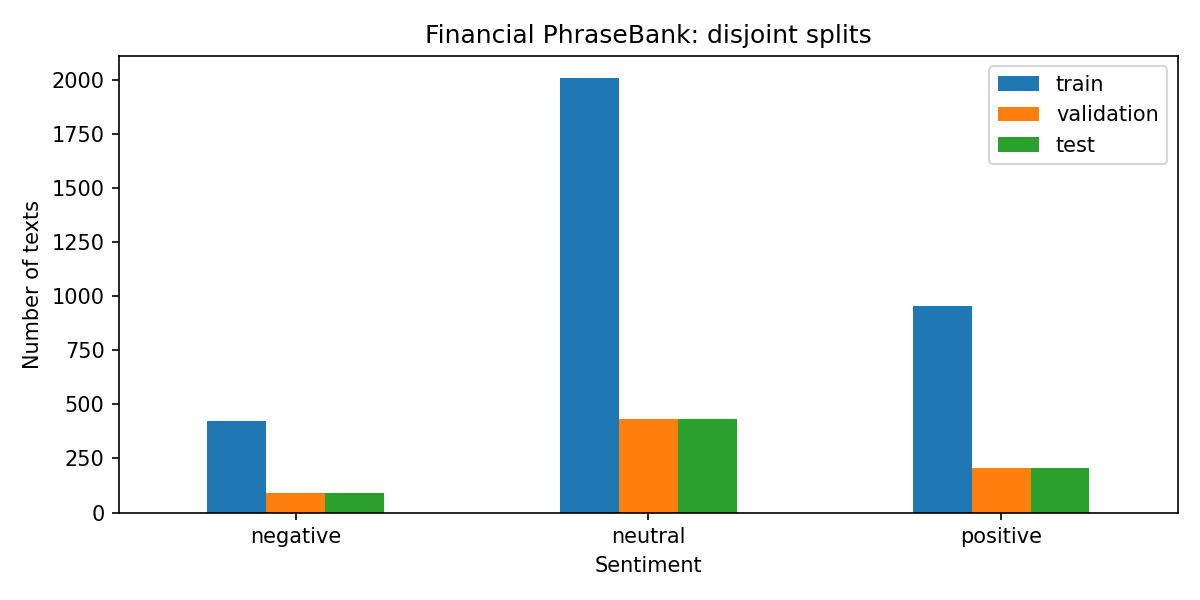

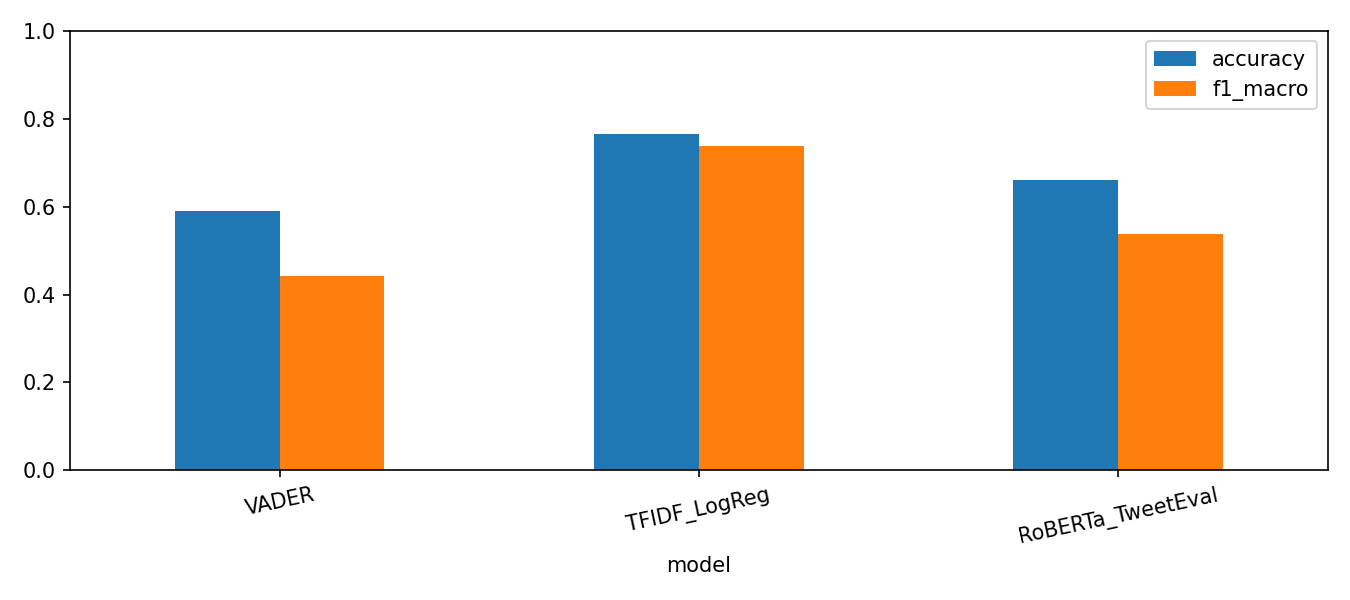

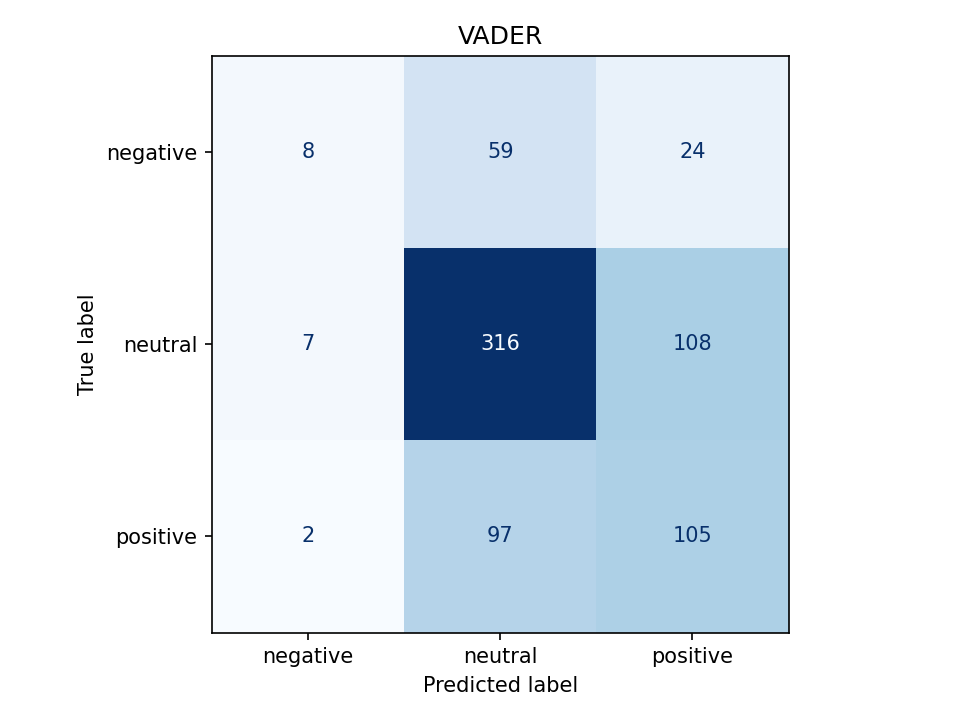

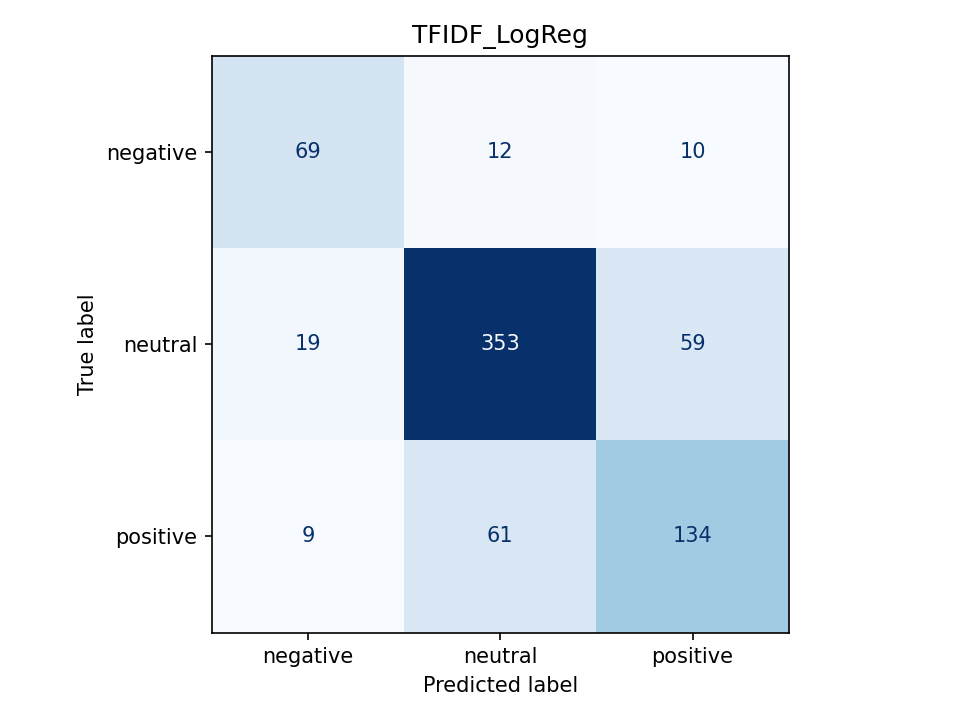

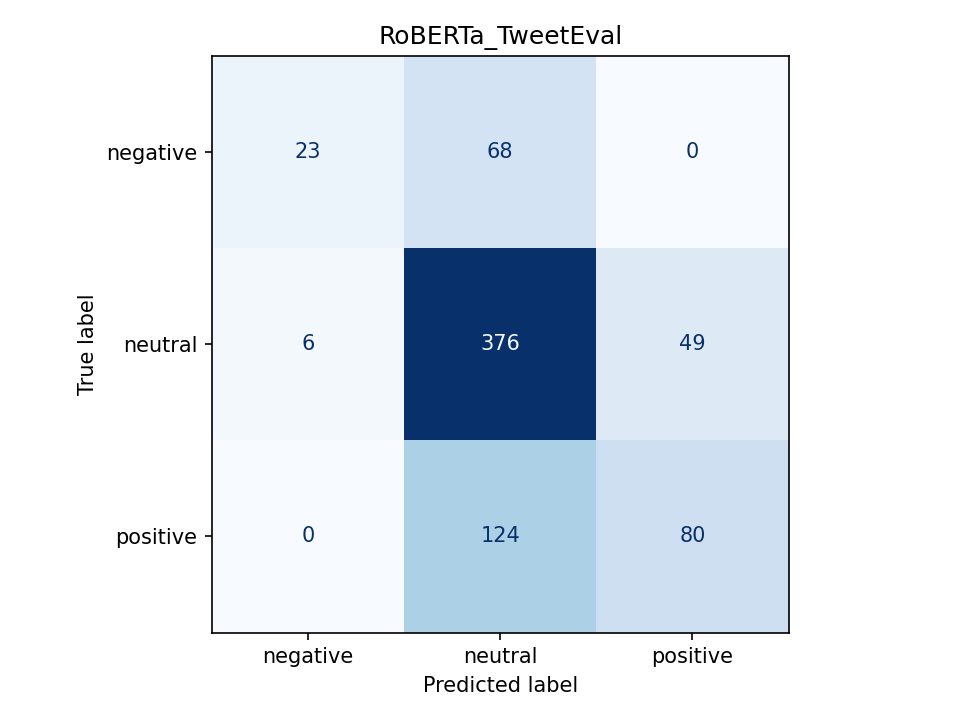

## 2. Автоматическое суммирование

**Данные:** [Multi-News](https://github.com/Alex-Fabbri/Multi-News), test row 856,
пять связанных публикаций 2013 года о Nancy Mace и выборах в Южной Каролине. Все документы длиннее
250 слов. Из опубликованного человеческого эталона взят цельный префикс предложений на 132 слова
по правилу, зафиксированному до генерации; полный эталон на 154 слова также сохранён и оценён.
Это человеческий текст из датасета, без переписывания моделью. Источники включают авторские мнения,
поэтому оценка фактической согласованности проверяет также атрибуцию утверждений.

**Методы:** TF-IDF выбирает по 3 исходных предложения из каждого документа. Из этих 15 выбираются 6,
с сохранением формулировок и удобного порядка. Иерархический [T5-small](https://huggingface.co/Falconsai/text_summarization)
обрабатывает все документы с учётом ограничения длины. Результат генерации проверяется по количеству слов,
а не по ROUGE. Оба метода оцениваются относительно одного эталона.

Сохранённая генерация повторно используется только при совпадении хеша входа и конфигурации.
Для нового запуска генерации: `t2_main(force=True)` или `python task2_summary.py --force`.
Автоматически сгенерированный текст сохраняется без ручного исправления; его ошибки разбираются отдельно.

В ячейках ниже содержится полная реализация. После запуска показаны рассчитанные результаты и их интерпретация.

### Независимый человеческий эталон (132 слова)

– Lindsey Graham has drawn a potentially formidable primary challenger. Nancy Mace, the first woman to ever graduate from the Citadel, plans to throw her hat in the ring, she tells the Daily Caller. Mace, 35, graduated from the military college back in 1999, and has since written a memoir and founded a PR firm. She'll officially announce her candidacy tomorrow, but she's already been raising money in preparation, the Washington Times reports. Mace has gotten a head start attacking Graham online; in a Red State column last month she savaged him at length for supporting the NSA's phone surveillance programs. In another on the Caller she sounds like she's trying out campaign language, with a series of "South Carolina needs a senator who..." statements as she blasts him for backing immigration reform.

In [8]:
"""Task 2: TF-IDF extraction and hierarchical T5 summarization.

The reference is a pre-existing human summary from Multi-News, never model output.
Run from any directory: python task2_summary.py
"""
from __future__ import annotations

import argparse
from collections import Counter
import hashlib
import importlib.metadata
import json
import os
from pathlib import Path
import re
import time

ROOT = Path.cwd()
if not (ROOT / 'task1_sentiment.py').exists() and (ROOT / 'assignment3').is_dir():
    ROOT = ROOT / 'assignment3'
T2_DATA = ROOT / "data" / "task2"
T2_OUT = ROOT / "results" / "task2"
T2_MODEL_DIR = ROOT / ".cache" / "t5-small-summarization"
T2_MODEL_ID = "Falconsai/text_summarization"

os.environ.setdefault("HF_HOME", str(ROOT / ".cache" / "huggingface"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))


In [9]:
def t2_normalize(text: str) -> str:
    """Remove layout artifacts, retaining case, wording and punctuation."""
    text = text.translate(str.maketrans({"\x91": "‘", "\x92": "’", "\x93": "“", "\x94": "”", "\x96": "–", "\x97": "—", "\xad": ""}))
    return re.sub(r"\s+", " ", text.replace("NEWLINE_CHAR", " ")).strip()


In [10]:
def t2_preprocess_documents(docs: list[str]) -> list[str]:
    """Remove one explicitly identifiable publisher/license footer, not article facts."""
    cleaned, records = [], []
    for doc_id, doc in enumerate(docs, 1):
        normalized = t2_normalize(doc)
        marker = "Follow Jim on Twitter Content created by The Daily Caller News Foundation"
        body, separator, footer = normalized.partition(marker)
        cleaned.append(body.strip() if separator else normalized)
        records.append({"document": doc_id, "original_words": len(t2_words(doc)),
                        "clean_words": len(t2_words(cleaned[-1])),
                        "removed_publisher_footer": marker+footer if separator else "",
                        "formatting": "Normalize whitespace/NEWLINE_CHAR and repair C1 smart punctuation; case and original sentence wording retained."})
    t2_save_json(T2_OUT / "preprocessing.json", records)
    return cleaned


In [11]:
def t2_words(text: str) -> list[str]:
    """One common, explicit word-count rule for sources, gold and generated text."""
    return re.findall(r"\b[\w]+(?:['’\-][\w]+)*\b", text, flags=re.UNICODE)


In [12]:
def t2_save_json(path: Path, value) -> None:
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


In [13]:
def t2_select_data() -> tuple[list[str], str, dict]:
    """Choose on structural criteria alone, before any summarizer is executed.

    Prefer a complete reference. If none is eligible, use the first row with
    exactly five 250--1500-word articles and a 151--175-word reference, taking
    its longest complete-sentence prefix in the 100--150-word interval. This
    output-independent policy keeps every reference word human-written; the
    full gold is retained for an additional sensitivity evaluation.
    """
    T2_DATA.mkdir(parents=True, exist_ok=True)
    manifest_path = T2_DATA / "provenance.json"
    if manifest_path.exists():
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        docs = [(T2_DATA / f"document_{i}.txt").read_text(encoding="utf-8") for i in range(1, 6)]
        reference = (T2_DATA / "human_reference.txt").read_text(encoding="utf-8")
        assert len(docs) == 5 and all(len(t2_words(d)) >= 250 for d in docs)
        assert 100 <= len(t2_words(reference)) <= 150
        return docs, reference, manifest
    source = T2_DATA / "test.src.cleaned"
    target = T2_DATA / "test.tgt"
    if not source.exists() or not target.exists():
        raise FileNotFoundError("Download the pinned Multi-News test files first (see download_task2_data.py).")
    revision = (T2_DATA / "dataset_revision.txt").read_text().strip()
    candidates = []
    fallback = None
    with source.open(encoding="utf-8") as fs, target.open(encoding="utf-8") as ft:
        for row, (src, tgt) in enumerate(zip(fs, ft)):
            docs = [t2_normalize(d) for d in src.split("|||||") if t2_normalize(d)]
            reference = t2_normalize(tgt)
            if len(docs) == 5 and all(250 <= len(t2_words(d)) <= 1500 for d in docs):
                candidates.append({"row": row, "reference_words": len(t2_words(reference)),
                                   "document_words": [len(t2_words(d)) for d in docs]})
                if 100 <= len(t2_words(reference)) <= 150:
                    break
                if fallback is None and 150 < len(t2_words(reference)) <= 175:
                    fallback = (row, docs, reference)
        else:
            if fallback is None:
                t2_save_json(T2_DATA / "selection_candidates.json", candidates)
                raise ValueError("No eligible collection/reference found; do not synthesize gold.")
            row, docs, reference = fallback
    full_reference = reference
    if len(t2_words(reference)) > 150:
        prefix = ""
        # Standard punctuation boundaries suffice for the selected human text.
        for sentence in re.split(r"(?<=[.!?])\s+(?=[A-Z])", full_reference):
            proposed = (prefix + " " + sentence).strip()
            if len(t2_words(proposed)) > 150:
                break
            prefix = proposed
        if not 100 <= len(t2_words(prefix)) <= 150:
            raise ValueError("No complete-sentence human excerpt of required length.")
        reference = prefix
    for i, doc in enumerate(docs, 1):
        (T2_DATA / f"document_{i}.txt").write_text(doc, encoding="utf-8")
    (T2_DATA / "human_reference.txt").write_text(reference, encoding="utf-8")
    (T2_DATA / "human_reference_full.txt").write_text(full_reference, encoding="utf-8")
    manifest = {
        "dataset": "Multi-News", "split": "test", "row_zero_based": row,
        "dataset_repository": "https://huggingface.co/datasets/alexfabbri/multi_news",
        "dataset_revision": revision,
        "dataset_paper": "https://aclanthology.org/P19-1102/",
        "dataset_license": "For non-commercial research and educational purposes only",
        "dataset_license_url": "https://github.com/Alex-Fabbri/Multi-News/blob/master/LICENSE.txt",
        "human_reference_origin": "Professionally written Newser editor summary supplied with Multi-News. Main reference is its longest complete-sentence prefix within 100-150 words, selected before any automatic output; no words rewritten. Full original reference retained and separately scored.",
        "selection_rule": "Scan test rows for exactly5 documents, each250-1500 words and full reference100-150 words. None met criteria. Fallback: first such row with151-175-word gold; keep longest complete-sentence prefix100-150. No output/ROUGE based selection.",
        "document_words": [len(t2_words(d)) for d in docs],
        "reference_words": len(t2_words(reference)),
        "full_reference_words": len(t2_words(full_reference)),
        "reference_excerpt_policy": "Longest complete-sentence prefix <=150 words; require >=100. Declared before generation. Full gold also used for sensitivity evaluation.",
        "word_count_regex": r"\b[\w]+(?:['’\-][\w]+)*\b",
        "downloaded_files": {
            name: {"url": f"https://huggingface.co/datasets/alexfabbri/multi_news/resolve/{revision}/data/{name}",
                   "sha256": hashlib.sha256((T2_DATA/name).read_bytes()).hexdigest()}
            for name in ("test.src.cleaned", "test.tgt")
        },
        "document_identifiers": [f"Multi-News/test/row_{row}/document_{i}" for i in range(1, 6)],
        "source_url_limitation": "The distributed record has no original article URLs; the pinned dataset row and document ordinal identify each text reproducibly.",
        "pretraining_limitation": "The model card does not precisely identify fine-tuning corpora. Exposure to these news documents in pretraining/fine-tuning cannot be excluded.",
    }
    t2_save_json(manifest_path, manifest)
    t2_save_json(T2_DATA / "selection_candidates.json", candidates)
    return docs, reference, manifest


In [14]:
def t2_sentence_tokenize(text: str, minimum_words: int = 3) -> list[str]:
    from nltk.tokenize.punkt import PunktSentenceTokenizer, load_punkt_params
    parameters = load_punkt_params(T2_DATA / "nltk_data" / "tokenizers" / "punkt_tab" / "english")
    parameters.abbrev_types.update({"mr", "mrs", "ms", "dr", "prof", "sen", "rep", "reps", "gov", "u.s", "u.n", "s.c", "a.m", "p.m", "st", "vs", "etc", "no", "jr", "sr", "inc", "ltd"})
    tokenizer = PunktSentenceTokenizer(parameters)
    # A same-length quote-normalized shadow lets Punkt handle curly quotation
    # marks correctly. Spans slice the ORIGINAL string, preserving its wording.
    shadow = text.translate(str.maketrans({"“": '"', "”": '"', "‘": "'", "’": "'"}))
    sentences = [text[start:end] for start, end in tokenizer.span_tokenize(shadow)]
    return [t2_normalize(s) for s in sentences if len(t2_words(s)) >= minimum_words]


In [15]:
def t2_extractive(docs: list[str]) -> dict:
    import numpy as np
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.metrics.pairwise import cosine_similarity
    all_records, candidates = [], []
    for doc_id, doc in enumerate(docs, 1):
        sentences = t2_sentence_tokenize(doc)
        vectorizer = TfidfVectorizer(stop_words="english", lowercase=True,
                                     token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z'-]+\b",
                                     sublinear_tf=True, norm="l2")
        matrix = vectorizer.fit_transform(sentences)
        centroid = np.asarray(matrix.mean(axis=0))
        importance = cosine_similarity(matrix, centroid).ravel()
        top = np.argsort(-importance, kind="stable")[:3]
        for index, sentence in enumerate(sentences):
            record = {"document": doc_id, "sentence_index": index, "sentence": sentence,
                      "tfidf_centroid_score": float(importance[index]), "selected_per_document": bool(index in top)}
            all_records.append(record)
            if index in top:
                candidates.append(record.copy())
    # Rescore the fifteen candidates together; MMR reduces repeated sentences.
    candidates.sort(key=lambda r: (r["document"], r["sentence_index"]))
    vectorizer = TfidfVectorizer(stop_words="english", sublinear_tf=True)
    matrix = vectorizer.fit_transform([r["sentence"] for r in candidates])
    centroid = np.asarray(matrix.mean(axis=0))
    relevance = cosine_similarity(matrix, centroid).ravel()
    similarities = cosine_similarity(matrix)
    chosen = []
    # Coverage constraint: one most relevant candidate from every source.
    for doc_id in range(1, 6):
        eligible = [i for i, r in enumerate(candidates) if r["document"] == doc_id]
        best = max(eligible, key=lambda i: relevance[i])
        chosen.append(best)
    # Sixth sentence: combine relevance with novelty (fixed lambda = 0.7).
    remaining = [i for i in range(len(candidates)) if i not in chosen]
    mmr_scores = {i: float(0.7*relevance[i] - 0.3*max(similarities[i, j] for j in chosen)) for i in remaining}
    chosen.append(max(remaining, key=mmr_scores.get))
    for i, record in enumerate(candidates):
        record["combined_relevance_score"] = float(relevance[i])
        record["selected_combined"] = bool(i in chosen)
        record["sixth_sentence_mmr_score"] = mmr_scores.get(i)
    selected = sorted([candidates[i] for i in chosen], key=lambda r: (r["document"], r["sentence_index"]))
    summary = " ".join(r["sentence"] for r in selected)
    assert len(candidates) == 15 and len(selected) == 6
    assert len(t2_sentence_tokenize(summary, minimum_words=1)) == 6
    assert len(set(r["document"] for r in selected)) == 5
    for record in selected:
        assert record["sentence"] in docs[record["document"]-1]
    result = {"all_sentences": all_records, "fifteen_candidates": candidates,
              "six_selected": selected, "summary": summary,
              "summary_sentence_count": 6,
              "method": "Within each document: cosine(TF-IDF(sentence), mean TF-IDF(document sentences)); top 3. Global TF-IDF centroid rescore; one candidate per source plus sixth by MMR lambda=0.7. Final order: document then original sentence index."}
    t2_save_json(T2_OUT / "extractive_details.json", result)
    (T2_OUT / "extractive_combined_6_sentences.txt").write_text(summary, encoding="utf-8")
    for doc_id in range(1, 6):
        text = " ".join(r["sentence"] for r in candidates if r["document"] == doc_id)
        assert len(t2_sentence_tokenize(text, minimum_words=1)) == 3
        (T2_OUT / f"extractive_document_{doc_id}_3_sentences.txt").write_text(text, encoding="utf-8")
    return result


In [16]:
def t2_abstractive(docs: list[str], force: bool = False) -> dict:
    cached = T2_OUT / "abstractive_details.json"
    input_hash = hashlib.sha256("\n\n".join(docs).encode("utf-8")).hexdigest()
    if cached.exists() and not force:
        result = json.loads(cached.read_text(encoding="utf-8"))
        if result.get("input_sha256") == input_hash:
            print("Reusing saved, actually executed T5 generation; pass force=True to regenerate.", flush=True)
            return result
    t2_ensure_model()
    import torch
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    torch.manual_seed(42)
    torch.set_num_threads(4)
    tokenizer = AutoTokenizer.from_pretrained(T2_MODEL_DIR, local_files_only=True, use_fast=True)
    model = AutoModelForSeq2SeqLM.from_pretrained(T2_MODEL_DIR, local_files_only=True, use_safetensors=True).eval()
    calls = []
    max_input = 512
    payload_limit = max_input - tokenizer.num_special_tokens_to_add(pair=False) - 5
    chunk_budget = 420  # T5-small supports512 input tokens; prefix adds several.

    def token_count(text):
        return len(tokenizer.encode(text, add_special_tokens=False, verbose=False))

    def chunks(text):
        """Sentence boundaries first; exceptionally long sentence uses token slices."""
        groups, current, count = [], [], 0
        for sentence in t2_sentence_tokenize(text, minimum_words=1):
            tokens = tokenizer.encode(sentence, add_special_tokens=False, verbose=False)
            pieces = [sentence] if len(tokens) <= chunk_budget else [tokenizer.decode(tokens[i:i+chunk_budget], skip_special_tokens=True) for i in range(0, len(tokens), chunk_budget)]
            for piece in pieces:
                n = token_count(piece)
                if current and count + n > chunk_budget:
                    groups.append(" ".join(current))
                    current, count = [], 0
                current.append(piece)
                count += n
        if current:
            groups.append(" ".join(current))
        return groups

    def generate(text, minimum, maximum, stage):
        encoded = tokenizer("summarize: " + text, return_tensors="pt", truncation=False)
        input_length = encoded["input_ids"].shape[1]
        if input_length > max_input:
            raise ValueError(f"Unprocessed overlong input at {stage}: {input_length}")
        settings = {"min_new_tokens": minimum, "max_new_tokens": maximum, "num_beams": 4,
                    "do_sample": False, "no_repeat_ngram_size": 3, "length_penalty": 1.0,
                    "early_stopping": True}
        started = time.perf_counter()
        with torch.inference_mode():
            output = model.generate(**encoded, **settings)
        text_out = t2_normalize(tokenizer.decode(output[0], skip_special_tokens=True))
        calls.append({"stage": stage, "input_tokens": input_length,
                      "input_text": text, "output": text_out, "output_words": len(t2_words(text_out)),
                      "settings": settings, "seconds": round(time.perf_counter()-started, 2)})
        print(f"{stage}: {input_length} input tokens -> {len(t2_words(text_out))} words", flush=True)
        return text_out

    document_briefs = []
    coverage = []
    for doc_id, doc in enumerate(docs, 1):
        parts = chunks(doc)
        coverage.append({"document": doc_id, "source_tokens": token_count(doc), "chunks": len(parts),
                         "chunk_tokens": [token_count(p) for p in parts],
                         "policy": "All sentence chunks are processed; no leading-document truncation."})
        brief_parts = [generate(part, 45, 90, f"document_{doc_id}/chunk_{i}") for i, part in enumerate(parts, 1)]
        combined = " ".join(brief_parts)
        # Reduce per-document summaries to <= 100 tokens so all five fit fusion.
        if len(parts) > 1:
            while token_count(combined) > payload_limit:
                combined = " ".join(generate(p, 45, 85, f"document_{doc_id}/intermediate_reduce") for p in chunks(combined))
            combined = generate(combined, 60, 88, f"document_{doc_id}/reduce")
        document_briefs.append(combined)
    fusion_input = " ".join(document_briefs)
    assert token_count(fusion_input) <= payload_limit
    attempts = []
    # Prespecified length-only retry policy. The reference is never an input.
    minimum, maximum = 150, 210
    for _ in range(5):
        summary = generate(fusion_input, minimum, maximum, "fusion")
        attempts.append({"minimum": minimum, "maximum": maximum, "words": len(t2_words(summary))})
        if 100 <= len(t2_words(summary)) <= 150:
            break
        multiplier = 125 / max(1, len(t2_words(summary)))
        minimum = max(30, min(260, round(minimum * multiplier)))
        maximum = max(minimum+25, min(310, round(maximum * multiplier)))
    else:
        raise ValueError(f"Model did not meet 100-150 word target: {attempts}. Do not hand-edit model output.")
    result = {"model": T2_MODEL_ID, "model_revision": (T2_MODEL_DIR/"revision.txt").read_text().strip(),
              "input_sha256": input_hash,
              "model_card": f"https://huggingface.co/{T2_MODEL_ID}",
              "model_license": "apache-2.0", "device": "CPU", "seed": 42,
              "max_input_tokens": max_input, "chunk_budget_tokens": chunk_budget,
              "document_coverage": coverage, "document_briefs": document_briefs,
              "generation_calls": calls, "length_attempts": attempts,
              "reference_used_for_generation": False, "summary": summary, "summary_words": len(t2_words(summary)),
              "software": {name: importlib.metadata.version(name) for name in ["torch", "transformers", "tokenizers", "nltk"]}}
    t2_save_json(cached, result)
    (T2_OUT / "abstractive_summary.txt").write_text(summary, encoding="utf-8")
    return result


In [17]:
def t2_evaluate(extract: dict, abstract: dict, reference: str, docs: list[str], manifest: dict) -> dict:
    import numpy as np
    import pandas as pd
    from rouge_score import rouge_scorer
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    rows = []
    for method, summary in [("TF-IDF extractive", extract["summary"]), ("T5-small abstractive", abstract["summary"])]:
        scores = scorer.score(reference, summary)
        row = {"method": method, "words": len(t2_words(summary))}
        for metric, value in scores.items():
            row.update({f"{metric}_{part}": float(getattr(value, part)) for part in ["precision", "recall", "fmeasure"]})
        rows.append(row)
    frame = pd.DataFrame(rows)
    frame.to_csv(T2_OUT / "rouge_comparison.csv", index=False)
    # Sensitivity to excerpting: score the very same outputs against full gold.
    full_reference = (T2_DATA / "human_reference_full.txt").read_text(encoding="utf-8")
    sensitivity = []
    for row, summary in zip(rows, [extract["summary"], abstract["summary"]]):
        scores = scorer.score(full_reference, summary)
        sensitivity.append({"method": row["method"], "reference_words": len(t2_words(full_reference)),
                            **{f"{m}_fmeasure": float(v.fmeasure) for m, v in scores.items()}})
    pd.DataFrame(sensitivity).to_csv(T2_OUT / "rouge_full_reference_sensitivity.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x = np.arange(3)
    for offset, row in zip([-0.18, 0.18], rows):
        values = [row[f"{m}_fmeasure"] for m in ["rouge1", "rouge2", "rougeL"]]
        ax.bar(x+offset, values, width=0.35, label=row["method"])
    ax.set_xticks(x, ["ROUGE-1", "ROUGE-2", "ROUGE-L"])
    ax.set_ylabel("F1 (0-1)")
    ax.set_ylim(0, 1)
    ax.set_title("Same independent human reference; one collection")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(T2_OUT / "rouge_comparison.png", dpi=160)
    plt.close(fig)
    report = {"documents": manifest["document_words"], "reference_words": len(t2_words(reference)),
              "clean_document_words": [len(t2_words(d)) for d in docs],
              "human_reference": reference, "extractive_summary": extract["summary"],
              "abstractive_summary": abstract["summary"], "rouge": rows,
              "full_human_reference": full_reference, "full_reference_sensitivity": sensitivity,
              "evaluation_settings": {"package": "rouge-score", "version": importlib.metadata.version("rouge-score"),
                                      "use_stemmer": True, "rougeL": "Sequence longest common subsequence (not rougeLsum)",
                                      "unit": "Single five-document collection; descriptive comparison, no significance claim."},
              "provenance": manifest}
    t2_save_json(T2_OUT / "task2_results.json", report)
    print(frame[["method", "words", "rouge1_fmeasure", "rouge2_fmeasure", "rougeL_fmeasure"]].to_string(index=False), flush=True)
    return report


In [18]:
def t2_ensure_model() -> None:
    """The submission ships results, not242MB weights; download only for new inference."""
    if (T2_MODEL_DIR / "model.safetensors").exists():
        return
    import runpy
    import sys
    if str(ROOT) not in sys.path:
        sys.path.insert(0, str(ROOT))
    runpy.run_path(str(ROOT / "download_task2_model.py"), run_name="__main__")


In [19]:
def t2_main(force: bool = False, extract_only: bool = False) -> dict:
    T2_OUT.mkdir(parents=True, exist_ok=True)
    docs, reference, manifest = t2_select_data()
    print(f"Multi-News test row {manifest['row_zero_based']}: documents {manifest['document_words']}; human reference {manifest['reference_words']} words", flush=True)
    docs = t2_preprocess_documents(docs)
    extracted = t2_extractive(docs)
    if extract_only:
        return extracted
    abstracted = t2_abstractive(docs, force=force)
    return t2_evaluate(extracted, abstracted, reference, docs, manifest)


In [20]:
task2_result = t2_main()


Multi-News test row 856: documents [829, 606, 328, 704, 476]; human reference 132 words
Reusing saved, actually executed T5 generation; pass force=True to regenerate.
              method  words  rouge1_fmeasure  rouge2_fmeasure  rougeL_fmeasure
   TF-IDF extractive    141         0.355872         0.129032         0.206406
T5-small abstractive    105         0.288066         0.049793         0.131687


In [21]:
import pandas as pd
print('\nrouge_comparison.csv')
print(pd.read_csv(ROOT / 'results' / 'task2' / 'rouge_comparison.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nrouge_full_reference_sensitivity.csv')
print(pd.read_csv(ROOT / 'results' / 'task2' / 'rouge_full_reference_sensitivity.csv').head(100).to_string(index=False,max_colwidth=120))



rouge_comparison.csv
              method  words  rouge1_precision  rouge1_recall  rouge1_fmeasure  rouge2_precision  rouge2_recall  rouge2_fmeasure  rougeL_precision  rougeL_recall  rougeL_fmeasure
   TF-IDF extractive    141          0.344828       0.367647         0.355872          0.125000       0.133333         0.129032          0.200000       0.213235         0.206406
T5-small abstractive    105          0.327103       0.257353         0.288066          0.056604       0.044444         0.049793          0.149533       0.117647         0.131687

rouge_full_reference_sensitivity.csv
              method  reference_words  rouge1_fmeasure  rouge2_fmeasure  rougeL_fmeasure
   TF-IDF extractive              154         0.368421         0.119205         0.203947
T5-small abstractive              154         0.278195         0.045455         0.135338


### Интерпретация

В задании использована одна связанная коллекция Multi-News: test, строка 856 (нумерация с нуля), пять материалов 2013 года о намерении Нэнси Мейс участвовать в республиканских праймериз против Линдси Грэма в 2014 году. Два материала представляют авторские политические колонки, поэтому содержащиеся в них оценки необходимо отличать от нейтральных фактов. Исходные объёмы: 829, 606, 328, 704 и 476 слов. После исправления управляющих символов, нормализации пробелов и удаления явно обозначенного издательского футера четвёртого текста: 816, 606, 328, 630 и 476 слов. Все пять текстов превышают минимум 250 слов. Тексты, идентификаторы источников, revision и SHA-256 исходных файлов сохранены в data/task2/provenance.json.

Эталон действительно написан человеком: это редакционное резюме Newser из Multi-News. Во всём test не оказалось коллекции ровно из пяти текстов нужного объёма с полным эталоном 100–150 слов. До запуска моделей было задано правило: выбрать первую подходящую коллекцию с эталоном 151–175 слов и взять максимально длинный начальный отрывок из полных предложений, укладывающийся в 150 слов. Получился эталон из 132 слов; исходный эталон из 154 слов также сохранён. Ни одно слово эталона не переписано и не сгенерировано моделью. Отсечённое последнее предложение касается других соперников и разделения голосов Tea Party. Для проверки влияния этого решения приведён дополнительный ROUGE по полному эталону.

Предложения разделяет обученный английский Punkt из NLTK; дополнительные сокращения помогают обрабатывать U.S., S.C., Sen. и Mr. Для работы с фигурными кавычками создаётся вспомогательная строка той же длины; найденные границы применяются к исходной строке. Регистр и формулировки итоговых экстрактов сохраняются. При оценке важности используется TF-IDF с английскими стоп-словами, нижним регистром и логарифмической частотой. В каждом документе выбираются три предложения с наибольшим косинусным сходством с центроидом документа. Пятнадцать кандидатов переоцениваются совместно. В итог включается по одному предложению из каждого источника и шестое по MMR с фиксированным коэффициентом 0,7. Порядок соответствует номеру документа и позиции предложения. Программно проверено: 3 предложения в каждом из пяти экстрактов и ровно 6 в объединённом экстракте; в нём 141 слово.

Абстрактивный метод — предварительно обученная Falconsai/text_summarization на основе T5-small (60,5 млн параметров), фиксированная версия 6e505f907968c4a9360773ff57885cdc6dca4bfd. Текст не передаётся целиком с обрезанием начала или конца: все пять документов разбиваются на 12 блоков, затем создаются пять промежуточных резюме и одно общее. Ограничение входа составляет 512 токенов; фактический максимум одного вызова — 421. Блоки получают 45–90 новых токенов, резюме документа — 60–88, итог — 150–210. Во всех вызовах: beam search с 4 лучами, do_sample=False, no_repeat_ngram_size=3, length_penalty=1, early_stopping=True. Итог реально сгенерирован на CPU и содержит 105 слов; вручную он не исправлялся. Предусмотренное повторение для коррекции длины не понадобилось. Человеческий эталон не передавался в генерацию.

ROUGE-F1 по одному и тому же эталону из 132 слов, со стеммингом: TF-IDF — ROUGE-1=0,3559, ROUGE-2=0,1290, ROUGE-L=0,2064; T5-small — 0,2881, 0,0498 и 0,1317 соответственно. В CSV дополнительно сохранены precision и recall. По полному эталону из 154 слов TF-IDF получает 0,3684 / 0,1192 / 0,2039, T5-small — 0,2782 / 0,0455 / 0,1353. Преимущество TF-IDF сохраняется при обоих эталонах. Здесь ROUGE-L означает LCS последовательности, а не ROUGE-Lsum.

Покрытие информации. Экстракт сохраняет главное событие, сведения о первом выпуске женщины из Citadel, появление Ли Брайта и позицию консервативных критиков. Формальное наличие предложения от каждого источника ещё не означает полноты: вместо конкретных сведений о наблюдении NSA и иммиграционной реформе часть выбранных предложений содержит общие политические оценки. T5 включает Ричарда Кэша и сбор средств, но опускает важное для человеческого эталона обстоятельство: Мейс стала первой женщиной-выпускницей Citadel. Оно присутствует даже во входе последнего шага генерации, поэтому потеря произошла при финальном объединении. Подробности критики иммиграционного законопроекта также практически исчезают.

Связность и читаемость. У экстракта грамматически законченные предложения, но переходы между пятью источниками резкие. Формулировка «this bill» в последнем предложении не объясняет читателю, о каком законопроекте идёт речь. T5 не улучшила связность: в одном длинном предложении смешаны сведения о Кэше, предложении Брайта создать валюту и позиции Грэма; в конце остаётся фрагмент «Senate.». Для этой компактной модели абстрактивность не обеспечила более связный текст.

Повторы. Экстракт дважды сообщает о намерении первой женщины-выпускницы Citadel бросить вызов Грэму: первая и четвёртая фразы заметно пересекаются по смыслу. MMR уменьшает повторы только при выборе шестого предложения и не устраняет повторение среди обязательных пяти. В T5 последние общие фразы о республиканских кандидатах и следующем годе повторяют уже изложенную тему, хотя буквальные повторяющиеся триграммы запрещены. Ограничение no_repeat_ngram_size не гарантирует отсутствия смысловых повторов.

Фактическая согласованность. В исходном документе 3 Мейс собирает средства для участия в праймериз против сенатора Грэма в 2014 году. T5 превращает это в «a 2014 presidential election»: это неподтверждённая замена типа выборов, а не допустимое перефразирование. Модель также искажает фамилию Lindsey до Lindsy. Экстракт не создаёт новых формулировок, но цитатные оценки из авторских колонок теряют явное указание автора: фразы о Bill of Rights и «leftists» нельзя читать как проверенные нейтральные факты. Фактическая согласованность с источниками и истинность политических утверждений — разные вопросы.

Грамматика. У экстракта сохранён синтаксис источников; основная проблема — контекст и связность между предложениями. В T5 есть незавершённое «congressional run Bright introduced», предложение с маленькой буквы «the two...», отдельное «Senate.» и неестественные заключительные фразы. Это реальные недостатки сгенерированного результата, они оставлены для анализа.

Таким образом, выявлены как минимум четыре различия: копирование исходных предложений против создания новых формулировок; иная потеря сведений при отборе и при иерархической генерации; разные формы повторов; риск новых фактических и грамматических ошибок у T5. В этом эксперименте TF-IDF даёт лучший баланс покрытия, читаемости и согласованности: его ROUGE выше по всем трём метрикам, а критическая подмена вида выборов отсутствует. Это вывод об одной коллекции и конкретном компактном checkpoint, а не доказательство превосходства экстрактивных методов вообще. Названия корпусов дообучения модели в карточке описаны недостаточно точно, поэтому пересечение источников с её обучающими данными исключить нельзя. ROUGE оценивает совпадение формулировок и не заменяет ручную проверку фактов.


### abstractive summary

Nancy Mace and state Sen. Lee Bright say they will announce soon that they will run against U.S. Sen. Lindsey Graham in next year's Republican primary. The two challengers would join Richard Cash, an Easley businessman who lost a 2010 Republican congressional run Bright introduced a bill to study creating a S.C. currency in case the federal government fell into financial ruin Senator Lindsy Graham endorsed President Obama's intrusive arm of big brother. Mrs. Mace is raising money in preparation for a 2014 presidential election. the two will announce they will be a Republican. Senate. Republican nominees will run in the next year.

### extractive combined 6 sentences

— Nancy Mace, the first woman to graduate from The Citadel, and state Sen. Lee Bright, one of the Legislature’s more outspoken libertarians, say they will announce soon that they will run against U.S. Sen. Lindsey Graham in next year’s Republican primary. In Senator Graham’s world, the entire Bill of Rights is negotiable. Mrs. Mace’s campaign announcement will come roughly a week after a conservative South Carolina group launched a grassroots campaign targeting Mr. Graham in the 2014 election. The first woman to graduate from the Citadel is planning to challenge South Carolina Sen. Lindsey Graham in the Republican primary next year. South Carolina Republican Rep. Trey Gowdy told an interviewer earlier this year, “Lindsey Graham will be fine.” South Carolina needs a senator who will work for the people he represents and not for the leftists who crafted this bill.

### extractive document 1 3 sentences

— Nancy Mace, the first woman to graduate from The Citadel, and state Sen. Lee Bright, one of the Legislature’s more outspoken libertarians, say they will announce soon that they will run against U.S. Sen. Lindsey Graham in next year’s Republican primary. “If I’m Lindsey Graham, I want two or three people opposing me,” Citadel political scientist Scott Buchanan said. The 35-year-old political newcomer has said for months that she was mulling a run against Graham.

### extractive document 2 3 sentences

In Senator Graham’s world, government should always be trusted but never the American citizen. In Senator Graham’s world, the entire Bill of Rights is negotiable. In Senator Graham’s world, our constitutional rights seem constantly up for debate.

### extractive document 3 3 sentences

“I need your help to make sure that South Carolina’s conservative values are represented in the U.S. Senate,” Mrs. Macesaid on her website. Mrs. Mace’s campaign announcement will come roughly a week after a conservative South Carolina group launched a grassroots campaign targeting Mr. Graham in the 2014 election. “We never know which Lindsey Graham will show up in Washington each day,” said Bruce Carroll, the group’s chairman.

### extractive document 4 3 sentences

The first woman to graduate from the Citadel is planning to challenge South Carolina Sen. Lindsey Graham in the Republican primary next year. South Carolina Republican state Sen. Tom Davis predicted to TheDCNF last year that “someone will challenge Lindsey Graham.” South Carolina Republican Rep. Trey Gowdy told an interviewer earlier this year, “Lindsey Graham will be fine.”

### extractive document 5 3 sentences

South Carolina needs a senator who will put border security first, not just pay lip service to it. South Carolina needs a senator who will work for the people he represents and not for the leftists who crafted this bill. South Carolina needs a senator who will not subsidize or incentivize more illegal immigration, who will not support legislation that will increase unemployment, and who will not support pork-laden legislation drafted behind closed doors.

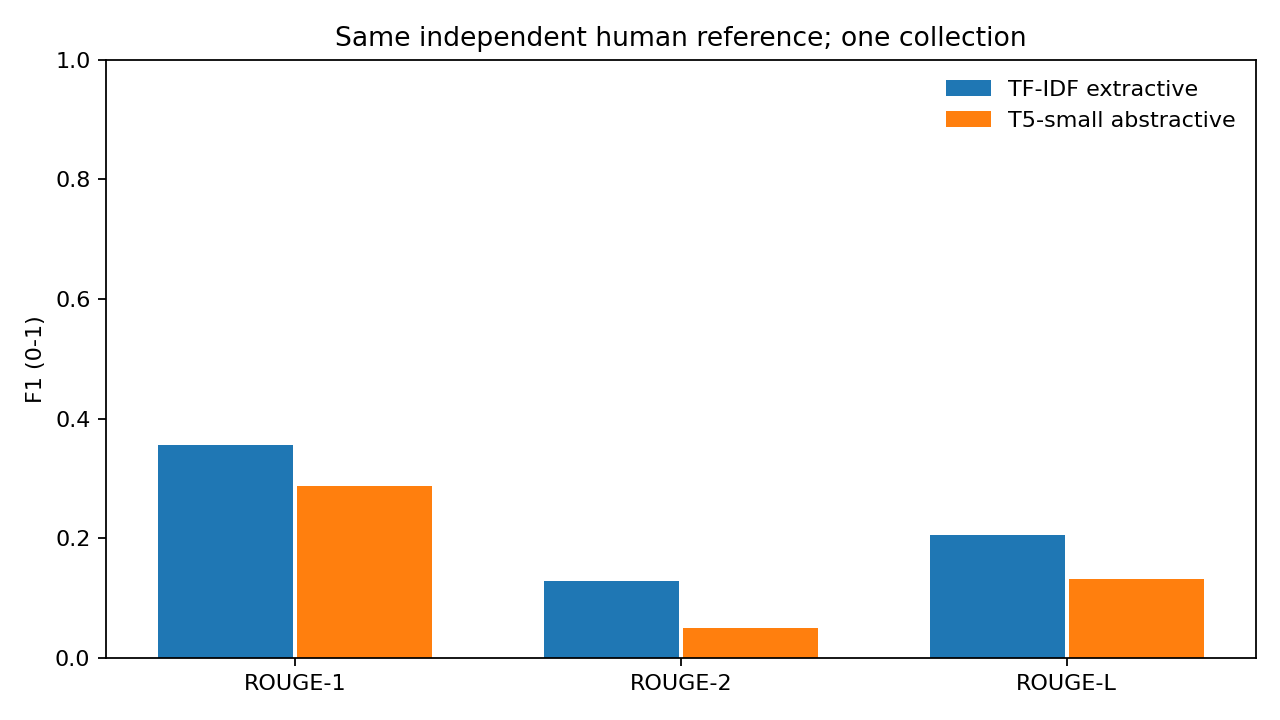

## 3. Лексика и классификация музыкальных жанров

**Данные:** [FMA labeled](https://huggingface.co/datasets/Reubencf/fma-labeled),
800 англоязычных песен, по 200 Folk, Hip-Hop, Pop, Rock. Жанры взяты из исходных метаданных FMA.
В корпус включены записи CC BY и CC0; атрибуция каждого произведения сохранена в data/task3/attributions.csv.
Тексты являются автоматическими транскрипциями, поэтому возможны ошибки ASR и разметки языка.
Названия разделов и технические сценические пометки удаляются как артефакты корпуса.

**Методы:** токенизация, lowercase, удаление пунктуации и стоп-слов, POS-aware лемматизация;
частоты, три словаря категорий, редкие слова и TF-IDF. Относительные частоты имеют знаменатель
«количество очищенных токенов жанра». Классификаторы: TF-IDF + MultinomialNB и Logistic Regression,
стратифицированное 80/20, seed=42. Дополнительно проверяется независимое разбиение по исполнителям.
TF-IDF для каждого классификационного эксперимента обучается только на его train.

После расчёта доступна `t3_predict_text("Your own lyrics")`; короткие демонстрационные тексты не являются тестовыми песнями.

В ячейках ниже содержится полная реализация. После запуска показаны рассчитанные результаты и их интерпретация.

In [22]:
"""Задание 3: лексика и классификация жанров по англоязычным текстам песен.

Запуск: python task3_genres.py. Данные и все результаты находятся рядом со скриптом.
Тексты берутся из открытых записей Free Music Archive; полная атрибуция каждой
выбранной песни сохраняется в data/task3/attributions.csv.
"""
from __future__ import annotations

from collections import Counter
from datetime import datetime, timezone
import hashlib
import json
import os
from pathlib import Path
import re
import unicodedata
import urllib.request

ROOT = Path.cwd()
if not (ROOT / 'task1_sentiment.py').exists() and (ROOT / 'assignment3').is_dir():
    ROOT = ROOT / 'assignment3'
DATA = ROOT / "data" / "task3"
OUT = ROOT / "results" / "task3"
os.environ.setdefault("MPLCONFIGDIR", str(DATA / ".matplotlib"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB

SEED = 42
GENRES = ["Folk", "Hip-Hop", "Pop", "Rock"]
_T3_STATE = {}  # Только две основные обученные модели; artist holdout сюда не записывается.
MAX_PER_GENRE = 200
SOURCE = "https://huggingface.co/datasets/Reubencf/fma-labeled"
FILES = {
    "fma_labels.parquet": f"{SOURCE}/resolve/main/labels.parquet",
    "source_README.md": f"{SOURCE}/raw/main/README.md",
}
WORD_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")
CATEGORIES = {
    "Time": "morning evening night day today tomorrow yesterday hour minute second year month week time dawn dusk midnight summer winter spring autumn forever",
    "Emotion": "love hate happy happiness sad sadness anger angry fear afraid hope joy lonely loneliness sorrow pain cry smile dream miss desire jealous jealousy worry regret peace passion",
    "Body": "heart eye hand arm face head hair skin lip mouth foot leg finger blood body soul ear shoulder chest bone tongue knee tooth brain",
}


In [23]:
def save_json(path: Path, value) -> None:
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")


In [24]:
def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


In [25]:
def prepare_resources() -> None:
    # Локальное размещение ресурсов делает перенос проекта предсказуемым.
    resource_dir = DATA / "nltk_data"
    resource_dir.mkdir(parents=True, exist_ok=True)
    nltk.data.path.insert(0, str(resource_dir))
    resources = {"stopwords": "corpora/stopwords", "wordnet": "corpora/wordnet.zip",
                 "averaged_perceptron_tagger_eng": "taggers/averaged_perceptron_tagger_eng"}
    for resource, location in resources.items():
        try:
            nltk.data.find(location)
        except LookupError:
            nltk.download(resource, download_dir=str(resource_dir), quiet=True, raise_on_error=True)


In [26]:
def download_sources() -> None:
    DATA.mkdir(parents=True, exist_ok=True)
    OUT.mkdir(parents=True, exist_ok=True)
    for name, url in FILES.items():
        path = DATA / name
        if not path.exists():
            print(f"  Download: {name}", flush=True)
            with urllib.request.urlopen(url, timeout=180) as response:
                path.write_bytes(response.read())


In [27]:
def canonical(text: str) -> str:
    # Точный дубликат определяется без учёта регистра, пунктуации и пробелов.
    text = remove_stage_labels(text)
    return " ".join(WORD_RE.findall(unicodedata.normalize("NFKC", text).lower()))


In [28]:
def remove_stage_labels(text: str) -> str:
    text = re.sub(r"\[[^\]]*\]", " ", text)
    # В транскрипциях встречаются также (Instrumental), (Guitar solo) и т.п.
    # Удаляем только известные технические ремарки, сохраняя прочие круглые скобки.
    stage = (r"instrumental|intro|outro|verse|chorus|bridge|interlude|pre[- ]chorus|"
             r"post[- ]chorus|solo|guitar|piano|drums?|music|synth|vocals?|fade")
    text = re.sub(r"\((?:" + stage + r")\b[^)]*\)", " ", text, flags=re.I)
    instruments = (r"guitar|piano|drums?|instrumental|synth(?:esizer)?|bass|percussion|"
                   r"harmonica|violin|ukulele|cello|saxophone|orchestra|whistling|humming")
    text = re.sub(r"\([^)]*\b(?:" + instruments + r")\b[^)]*\)", " ", text, flags=re.I)
    text = re.sub(r"(?im)^\s*(?:verse|chorus|bridge|intro|outro|interlude)\s*\d*\s*:?\s*$", " ", text)
    return text


In [29]:
def select_corpus() -> tuple[pd.DataFrame, dict]:
    source = pd.read_parquet(DATA / "fma_labels.parquet")
    source["lyrics"] = source["lyrics"].fillna("").astype(str)
    raw_tokens = source["lyrics"].map(lambda x: canonical(x).split())
    source["raw_words"] = raw_tokens.str.len()
    source["raw_unique_words"] = raw_tokens.map(lambda x: len(set(x)))
    # CC BY и CC0 разрешают повторное использование с соблюдением атрибуции.
    # ND исключён, чтобы не распространять преобразованные тексты с запретом производных.
    licensed = source["license"].isin(["CC BY", "CC0 / Public Domain"])
    english = source["language"].eq("en") & source["has_lyrics"].fillna(False).astype(bool)
    # Не включаем вокализации почти из одних "oh"/"la": для лексического сравнения
    # нужен хотя бы небольшой словарь. Порог задан до обучения моделей.
    quality = source["raw_words"].between(50, 3000) & source["raw_unique_words"].ge(20)
    eligible = source.loc[licensed & english & quality].copy()

    # Используем исходные теги FMA, а не предсказания жанра Gemini. Песни с двумя
    # выбранными жанрами исключаем: однозначная целевая метка важнее объёма корпуса.
    def original_genre(values):
        tags = set(values if isinstance(values, (list, np.ndarray)) else [])
        matches = sorted(tags.intersection(GENRES))
        return matches[0] if len(matches) == 1 else None

    eligible["genre_label"] = eligible["fma_genres"].map(original_genre)
    eligible = eligible.dropna(subset=["genre_label"])
    eligible["lyrics_hash"] = eligible["lyrics"].map(
        lambda x: hashlib.sha256(canonical(x).encode("utf-8")).hexdigest())
    conflicts = eligible.groupby("lyrics_hash")["genre_label"].nunique()
    conflict_hashes = set(conflicts.index[conflicts > 1])
    before_dedup = len(eligible)
    eligible = eligible.loc[~eligible["lyrics_hash"].isin(conflict_hashes)]
    eligible = eligible.sort_values(["artist", "title", "id"]).drop_duplicates("lyrics_hash")
    counts = eligible["genre_label"].value_counts().to_dict()
    n = min(MAX_PER_GENRE, min(counts.get(g, 0) for g in GENRES))
    if n < 100:
        raise ValueError(f"Нужно >=100 песен каждого жанра; доступно: {counts}")
    corpus = pd.concat([
        eligible.loc[eligible["genre_label"].eq(g)].sample(n=n, random_state=SEED)
        for g in GENRES
    ]).reset_index(drop=True)
    assert corpus["lyrics_hash"].is_unique
    corpus["artist_group"] = corpus["artist"].fillna("").astype(str).str.casefold().str.strip()
    corpus["artist_group"] = corpus["artist_group"].where(
        corpus["artist_group"].ne(""), "unknown_" + corpus["id"].astype(str))
    keep = ["id", "title", "artist", "artist_group", "genre_label", "genre", "fma_genres",
            "language", "lyrics", "raw_words", "lyrics_hash", "license", "license_url",
            "track_url", "artist_url", "label_model"]
    corpus = corpus[keep].copy()
    corpus["fma_genres"] = corpus["fma_genres"].map(lambda x: json.dumps(list(x), ensure_ascii=False))
    corpus.to_csv(DATA / "corpus.csv", index=False, encoding="utf-8")
    attribution_cols = ["id", "artist", "title", "track_url", "artist_url", "license", "license_url"]
    corpus[attribution_cols].to_csv(DATA / "attributions.csv", index=False, encoding="utf-8")
    info = {
        "source": SOURCE, "author": "Reuben Fernandes",
        "original_collection": "Free Music Archive (FMA)",
        "original_FMA": "https://github.com/mdeff/fma",
        "seed": SEED, "source_rows": len(source), "eligible_before_dedup": before_dedup,
        "conflicting_duplicate_hashes_removed": len(conflict_hashes),
        "duplicates_or_conflicts_removed": before_dedup - len(eligible),
        "available_by_genre": counts, "selected_per_genre": n, "selected_total": len(corpus),
        "genre_labels": "Original FMA fma_genres; exactly one of four selected top-level genres",
        "lyrics_origin": "Gemini automatic transcription of real FMA recordings; not human-verified",
        "language_selection": "source language=en; has_lyrics=True; 50..3000 English-pattern words after stage-label removal; >=20 unique word types",
        "track_licenses": corpus["license"].value_counts().to_dict(),
        "metadata_license": "CC0 (dataset card); lyrics retain per-track FMA licenses",
        "license_limit": "Dataset-card license statements retained; no claim of new rights to third-party works.",
        "files": {name: {"url": url, "sha256": sha256(DATA / name)} for name, url in FILES.items()},
        "corpus_sha256": sha256(DATA / "corpus.csv"),
    }
    save_json(DATA / "source_manifest.json", info)
    return corpus, info


In [30]:
def preprocess_corpus(corpus: pd.DataFrame) -> pd.DataFrame:
    stop = set(stopwords.words("english"))
    lemma = WordNetLemmatizer()
    pos_map = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}

    def process(text):
        text = unicodedata.normalize("NFKC", text).replace("’", "'").lower()
        text = remove_stage_labels(text)
        tokens = WORD_RE.findall(text)
        # POS ставится до удаления стоп-слов, чтобы сохранить грамматический контекст.
        tagged = nltk.pos_tag(tokens, lang="eng")
        cleaned = []
        for token, pos in tagged:
            if "'" in token:
                token = token.split("'")[0]  # punctuation removal; don't -> don (stopword)
            if len(token) < 2 or token in stop:
                continue
            value = lemma.lemmatize(token, pos_map.get(pos[:1], wordnet.NOUN))
            if value not in stop and len(value) > 1:
                cleaned.append(value)
        return " ".join(cleaned)

    corpus["clean_text"] = [process(t) for t in corpus["lyrics"]]
    _T3_STATE["preprocess"] = process
    corpus["clean_words"] = corpus["clean_text"].str.split().str.len()
    if corpus["clean_words"].min() < 5:
        raise ValueError("После предобработки найдена практически пустая песня")
    corpus.to_csv(DATA / "corpus_processed.csv", index=False, encoding="utf-8")
    return corpus


In [31]:
def descriptive_analysis(corpus: pd.DataFrame) -> dict:
    palette = ["#2F6B73", "#B85A3C", "#6B65A6", "#7A8739"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    corpus["genre_label"].value_counts().reindex(GENRES).plot.bar(ax=axes[0], color=palette, rot=0)
    axes[0].set(title="Balanced corpus", ylabel="Songs", xlabel="Genre")
    axes[1].boxplot([corpus.loc[corpus.genre_label.eq(g), "raw_words"] for g in GENRES],
                    tick_labels=GENRES, showfliers=False)
    axes[1].set(title="Lyrics length (fliers hidden)", ylabel="Words per song before preprocessing")
    fig.tight_layout(); fig.savefig(OUT / "corpus_distribution.png", dpi=170); plt.close(fig)

    stats = corpus.groupby("genre_label")[["raw_words", "clean_words"]].agg(["count", "mean", "median", "min", "max"])
    stats.to_csv(OUT / "length_statistics.csv", encoding="utf-8")
    top_rows, category_rows, rare_rows = [], [], []
    counters = {}
    # Лексические словари задаются до просмотра классификационных результатов.
    for genre in GENRES:
        texts = corpus.loc[corpus.genre_label.eq(genre), "clean_text"]
        counter = Counter(" ".join(texts).split()); counters[genre] = counter
        total = sum(counter.values())
        for word, freq in counter.most_common(10):
            top_rows.append({"genre": genre, "word": word, "absolute": freq,
                             "relative": freq / total, "per_1000_tokens": 1000 * freq / total})
        for category, words in CATEGORIES.items():
            freq = sum(counter[w] for w in set(words.split()))
            category_rows.append({"genre": genre, "category": category, "absolute": freq,
                                  "total_tokens": total, "relative": freq / total,
                                  "per_1000_tokens": 1000 * freq / total})
        for word, freq in sorted(counter.items()):
            if freq <= 3:
                rare_rows.append({"genre": genre, "word": word, "frequency": freq})
    tops = pd.DataFrame(top_rows); categories = pd.DataFrame(category_rows); rare = pd.DataFrame(rare_rows)
    tops.to_csv(OUT / "top10_frequencies.csv", index=False, encoding="utf-8")
    categories.to_csv(OUT / "lexical_categories.csv", index=False, encoding="utf-8")
    rare.to_csv(OUT / "rare_words_le3.csv", index=False, encoding="utf-8")
    save_json(OUT / "lexical_dictionaries.json", {k: v.split() for k, v in CATEGORIES.items()})
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, genre, color in zip(axes.ravel(), GENRES, palette):
        df = tops.loc[tops.genre.eq(genre)].iloc[::-1]
        bars = ax.barh(df.word, df.absolute, color=color)
        ax.set(title=genre, xlabel="Absolute frequency")
        ax.bar_label(bars, labels=[f"{p:.1%}" for p in df.relative], padding=3, fontsize=8)
        ax.margins(x=0.2)
    fig.suptitle("Top 10 lemmas; labels show relative frequency")
    fig.tight_layout(); fig.savefig(OUT / "top10_frequencies.png", dpi=170); plt.close(fig)
    matrix = categories.pivot(index="genre", columns="category", values="per_1000_tokens").reindex(GENRES)
    ax = matrix.plot.bar(figsize=(10, 4), rot=0, color=["#B85A3C", "#6B65A6", "#2F6B73"])
    ax.set(title="Lexical categories by genre", ylabel="Occurrences per 1,000 cleaned tokens")
    ax.figure.tight_layout(); ax.figure.savefig(OUT / "lexical_categories.png", dpi=170); plt.close(ax.figure)

    # Для описательной статистики можно использовать весь корпус. Этот векторизатор
    # не передаётся классификаторам: их словарь и IDF обучаются только на train.
    description_tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                      min_df=2, sublinear_tf=True)
    x = description_tfidf.fit_transform(corpus.clean_text)
    words = description_tfidf.get_feature_names_out()
    distinct_rows, high_tfidf_rows = [], []
    for genre in GENRES:
        mask = corpus.genre_label.eq(genre).to_numpy()
        own = np.asarray(x[mask].mean(axis=0)).ravel()
        rest = np.asarray(x[~mask].mean(axis=0)).ravel()
        # Усреднённый TF-IDF показывает устойчивую лексику жанра, а разность с другими
        # жанрами проверяет, не является ли термин просто общим словом всех песен.
        order = np.argsort(own - rest)[::-1][:25]
        for rank, j in enumerate(order, 1):
            distinct_rows.append({"genre": genre, "rank": rank, "word": words[j],
                                  "mean_tfidf": own[j], "mean_tfidf_other_genres": rest[j],
                                  "contrast": own[j] - rest[j], "corpus_frequency": counters[genre][words[j]],
                                  "rare_le3": counters[genre][words[j]] <= 3})
        for rank, j in enumerate(np.argsort(own)[::-1][:25], 1):
            high_tfidf_rows.append({"genre": genre, "rank": rank, "word": words[j],
                                   "mean_tfidf": own[j], "corpus_frequency": counters[genre][words[j]],
                                   "rare_le3": counters[genre][words[j]] <= 3})
    distinct = pd.DataFrame(distinct_rows)
    distinct.to_csv(OUT / "distinctive_tfidf.csv", index=False, encoding="utf-8")
    high_tfidf = pd.DataFrame(high_tfidf_rows)
    high_tfidf.to_csv(OUT / "high_mean_tfidf.csv", index=False, encoding="utf-8")
    rare_examples = {}
    for genre in GENRES:
        # Примеры редких слов выбираются по алфавиту, а не по качеству предсказаний.
        r = rare.loc[rare.genre.eq(genre)]
        rare_examples[genre] = {"rare_vocabulary_size": len(r), "examples": r.head(12).word.tolist(),
                                "top25_tfidf_rare_overlap": int(high_tfidf.loc[high_tfidf.genre.eq(genre), "rare_le3"].sum()),
                                "top25_contrast_rare_overlap": int(distinct.loc[distinct.genre.eq(genre), "rare_le3"].sum())}
    save_json(OUT / "rare_vs_tfidf.json", rare_examples)
    return {"top_words": {g: tops.loc[tops.genre.eq(g), "word"].tolist() for g in GENRES},
            "rare": rare_examples, "category_peak": {
                cat: categories.loc[categories.category.eq(cat)].sort_values("per_1000_tokens", ascending=False).iloc[0].to_dict()
                for cat in CATEGORIES}}


In [32]:
def model_factory():
    return {
        "MultinomialNB": MultinomialNB(alpha=0.5),
        "LogisticRegression": LogisticRegression(C=4.0, max_iter=2000, random_state=SEED),
    }


In [33]:
def evaluate_split(corpus: pd.DataFrame, train_idx, test_idx, split_name: str) -> tuple[list[dict], pd.DataFrame, dict]:
    train = corpus.iloc[train_idx]; test = corpus.iloc[test_idx]
    assert not set(train.lyrics_hash).intersection(test.lyrics_hash)
    # Ни жанры, ни имена, ни заголовки не включаются в признаки.
    vectorizer = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                 ngram_range=(1, 2), min_df=2, max_df=0.98,
                                 sublinear_tf=True, max_features=30000)
    x_train = vectorizer.fit_transform(train.clean_text)
    x_test = vectorizer.transform(test.clean_text)
    if split_name == "stratified_80_20":
        _T3_STATE["vectorizer"] = vectorizer
        _T3_STATE["models"] = {}
    rows = []
    predictions = test[["id", "title", "artist", "genre_label", "clean_words", "lyrics_hash"]].copy()
    prediction_details = {}
    for model_name, model in model_factory().items():
        model.fit(x_train, train.genre_label)
        if split_name == "stratified_80_20":
            _T3_STATE["models"][model_name] = model
        pred = model.predict(x_test)
        predictions[model_name] = pred
        # Для каждой ошибки сохраняем наблюдаемые признаки, которые увеличивают
        # линейный score предсказанного класса относительно истинного.
        coefficients = model.coef_ if model_name == "LogisticRegression" else model.feature_log_prob_
        class_index = {label: i for i, label in enumerate(model.classes_)}
        feature_names = vectorizer.get_feature_names_out()
        supports = []
        for i, (gold, guess) in enumerate(zip(test.genre_label, pred)):
            if gold == guess:
                supports.append("")
                continue
            row = x_test.getrow(i)
            difference = coefficients[class_index[guess]] - coefficients[class_index[gold]]
            contribution = row.data * difference[row.indices]
            order = np.argsort(contribution)[::-1]
            terms = [feature_names[row.indices[j]] for j in order[:3] if contribution[j] > 0]
            supports.append(" | ".join(terms))
        predictions["support_" + model_name] = supports
        result = {"split": split_name, "model": model_name, "train_size": len(train), "test_size": len(test),
                  "accuracy": accuracy_score(test.genre_label, pred),
                  "precision_macro": precision_score(test.genre_label, pred, average="macro", zero_division=0),
                  "recall_macro": recall_score(test.genre_label, pred, average="macro", zero_division=0),
                  "f1_macro": f1_score(test.genre_label, pred, average="macro", zero_division=0)}
        rows.append(result)
        cm = confusion_matrix(test.genre_label, pred, labels=GENRES)
        pd.DataFrame(cm, index=GENRES, columns=GENRES).to_csv(OUT / f"confusion_{split_name}_{model_name}.csv")
        disp = ConfusionMatrixDisplay(cm, display_labels=GENRES)
        disp.plot(cmap="Blues", colorbar=False)
        disp.ax_.set_title(f"{split_name} / {model_name}")
        disp.figure_.tight_layout(); disp.figure_.savefig(OUT / f"confusion_{split_name}_{model_name}.png", dpi=160)
        plt.close(disp.figure_)
        save_json(OUT / f"classification_report_{split_name}_{model_name}.json",
                  classification_report(test.genre_label, pred, labels=GENRES, output_dict=True, zero_division=0))
        prediction_details[model_name] = {"confusion_matrix": cm.tolist(), "labels": GENRES,
                                        "model_config": model.get_params()}
        print(f"  {split_name}: {model_name}: accuracy={result['accuracy']:.3f}, F1={result['f1_macro']:.3f}", flush=True)
        # Интерпретируемые признаки логистической регрессии вычислены только по train.
        if model_name == "LogisticRegression":
            names = vectorizer.get_feature_names_out(); coeff_rows = []
            for genre, coef in zip(model.classes_, model.coef_):
                for j in np.argsort(coef)[-15:][::-1]:
                    coeff_rows.append({"genre": genre, "feature": names[j], "coefficient": float(coef[j])})
            pd.DataFrame(coeff_rows).to_csv(OUT / f"lr_top_features_{split_name}.csv", index=False)
    predictions.to_csv(OUT / f"predictions_{split_name}.csv", index=False, encoding="utf-8")
    overlap = sorted(set(train.artist_group).intersection(test.artist_group))
    prediction_details["split"] = {"train_size": len(train), "test_size": len(test),
                                    "artist_overlap_count": len(overlap),
                                    "genre_train_counts": train.genre_label.value_counts().to_dict(),
                                    "genre_test_counts": test.genre_label.value_counts().to_dict(),
                                    "tfidf_vocabulary_size": len(vectorizer.vocabulary_),
                                    "tfidf_fit_scope": "training rows only"}
    return rows, predictions, prediction_details


In [34]:
def write_error_analysis(corpus: pd.DataFrame, predictions: pd.DataFrame, info: dict) -> list[dict]:
    wrong = predictions.loc[predictions.MultinomialNB.ne(predictions.genre_label) |
                            predictions.LogisticRegression.ne(predictions.genre_label)].copy()
    # Для разбора берём случаи из разных истинных жанров и затем добавляем остальные.
    chosen = wrong.groupby("genre_label", sort=True).head(2).head(8)
    if len(chosen) < 5:
        chosen = pd.concat([chosen, wrong.drop(index=chosen.index).head(5-len(chosen))])
    if len(chosen) < 5:
        raise ValueError("Недостаточно реальных ошибок для обязательного разбора пяти случаев")
    lookup = corpus.set_index("lyrics_hash")
    errors = []
    for _, row in chosen.iterrows():
        song = lookup.loc[row.lyrics_hash]
        counts = Counter(song.clean_text.split())
        top = [w for w, _ in counts.most_common(6)]
        overlap_emotion = sorted(set(counts).intersection(CATEGORIES["Emotion"].split()))
        pred = row.LogisticRegression if row.LogisticRegression != row.genre_label else row.MultinomialNB
        reason = (f"Реальная метка {row.genre_label}, ошибочный жанр {pred}. "
                  f"Частые леммы: {', '.join(top)}. ")
        supporting = {name: row["support_" + name] for name in ("MultinomialNB", "LogisticRegression")
                      if row[name] != row.genre_label}
        reason += "Наибольший положительный вклад в ошибочный класс относительно истинного: "
        reason += "; ".join(f"{name}: {terms}" for name, terms in supporting.items()) + ". "
        if overlap_emotion:
            reason += (f"Эмоциональные слова ({', '.join(overlap_emotion[:4])}) встречаются в нескольких жанрах; "
                       "они описывают тему песни, но слабо определяют музыкальный стиль. ")
        elif row.clean_words < corpus.clean_words.median():
            reason += "Текст короче медианного: ограниченное число слов даёт меньше надёжных жанровых признаков. "
        else:
            reason += "Общая разговорная лексика и повторы припева могут перевесить редкие признаки жанра. "
        reason += ("Это гипотеза на основе текста и признаков, а не доказательство причинности; "
                   "ритм, инструменты и манера исполнения модели не доступны.")
        # Только отдельные леммы, никаких длинных цитат из защищённых текстов.
        errors.append({"song_id": str(row.id), "title": row.title, "artist": row.artist,
                       "true": row.genre_label, "NB": row.MultinomialNB, "LR": row.LogisticRegression,
                       "clean_word_count": int(row.clean_words), "top_lemmas": top, "interpretation_ru": reason,
                       "model_support_terms": supporting, "track_url": song.track_url})
    save_json(OUT / "error_analysis.json", errors)
    return errors


In [35]:
def t3_main() -> None:
    print("Task 3 / 1: loading licensed FMA lyrics", flush=True)
    download_sources()
    prepare_resources()
    corpus, source_info = select_corpus()
    print(f"  Selected {len(corpus)} songs; {source_info['selected_per_genre']} per genre", flush=True)
    print("Task 3 / 2: POS-aware lemmatization", flush=True)
    corpus = preprocess_corpus(corpus)
    print("Task 3 / 3: frequencies, lexical categories, rare words and TF-IDF", flush=True)
    lexical = descriptive_analysis(corpus)
    print("Task 3 / 4: leakage-safe stratified 80/20 classification", flush=True)
    idx = np.arange(len(corpus))
    train_idx, test_idx = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=corpus.genre_label)
    metrics, predictions, main_details = evaluate_split(corpus, train_idx, test_idx, "stratified_80_20")
    membership = corpus[["id", "genre_label", "artist_group", "lyrics_hash"]].copy()
    membership["stratified_split"] = "train"; membership.loc[test_idx, "stratified_split"] = "test"
    print("Task 3 / 5: independent artist-group holdout", flush=True)
    splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    group_train, group_test = next(splitter.split(corpus.clean_text, corpus.genre_label, corpus.artist_group))
    assert not set(corpus.iloc[group_train].artist_group).intersection(corpus.iloc[group_test].artist_group)
    group_rows, _, group_details = evaluate_split(corpus, group_train, group_test, "artist_group_holdout")
    metrics.extend(group_rows)
    membership["artist_group_split"] = "train"; membership.loc[group_test, "artist_group_split"] = "test"
    membership.to_csv(OUT / "split_membership.csv", index=False, encoding="utf-8")
    metric_table = pd.DataFrame(metrics)
    metric_table.to_csv(OUT / "metrics.csv", index=False)
    errors = write_error_analysis(corpus, predictions, source_info)
    save_json(OUT / "experiment_details.json", {"stratified": main_details, "artist_group": group_details})
    main_scores = metric_table.loc[metric_table.split.eq("stratified_80_20")]
    best = main_scores.sort_values("f1_macro", ascending=False).iloc[0]
    primary_gap = float(main_scores.f1_macro.max() - main_scores.f1_macro.min())
    grouped_scores = metric_table.loc[metric_table.split.eq("artist_group_holdout")].set_index("model")
    lr_features = pd.read_csv(OUT / "lr_top_features_stratified_80_20.csv")
    confusions = []
    cm = np.array(main_details[best.model]["confusion_matrix"])
    for a in range(4):
        for b in range(4):
            if a != b and cm[a,b]:
                confusions.append((int(cm[a,b]), GENRES[a], GENRES[b]))
    confusions.sort(reverse=True)
    lines = [
        "ЗАДАНИЕ 3. ЛЕКСИЧЕСКИЙ АНАЛИЗ И КЛАССИФИКАЦИЯ МУЗЫКАЛЬНЫХ ЖАНРОВ", "",
        f"Корпус: {len(corpus)} песен, по {source_info['selected_per_genre']} каждого жанра: {', '.join(GENRES)}.",
        f"Источник: {SOURCE}; исходные записи Free Music Archive. Seed={SEED}.",
        "Использованы только CC BY и CC0/Public Domain; attributions.csv содержит автора, название, источник и лицензию каждой песни.",
        "Целевая метка взята из исходных тегов FMA: выбран ровно один из четырёх жанров. Автоматическая метка genre не используется как цель.",
        "Тексты автоматически транскрибированы Gemini, а не вручную проверены. Ошибки распознавания и исходных жанровых тегов ограничивают выводы.",
        "Точный повтор определяется после нормализации регистра, пробелов и пунктуации. Межжанровые противоречивые дубликаты удалены целиком.",
        "50–3000 слов без служебных меток, минимум 20 разных слов, language=en и has_lyrics=True. Порог словаря исключает почти одни вокализации oh/la, но смещает корпус к более содержательным текстам.",
        "Эти фильтры не гарантируют отсутствие отдельных иноязычных строк и ошибок автоматической транскрипции.", "",
        "ПРЕДОБРАБОТКА", 
        "Unicode NFKC, нижний регистр, удаление [меток] и известных технических ремарок (Instrumental и т.п.), выделение английских слов, удаление пунктуации и стоп-слов, POS-aware WordNet lemmatization.",
        "Стоп-слова удаляются после POS-разметки, чтобы сохранить контекст для лемматизации. В классификатор поступают только тексты, без имени исполнителя или названия.",
        "Такая обработка объединяет грамматические формы и уменьшает шум, но теряет местоимения, отрицание, особенности сленга и рифмовки. Повторения припевов сохранены: это часть частотной структуры текста.",
        "Словари трёх категорий заданы явно до оценки моделей; используются нормализованные частоты на 1000 очищенных токенов.", "",
        "ЛЕКСИКА",
    ]
    for genre in GENRES:
        lines.append(f"{genre}: наиболее частые леммы — {', '.join(lexical['top_words'][genre])}.")
        rare_info = lexical["rare"][genre]
        lines.append(f"  Редких типов (частота <=3): {rare_info['rare_vocabulary_size']}; в top-25 среднего TF-IDF редких: {rare_info['top25_tfidf_rare_overlap']}.")
    for category, peak in lexical["category_peak"].items():
        lines.append(f"Категория {category}: максимум у {peak['genre']} — {peak['per_1000_tokens']:.2f} на 1000 токенов.")
    lines.extend([
        "Редкое слово может быть опечаткой, именем или единичным образом; оно плохо обобщается. Высокий TF-IDF в одном документе также не равен жанровой информативности.",
        "В high_mean_tfidf приведены слова с высоким средним TF-IDF; distinctive_tfidf ранжирует разность среднего TF-IDF жанра и остальных жанров. Коэффициенты LR показывают различающие признаки только обучающей выборки.", "",
        "Самые частые get/go/know и вокализации не уникальны для жанра. Полезны сочетания тем и разговорных выражений; отдельное слово не определяет стиль.",
        "Примеры положительных признаков LR по каждому жанру: " + "; ".join(
            f"{g}: {', '.join(lr_features.loc[lr_features.genre.eq(g), 'feature'].head(3))}" for g in GENRES), "",
        "КЛАССИФИКАЦИЯ", metric_table.to_string(index=False, float_format=lambda x:f"{x:.4f}"),
        "Основное разбиение stratified 80/20; TF-IDF fit только на train. NB alpha=0.5; LR C=4.0; униграммы/биграммы, min_df=2, sublinear_tf=True, max_features=30000.",
        "Гиперпараметры заданы заранее; тест не используется для выбора конфигурации. Обучение двух моделей использует одинаковую основную выборку и TF-IDF.",
        f"На основном holdout лучший macro-F1 у {best.model}: {best.f1_macro:.4f}; accuracy={best.accuracy:.4f}. Это результат одного фиксированного разбиения, без заявления статистической значимости.",
        f"Разрыв macro-F1 основного сравнения всего {primary_gap:.4f}: он сам по себе не обосновывает устойчивое превосходство одной модели.",
        f"На artist holdout macro-F1 LR={grouped_scores.loc['LogisticRegression','f1_macro']:.4f}, NB={grouped_scores.loc['MultinomialNB','f1_macro']:.4f}; порядок моделей меняется. Единственного победителя для всех условий нет.",
        f"Исполнителей одновременно в train/test основного разбиения: {main_details['split']['artist_overlap_count']}; в дополнительном artist holdout — 0.",
        "Artist holdout построен одним фиксированным StratifiedGroupKFold из 5 фолдов: его доля может отличаться от 20%, поскольку исполнители неделимы.",
        "Сравнение artist holdout с обычным split показывает чувствительность к новым исполнителям; снижение качества совместимо с эффектом авторского словаря, но также зависит от сложности конкретного split.",
        "Чаще встречающиеся направленные ошибки лучшей модели: " + "; ".join(f"{a} -> {b}: {n}" for n,a,b in confusions[:5]), "",
        "РАЗБОР РЕАЛЬНЫХ ОШИБОК",
    ])
    for i, err in enumerate(errors,1):
        lines.append(f"{i}. ID={err['song_id']}, {err['artist']} / {err['title']}; NB={err['NB']}, LR={err['LR']}. {err['interpretation_ru']}")
    lines.extend(["", "ВЫВОД",
        "Лексические признаки дают проверяемый сигнал о жанре; результат следует сравнивать со случайным/мажоритарным уровнем 0.25 для сбалансированных четырёх классов.",
        "Основные темы и образы пересекаются между жанрами, а жанр определяется также ритмом, инструментами, гармонией и манерой вокала. Для надёжного музыкального жанра одного текста недостаточно.",
        "Улучшения: больше независимых исполнителей; ручная проверка транскрипций; учёт многожанровых меток; символьные n-граммы для сленга; мультимодальное объединение текста с аудиопризнаками; повторные artist-group split и доверительные интервалы.",
    ])
    (OUT / "analysis_ru.txt").write_text("\n".join(lines), encoding="utf-8")
    versions = {"python": __import__("sys").version, "numpy": np.__version__, "pandas": pd.__version__,
                "nltk": nltk.__version__, "scikit_learn": __import__("sklearn").__version__, "matplotlib": matplotlib.__version__}
    save_json(OUT / "run_manifest.json", {"seed":SEED,"versions":versions,
              "completed_utc":datetime.now(timezone.utc).isoformat(),"corpus_sha256":source_info["corpus_sha256"],
              "script_sha256":sha256(ROOT / "task3_genres.py"),
              "model_config":{"NB_alpha":0.5,"LR_C":4.0,"ngram_range":[1,2],"min_df":2,"max_features":30000},
              "source":SOURCE,"genres":GENRES,"primary_metrics":main_scores.to_dict(orient="records")})
    demo_text = "Roads lead home while city lights fade. I carry yesterday in my heart and wait for another morning."
    demo = {"authored_input": demo_text, "predictions": t3_predict_text(demo_text),
            "note_ru": "Авторский пример для демонстрации интерфейса; эталонного жанра и оценки accuracy нет."}
    save_json(OUT / "prediction_demo.json", demo)
    print("Authored lyrics demo (no gold label):", demo["predictions"], flush=True)
    print("Task 3 complete: results/task3/analysis_ru.txt and metrics.csv", flush=True)


In [36]:
def t3_predict_text(lyrics: str) -> dict:
    """Предсказать жанр нового текста двумя моделями основного train-разбиения.

    Сначала один раз выполнить t3_main(). Предобработка та же, новые слова
    трансформируются уже обученным TF-IDF: повторного fit на вводе нет.
    """
    if not _T3_STATE.get("models"):
        raise RuntimeError("Сначала выполните t3_main(), чтобы обучить основные модели.")
    cleaned = _T3_STATE["preprocess"](str(lyrics))
    if not cleaned:
        raise ValueError("После очистки не осталось слов для определения жанра.")
    vector = _T3_STATE["vectorizer"].transform([cleaned])
    return {name: str(model.predict(vector)[0]) for name, model in _T3_STATE["models"].items()}


In [37]:
task3_result = t3_main()


Task 3 / 1: loading licensed FMA lyrics
  Selected 800 songs; 200 per genre
Task 3 / 2: POS-aware lemmatization
Task 3 / 3: frequencies, lexical categories, rare words and TF-IDF
Task 3 / 4: leakage-safe stratified 80/20 classification
  stratified_80_20: MultinomialNB: accuracy=0.519, F1=0.501
  stratified_80_20: LogisticRegression: accuracy=0.506, F1=0.499
Task 3 / 5: independent artist-group holdout
  artist_group_holdout: MultinomialNB: accuracy=0.344, F1=0.326
  artist_group_holdout: LogisticRegression: accuracy=0.464, F1=0.471
Authored lyrics demo (no gold label): {'MultinomialNB': 'Pop', 'LogisticRegression': 'Pop'}
Task 3 complete: results/task3/analysis_ru.txt and metrics.csv


In [38]:
import pandas as pd
print('\nlength_statistics.csv')
print(pd.read_csv(ROOT / 'results' / 'task3' / 'length_statistics.csv',header=[0,1],index_col=0).to_string())
print('\ntop10_frequencies.csv')
print(pd.read_csv(ROOT / 'results' / 'task3' / 'top10_frequencies.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nlexical_categories.csv')
print(pd.read_csv(ROOT / 'results' / 'task3' / 'lexical_categories.csv').head(100).to_string(index=False,max_colwidth=120))
print('\ndistinctive_tfidf.csv')
print(pd.read_csv(ROOT / 'results' / 'task3' / 'distinctive_tfidf.csv').groupby('genre',sort=False).head(10).to_string(index=False,max_colwidth=120))
print('\nmetrics.csv')
print(pd.read_csv(ROOT / 'results' / 'task3' / 'metrics.csv').head(100).to_string(index=False,max_colwidth=120))



length_statistics.csv
            raw_words                          clean_words                         
                count     mean median min  max       count     mean median min  max
genre_label                                                                        
Folk              200  204.415  185.0  51  760         200   99.900   91.0  22  361
Hip-Hop           200  338.325  312.5  52  907         200  164.815  153.0  28  450
Pop               200  200.475  184.5  58  575         200   96.070   87.0  17  271
Rock              200  183.065  168.0  50  539         200   90.935   81.5  19  297

top10_frequencies.csv
  genre  word  absolute  relative  per_1000_tokens
   Folk    oh       272  0.013614        13.613614
   Folk   get       236  0.011812        11.811812
   Folk    go       234  0.011712        11.711712
   Folk  know       189  0.009459         9.459459
   Folk  love       169  0.008458         8.458458
   Folk   see       163  0.008158         8.158158
   Folk  

### Интерпретация

ЗАДАНИЕ 3. ЛЕКСИЧЕСКИЙ АНАЛИЗ И КЛАССИФИКАЦИЯ МУЗЫКАЛЬНЫХ ЖАНРОВ

Корпус: 800 песен, по 200 каждого жанра: Folk, Hip-Hop, Pop, Rock.
Источник: https://huggingface.co/datasets/Reubencf/fma-labeled; исходные записи Free Music Archive. Seed=42.
Использованы только CC BY и CC0/Public Domain; attributions.csv содержит автора, название, источник и лицензию каждой песни.
Целевая метка взята из исходных тегов FMA: выбран ровно один из четырёх жанров. Автоматическая метка genre не используется как цель.
Тексты автоматически транскрибированы Gemini, а не вручную проверены. Ошибки распознавания и исходных жанровых тегов ограничивают выводы.
Точный повтор определяется после нормализации регистра, пробелов и пунктуации. Межжанровые противоречивые дубликаты удалены целиком.
50–3000 слов без служебных меток, минимум 20 разных слов, language=en и has_lyrics=True. Порог словаря исключает почти одни вокализации oh/la, но смещает корпус к более содержательным текстам.
Эти фильтры не гарантируют отсутствие отдельных иноязычных строк и ошибок автоматической транскрипции.

ПРЕДОБРАБОТКА
Unicode NFKC, нижний регистр, удаление [меток] и известных технических ремарок (Instrumental и т.п.), выделение английских слов, удаление пунктуации и стоп-слов, POS-aware WordNet lemmatization.
Стоп-слова удаляются после POS-разметки, чтобы сохранить контекст для лемматизации. В классификатор поступают только тексты, без имени исполнителя или названия.
Такая обработка объединяет грамматические формы и уменьшает шум, но теряет местоимения, отрицание, особенности сленга и рифмовки. Повторения припевов сохранены: это часть частотной структуры текста.
Словари трёх категорий заданы явно до оценки моделей; используются нормализованные частоты на 1000 очищенных токенов.

ЛЕКСИКА
Folk: наиболее частые леммы — oh, get, go, know, love, see, like, come, make, want.
  Редких типов (частота <=3): 2295; в top-25 среднего TF-IDF редких: 0.
Hip-Hop: наиболее частые леммы — get, like, go, know, yeah, make, say, want, time, take.
  Редких типов (частота <=3): 3094; в top-25 среднего TF-IDF редких: 0.
Pop: наиболее частые леммы — get, oh, love, like, know, go, one, want, feel, yeah.
  Редких типов (частота <=3): 1485; в top-25 среднего TF-IDF редких: 0.
Rock: наиболее частые леммы — get, go, come, take, know, see, never, right, say, away.
  Редких типов (частота <=3): 2063; в top-25 среднего TF-IDF редких: 0.
Категория Time: максимум у Folk — 27.83 на 1000 токенов.
Категория Emotion: максимум у Pop — 29.41 на 1000 токенов.
Категория Body: максимум у Folk — 28.13 на 1000 токенов.
Редкое слово может быть опечаткой, именем или единичным образом; оно плохо обобщается. Высокий TF-IDF в одном документе также не равен жанровой информативности.
В high_mean_tfidf приведены слова с высоким средним TF-IDF; distinctive_tfidf ранжирует разность среднего TF-IDF жанра и остальных жанров. Коэффициенты LR показывают различающие признаки только обучающей выборки.

Самые частые get/go/know и вокализации не уникальны для жанра. Полезны сочетания тем и разговорных выражений; отдельное слово не определяет стиль.
Примеры положительных признаков LR по каждому жанру: Folk: old, carry, hand; Hip-Hop: fuck, yeah, shit; Pop: wait, tonight, oh oh; Rock: eye, seed, blind

КЛАССИФИКАЦИЯ
               split              model  train_size  test_size  accuracy  precision_macro  recall_macro  f1_macro
    stratified_80_20      MultinomialNB         640        160    0.5188           0.5282        0.5187    0.5012
    stratified_80_20 LogisticRegression         640        160    0.5062           0.4999        0.5062    0.4994
artist_group_holdout      MultinomialNB         675        125    0.3440           0.5125        0.4892    0.3265
artist_group_holdout LogisticRegression         675        125    0.4640           0.4911        0.5702    0.4705
Основное разбиение stratified 80/20; TF-IDF fit только на train. NB alpha=0.5; LR C=4.0; униграммы/биграммы, min_df=2, sublinear_tf=True, max_features=30000.
Гиперпараметры заданы заранее; тест не используется для выбора конфигурации. Обучение двух моделей использует одинаковую основную выборку и TF-IDF.
На основном holdout лучший macro-F1 у MultinomialNB: 0.5012; accuracy=0.5188. Это результат одного фиксированного разбиения, без заявления статистической значимости.
Разрыв macro-F1 основного сравнения всего 0.0018: он сам по себе не обосновывает устойчивое превосходство одной модели.
На artist holdout macro-F1 LR=0.4705, NB=0.3265; порядок моделей меняется. Единственного победителя для всех условий нет.
Исполнителей одновременно в train/test основного разбиения: 52; в дополнительном artist holdout — 0.
Artist holdout построен одним фиксированным StratifiedGroupKFold из 5 фолдов: его доля может отличаться от 20%, поскольку исполнители неделимы.
Сравнение artist holdout с обычным split показывает чувствительность к новым исполнителям; снижение качества совместимо с эффектом авторского словаря, но также зависит от сложности конкретного split.
Чаще встречающиеся направленные ошибки лучшей модели: Pop -> Hip-Hop: 14; Rock -> Hip-Hop: 11; Rock -> Folk: 10; Folk -> Pop: 9; Rock -> Pop: 7

РАЗБОР РЕАЛЬНЫХ ОШИБОК
1. ID=217632, Lemon Knife / Girl With the Cat Eyes; NB=Folk, LR=Folk. Реальная метка Rock, ошибочный жанр Folk. Частые леммы: girl, cat, eye, say, five, word. Наибольший положительный вклад в ошибочный класс относительно истинного: MultinomialNB: girl | five | folk; LogisticRegression: girl | meet | folk. Эмоциональные слова (dream) встречаются в нескольких жанрах; они описывают тему песни, но слабо определяют музыкальный стиль. Это гипотеза на основе текста и признаков, а не доказательство причинности; ритм, инструменты и манера исполнения модели не доступны.
2. ID=200622, Miseryslims / The Machine Stops; NB=Folk, LR=Folk. Реальная метка Pop, ошибочный жанр Folk. Частые леммы: day, long, hate, short, satisfied, cause. Наибольший положительный вклад в ошибочный класс относительно истинного: MultinomialNB: war | war machine | father; LogisticRegression: hand | cold | long. Эмоциональные слова (dream, fear, hate, lonely) встречаются в нескольких жанрах; они описывают тему песни, но слабо определяют музыкальный стиль. Это гипотеза на основе текста и признаков, а не доказательство причинности; ритм, инструменты и манера исполнения модели не доступны.
3. ID=213513, Vincent Augustus / live in my lung; NB=Hip-Hop, LR=Hip-Hop. Реальная метка Pop, ошибочный жанр Hip-Hop. Частые леммы: shit, get, want, everybody, go, punch. Наибольший положительный вклад в ошибочный класс относительно истинного: MultinomialNB: shit | smoke | get shit; LogisticRegression: shit | fuck | smoke. Общая разговорная лексика и повторы припева могут перевесить редкие признаки жанра. Это гипотеза на основе текста и признаков, а не доказательство причинности; ритм, инструменты и манера исполнения модели не доступны.
4. ID=8844, EAT! / Bizzle Fo Rizzle; NB=Hip-Hop, LR=Pop. Реальная метка Folk, ошибочный жанр Pop. Частые леммы: head, nizzle, get, baby, bizzle, freak. Наибольший положительный вклад в ошибочный класс относительно истинного: MultinomialNB: freak | baby | yeah; LogisticRegression: baby | yeah | yeah get. Общая разговорная лексика и повторы припева могут перевесить редкие признаки жанра. Это гипотеза на основе текста и признаков, а не доказательство причинности; ритм, инструменты и манера исполнения модели не доступны.
5. ID=248406, Pipe Choir / THE SIGN OFF; NB=Hip-Hop, LR=Folk. Реальная метка Rock, ошибочный жанр Folk. Частые леммы: nation, stop, big, stick, promise, test. Наибольший положительный вклад в ошибочный класс относительно истинного: MultinomialNB: single | big | test; LogisticRegression: carry | big | upon. Текст короче медианного: ограниченное число слов даёт меньше надёжных жанровых признаков. Это гипотеза на основе текста и признаков, а не доказательство причинности; ритм, инструменты и манера исполнения модели не доступны.
6. ID=52674, Jason Shaw / PARTING GLASS; NB=Folk, LR=Pop. Реальная метка Folk, ошибочный жанр Pop. Частые леммы: good, night, joy, fill, part, glass. Наибольший положительный вклад в ошибочный класс относительно истинного: LogisticRegression: night | spend | stay. Эмоциональные слова (joy) встречаются в нескольких жанрах; они описывают тему песни, но слабо определяют музыкальный стиль. Это гипотеза на основе текста и признаков, а не доказательство причинности; ритм, инструменты и манера исполнения модели не доступны.
7. ID=204693, SUPERARE / Dark; NB=Hip-Hop, LR=Rock. Реальная метка Hip-Hop, ошибочный жанр Rock. Частые леммы: magazine, like, dark, roll, clip, hand. Наибольший положительный вклад в ошибочный класс относительно истинного: LogisticRegression: hand | face | neck. Текст короче медианного: ограниченное число слов даёт меньше надёжных жанровых признаков. Это гипотеза на основе текста и признаков, а не доказательство причинности; ритм, инструменты и манера исполнения модели не доступны.
8. ID=209700, SUPERARE / Armageddon; NB=Rock, LR=Pop. Реальная метка Hip-Hop, ошибочный жанр Pop. Частые леммы: tonight, oblivion, come, doom, eat, spray. Наибольший положительный вклад в ошибочный класс относительно истинного: MultinomialNB: favorite | room | spray; LogisticRegression: tonight | room | spray. Текст короче медианного: ограниченное число слов даёт меньше надёжных жанровых признаков. Это гипотеза на основе текста и признаков, а не доказательство причинности; ритм, инструменты и манера исполнения модели не доступны.

ВЫВОД
Лексические признаки дают проверяемый сигнал о жанре; результат следует сравнивать со случайным/мажоритарным уровнем 0.25 для сбалансированных четырёх классов.
Основные темы и образы пересекаются между жанрами, а жанр определяется также ритмом, инструментами, гармонией и манерой вокала. Для надёжного музыкального жанра одного текста недостаточно.
Улучшения: больше независимых исполнителей; ручная проверка транскрипций; учёт многожанровых меток; символьные n-граммы для сленга; мультимодальное объединение текста с аудиопризнаками; повторные artist-group split и доверительные интервалы.

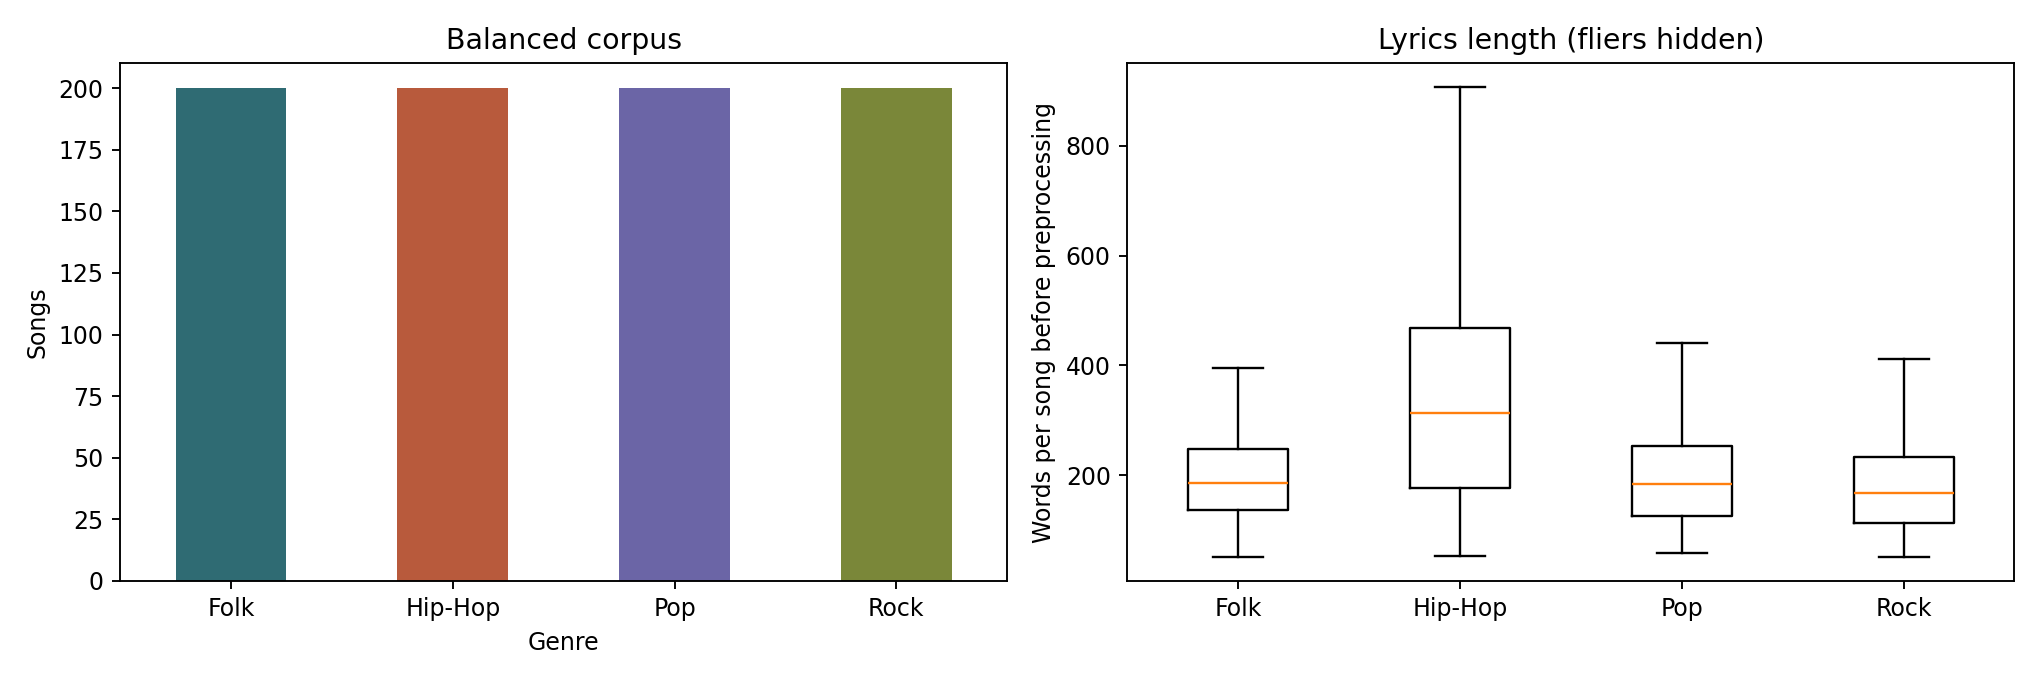

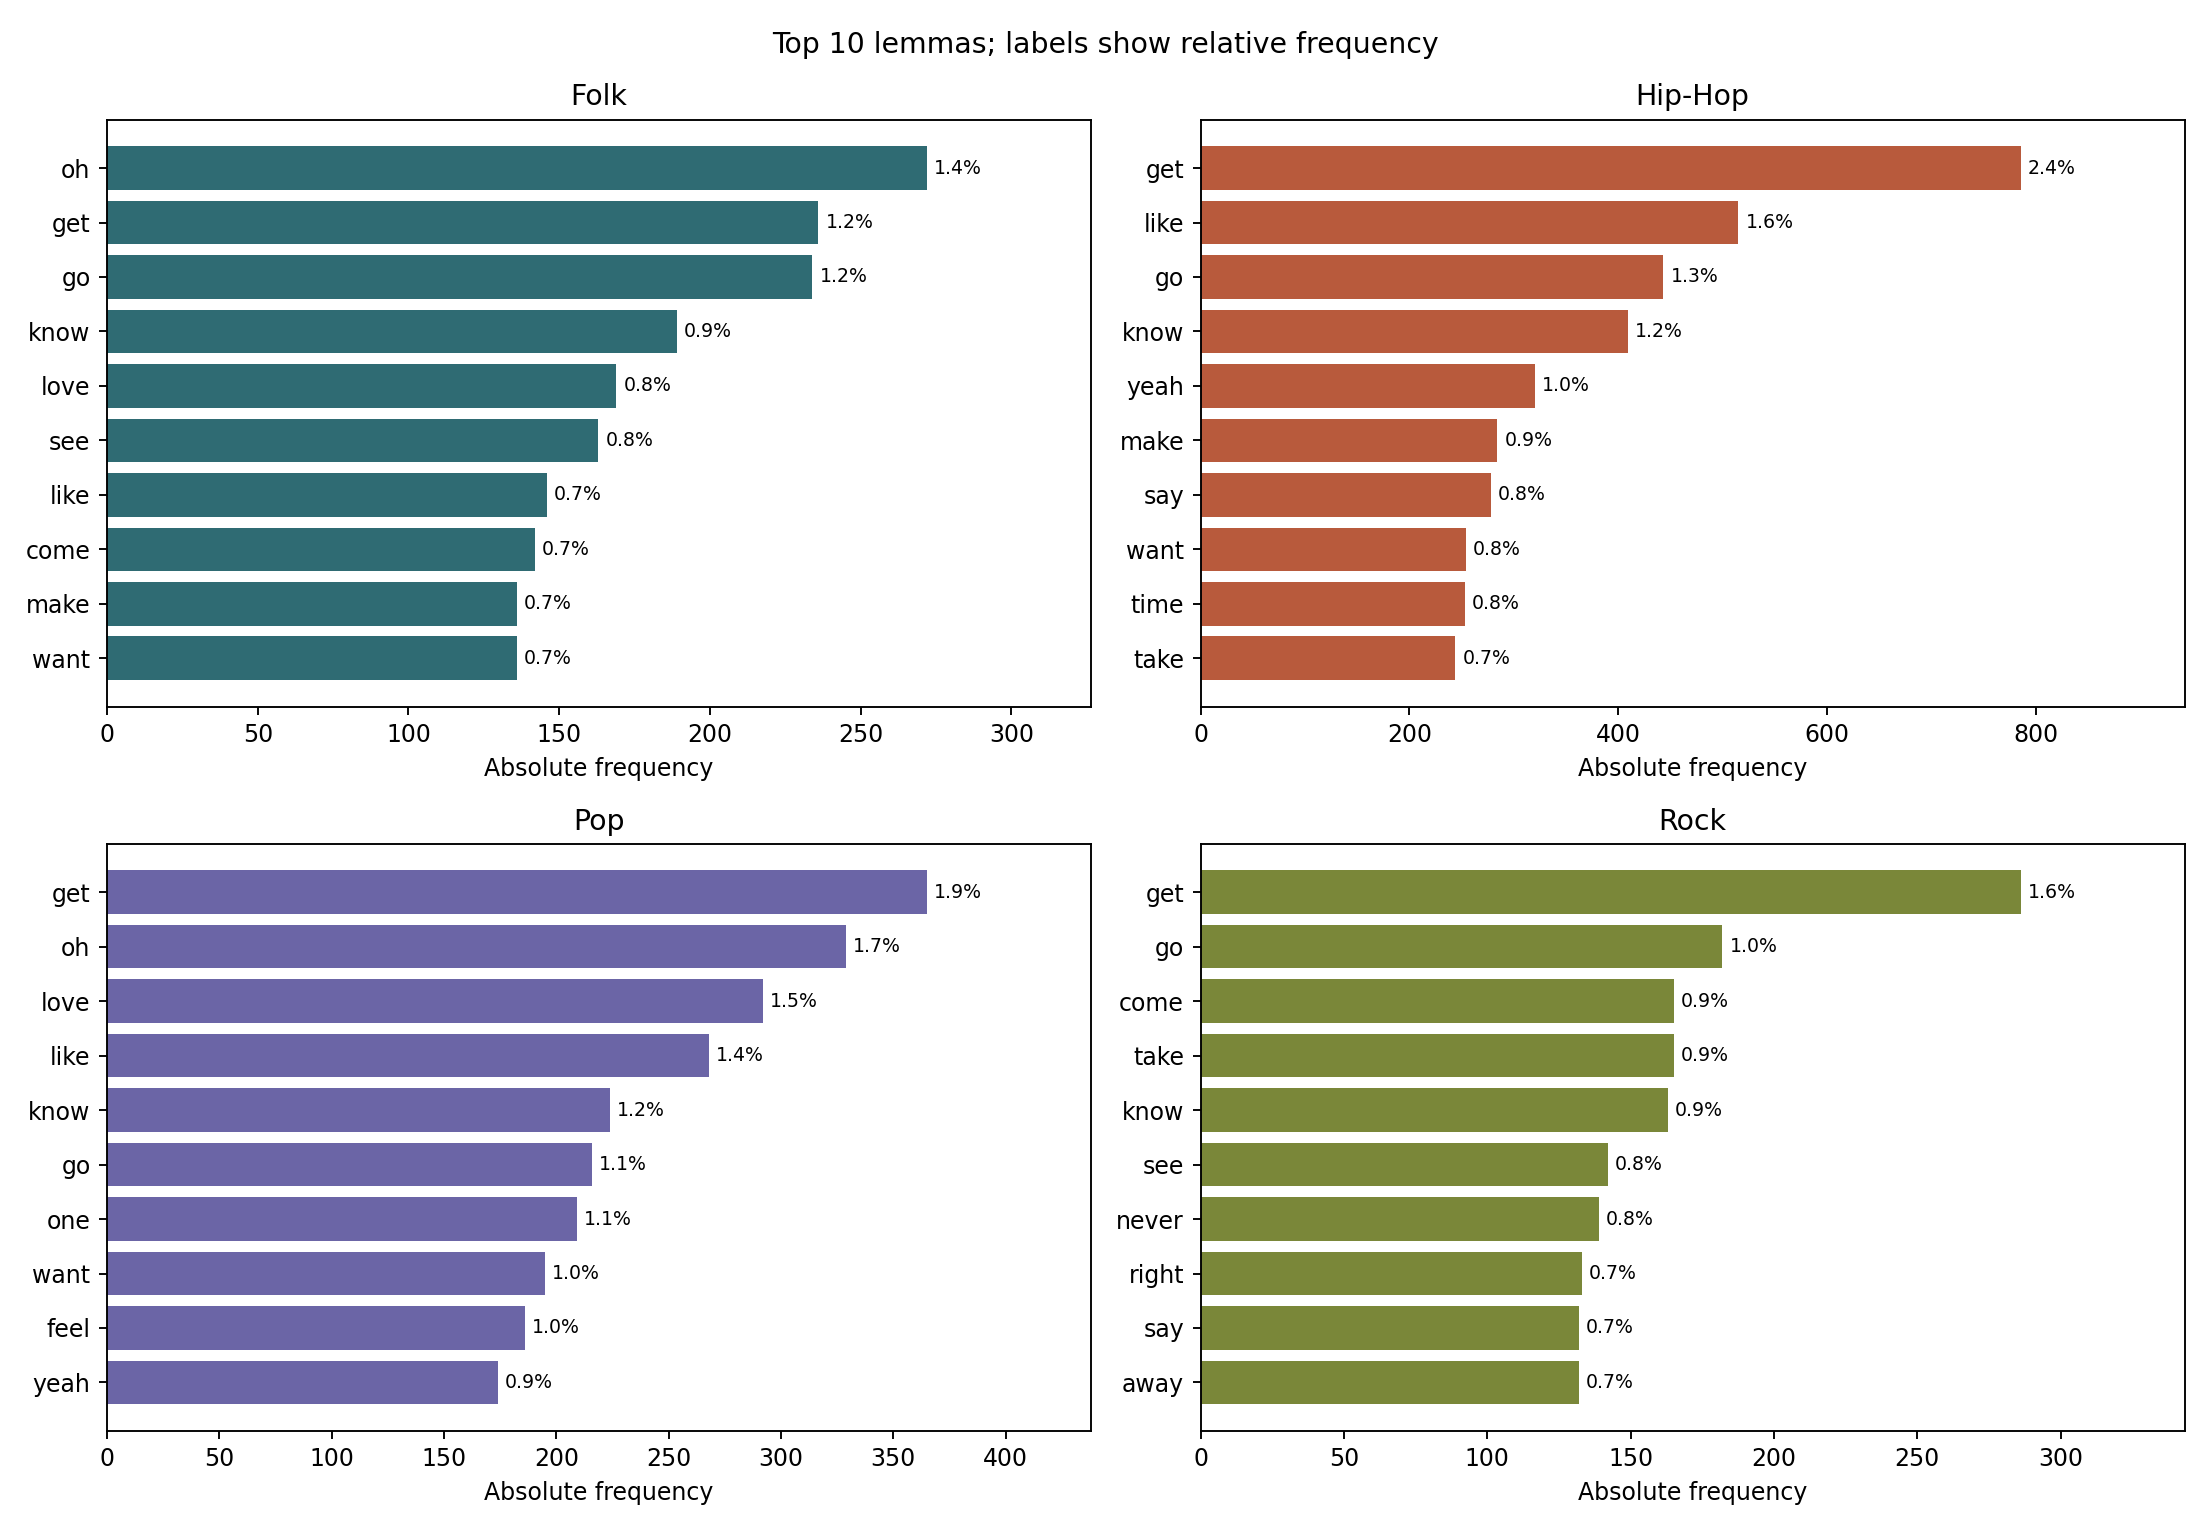

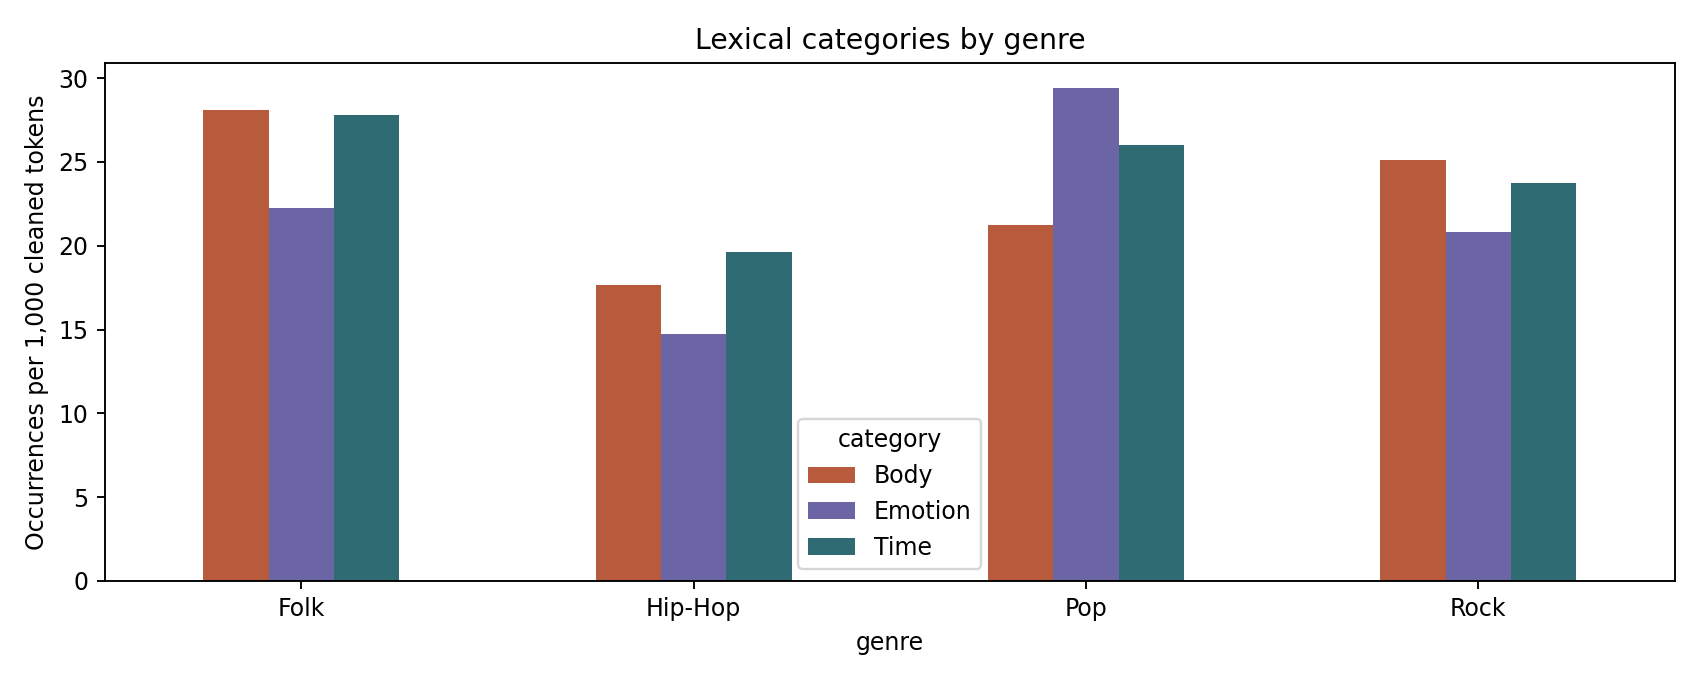

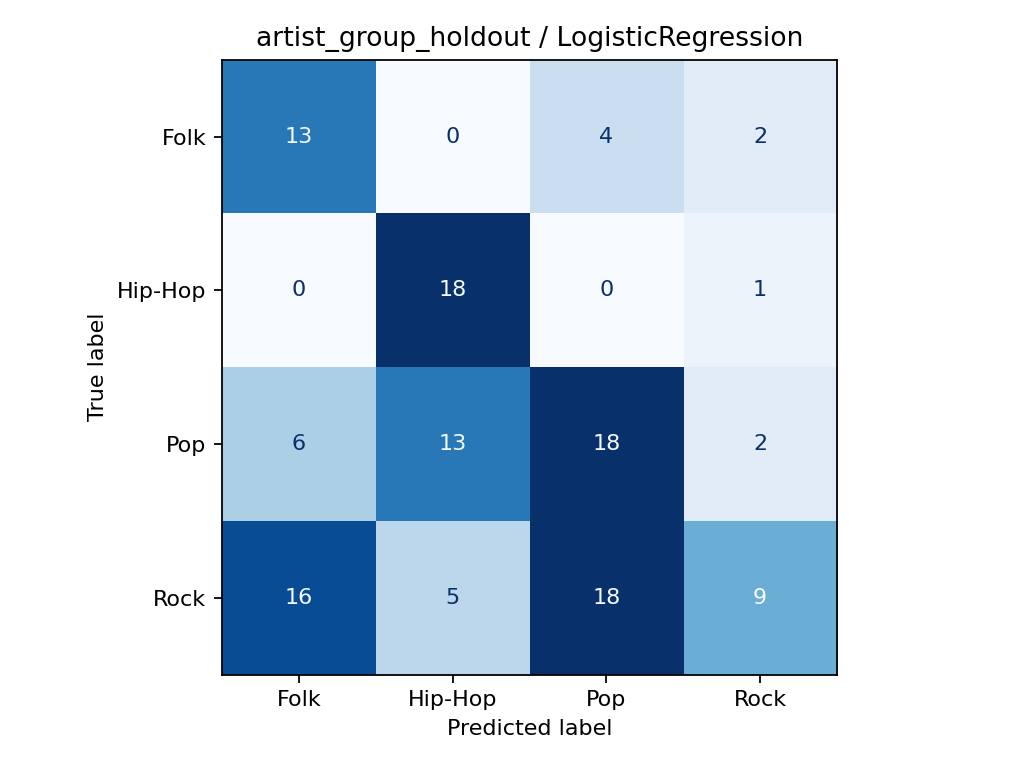

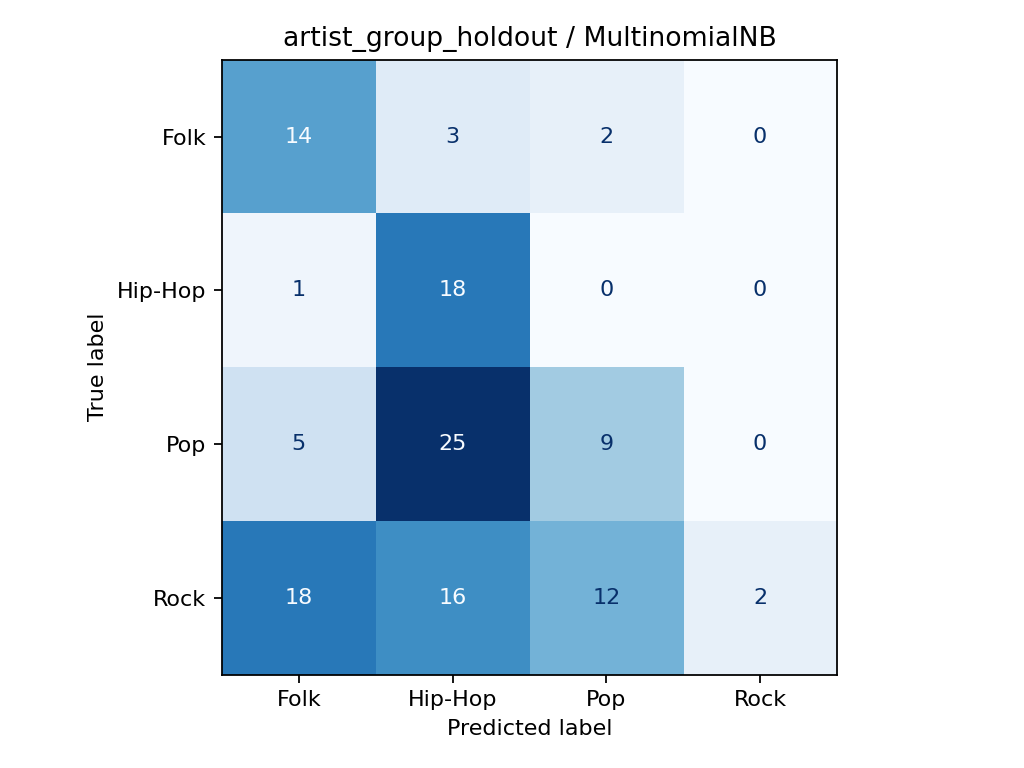

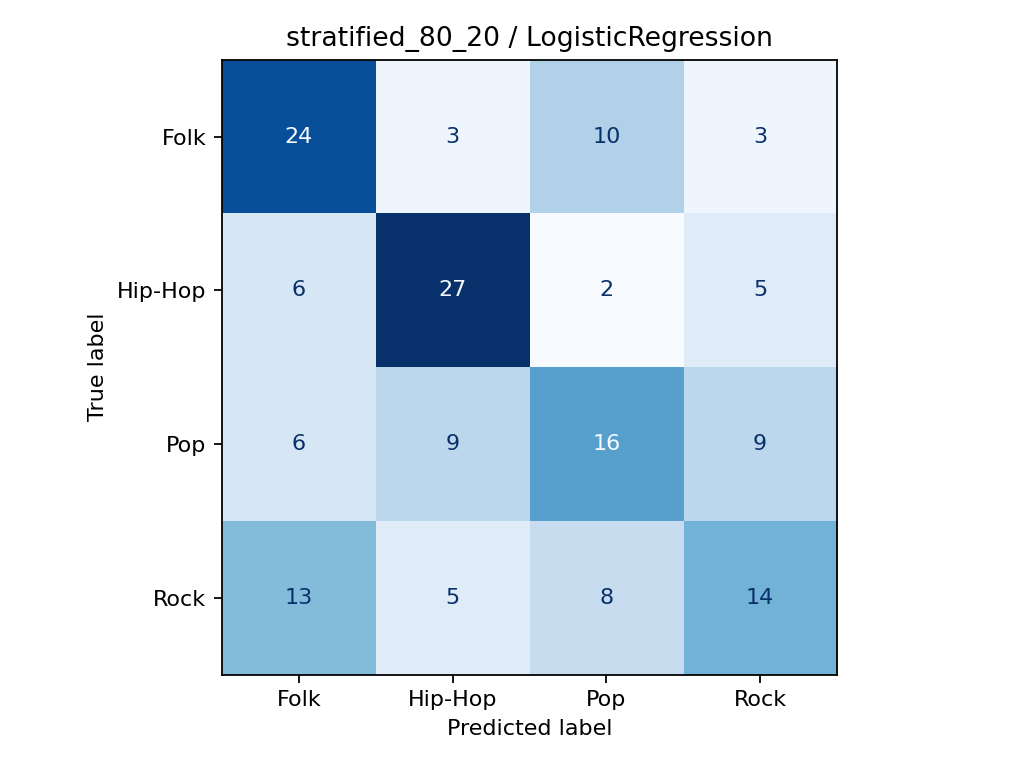

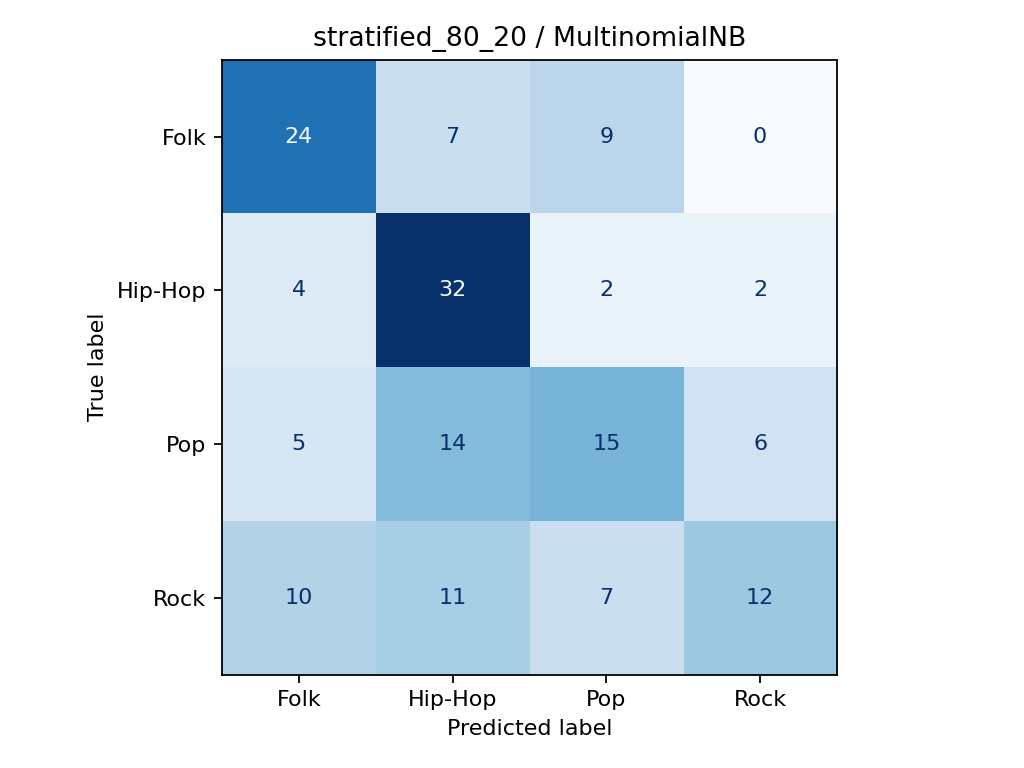

## 4. Определение языка и устойчивость

**Данные:** [WiLI-2018](https://doi.org/10.5281/zenodo.841984),
казахский, русский, английский, испанский, португальский и турецкий. После глобального удаления дублей
выбраны 873 текста каждого языка, всего 5 238; train/test=80/20 со стратификацией, seed=42.
Испанский и португальский образуют дополнительную пару близких языков.

**Методы:** минимальная и интенсивная предобработка; word TF-IDF и char n-grams (1-3);
Naive Bayes и Logistic Regression. Это 8 комбинаций. Unicode-буквы, включая казахские, сохраняются
при обеих стратегиях. Выбор конфигурации выполняется CV внутри train, итоговая оценка - на test.
Тот же test используется для [fastText lid.176](https://fasttext.cc/docs/en/language-identification.html).
Его предобучение на Wikipedia могло пересекаться с WiLI, поэтому результаты не доказывают независимую обобщающую способность.

Устойчивость проверяется на исходных длинах и сопоставимых префиксах тех же текстов, а также при
контролируемых опечатках. 30 смешанных казахско-русских предложений оцениваются качественно.
После расчёта доступна `t4_predict_text("Қазақстан")`.

В ячейках ниже содержится полная реализация. После запуска показаны рассчитанные результаты и их интерпретация.

In [39]:
"""Assignment 3, task 4: executed, reproducible language identification study.

Run: python assignment3/task4_language.py
The first run downloads official WiLI-2018 and fastText assets if absent.
"""
from pathlib import Path
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import re
import sys
import time
import unicodedata
import urllib.request
import zipfile

ROOT = Path.cwd()
if not (ROOT / 'task1_sentiment.py').exists() and (ROOT / 'assignment3').is_dir():
    ROOT = ROOT / 'assignment3'
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "data" / "task4" / ".matplotlib"))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits

T4_DATA = ROOT / "data" / "task4"
T4_OUT = ROOT / "results" / "task4"
T4_SEED = 42
T4_LANGS = {"kaz": "kk", "rus": "ru", "eng": "en", "spa": "es", "por": "pt", "tur": "tr"}
T4_LABELS = ["kk", "ru", "en", "es", "pt", "tr"]
T4_NAMES = {"kk": "Kazakh", "ru": "Russian", "en": "English", "es": "Spanish", "pt": "Portuguese", "tr": "Turkish"}
T4_SYSTEM = {}
T4_URLS = {
    "dataset": "https://zenodo.org/records/841984/files/wili-2018.zip?download=1",
    "dataset_record": "https://zenodo.org/records/841984",
    "paper": "https://arxiv.org/abs/1801.07779",
    "fasttext": "https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.ftz",
    "fasttext_documentation": "https://fasttext.cc/docs/en/language-identification.html",
}
T4_ATTRIBUTION = {
    'dataset_author': 'Martin Thoma',
    'dataset': 'WiLI-2018 (2018), DOI 10.5281/zenodo.841984',
    'dataset_license': 'ODbL, as declared by the author dataset card',
    'dataset_license_source': 'https://huggingface.co/datasets/MartinThoma/wili_2018',
    'underlying_texts': 'Wikipedia paragraphs; original contributor attribution and article licenses apply',
    'fasttext_model_license': 'CC BY-SA 3.0',
    'fasttext_model_authors': 'Armand Joulin, Edouard Grave, Piotr Bojanowski, Tomas Mikolov and collaborators',
    'fasttext_model_license_source': 'https://fasttext.cc/docs/en/language-identification.html',
}


In [40]:
def t4_minimal(text):
    """Preserve case, punctuation and every Unicode letter, clean formatting only."""
    text = unicodedata.normalize("NFC", str(text)).replace("\ufeff", "").replace("\u200b", "")
    return " ".join(text.split())


In [41]:
def t4_aggressive(text):
    """Remove digits/punctuation/symbols, while retaining ALL Unicode letters."""
    return " ".join("".join(c if c.isalpha() or c.isspace() else " " for c in t4_minimal(text).lower()).split())


In [42]:
def t4_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


In [43]:
def t4_download(url, path):
    path = Path(path)
    if not path.exists():
        print("Downloading", path.name, flush=True)
        partial = path.with_suffix(path.suffix + ".partial")
        urllib.request.urlretrieve(url, partial)
        partial.replace(path)


In [44]:
def t4_load_data():
    archive = T4_DATA / "wili-2018.zip"
    cached_csv = T4_DATA / "selected_corpus.csv"
    cached_meta = T4_DATA / "selected_corpus_metadata.json"
    # The compact submission contains the exact selected corpus, not the whole
    # 62 MB source archive. Verify its provenance and invariants before reuse.
    if not archive.exists() and cached_csv.exists() and cached_meta.exists():
        metadata = json.loads(cached_meta.read_text(encoding="utf-8"))
        assert t4_sha256(cached_csv) == metadata["selected_corpus_sha256"], "Cached corpus was modified"
        df = pd.read_csv(cached_csv, keep_default_na=False)
        stats = metadata["dataset_statistics"]
        assert set(df.language) == set(T4_LABELS)
        assert df.language.value_counts().to_dict() == {label: stats["selected_per_language"] for label in T4_LABELS}
        assert stats["selected_per_language"] >= 500
        assert len(df) == stats["selected_rows"] and df.dedup_key.is_unique
        assert not (df.dedup_key.str.len() == 0).any()
        assert df.dedup_key.tolist() == df.text.map(lambda s: t4_aggressive(s).casefold()).tolist()
        assert int((df.split == "train").sum()) == stats["train_rows"]
        assert int((df.split == "test").sum()) == stats["test_rows"]
        assert set(df.split) == {"train", "test"}
        assert not set(df[df.split == "train"].dedup_key) & set(df[df.split == "test"].dedup_key)
        print("Task 4: verified compact cached corpus (no download needed)", flush=True)
        return df, stats
    t4_download(T4_URLS["dataset"], archive)
    # Check the checksum published by the dataset author on Zenodo.
    with archive.open("rb") as stream:
        md5 = hashlib.file_digest(stream, "md5").hexdigest()
    assert md5 == "3dc5bd41587811ad6b0d04ae2f235f84", "WiLI archive incomplete or checksum mismatch"
    records = []
    with zipfile.ZipFile(archive) as z:
        for source_split in ("train", "test"):
            text_name = next(n for n in z.namelist() if n.endswith(f"x_{source_split}.txt"))
            label_name = next(n for n in z.namelist() if n.endswith(f"y_{source_split}.txt"))
            texts = z.read(text_name).decode("utf-8").splitlines()
            labels = z.read(label_name).decode("utf-8").splitlines()
            assert len(texts) == len(labels)
            for i, (text, label) in enumerate(zip(texts, labels)):
                if label.strip() in T4_LANGS:
                    records.append({"source_id": f"{source_split}:{i}", "text": t4_minimal(text),
                                    "language": T4_LANGS[label.strip()], "original_split": source_split})
    df = pd.DataFrame(records)
    before = len(df)
    # Normalization handles whitespace artifacts. The stricter key also prevents
    # near-exact case/punctuation variants from crossing the local split.
    df["dedup_key"] = df["text"].map(lambda s: t4_aggressive(s).casefold())
    empty = int((df.dedup_key.str.len() == 0).sum())
    df = df[df.dedup_key.str.len() > 0].copy()
    duplicate_count = int(df.duplicated("dedup_key").sum())
    # Drop every occurrence of contradictory labels rather than arbitrarily selecting one.
    conflict_keys = df.groupby("dedup_key").language.nunique()
    conflict_keys = set(conflict_keys[conflict_keys > 1].index)
    df = df[~df.dedup_key.isin(conflict_keys)].drop_duplicates("dedup_key").copy()
    # WiLI provides 1000 per language before deduplication. Cap at 900 and at
    # the smallest remaining class to retain balance after deduplication.
    per_language = min(900, int(df.language.value_counts().min()))
    assert per_language >= 500
    df = df.groupby("language", group_keys=False).sample(n=per_language, random_state=T4_SEED)
    df = df.sample(frac=1, random_state=T4_SEED).reset_index(drop=True)
    df["word_count"] = df.text.map(lambda s: len(re.findall(r"[^\W\d_]+", s, flags=re.UNICODE)))
    train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=.2, stratify=df.language, random_state=T4_SEED)
    df["split"] = "train"
    df.loc[test_idx, "split"] = "test"
    assert not set(df.loc[train_idx, "dedup_key"]) & set(df.loc[test_idx, "dedup_key"])
    df.to_csv(T4_DATA / "selected_corpus.csv", index=False, encoding="utf-8")
    stats = {"raw_six_language_rows": before, "empty_removed": empty,
             "official_archive_md5_verified": md5,
             "duplicate_rows_before_conflict_removal": duplicate_count,
             "conflicting_normalized_keys_removed": len(conflict_keys),
             "selected_per_language": per_language, "selected_rows": len(df),
             "train_rows": len(train_idx), "test_rows": len(test_idx),
             "split_policy": "pool original WiLI train+test; deduplicate globally; new stratified 80/20 split, seed 42"}
    metadata = {"dataset_statistics": stats, "source_urls": T4_URLS, "attribution": T4_ATTRIBUTION,
                "original_archive_sha256": t4_sha256(archive),
                "selected_corpus_sha256": t4_sha256(cached_csv)}
    cached_meta.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    return df, stats


In [45]:
def t4_make_pipeline(preprocessing, representation, classifier):
    processor = t4_minimal if preprocessing == "minimal" else t4_aggressive
    vectorizer = TfidfVectorizer(
        preprocessor=processor, lowercase=False,
        analyzer="word" if representation == "word" else "char",
        ngram_range=(1, 1) if representation == "word" else (1, 3),
        token_pattern=r"(?u)\b\w+\b" if representation == "word" else None, min_df=2,
        max_features=60000 if representation == "word" else 40000,
        sublinear_tf=True, dtype=np.float64)
    estimator = MultinomialNB(alpha=.5) if classifier == "NB" else LogisticRegression(C=4.0, max_iter=1000, solver="lbfgs", random_state=T4_SEED)
    return Pipeline([("tfidf", vectorizer), ("classifier", estimator)])


In [46]:
def t4_metrics(y, pred):
    return {"accuracy": float(accuracy_score(y, pred)), "macro_f1": float(f1_score(y, pred, labels=T4_LABELS, average="macro", zero_division=0))}


In [47]:
def t4_noise(text, rate, seed, mode="mixed"):
    """Seeded edits of a chosen fraction of letters, no access to true labels."""
    rng = random.Random(seed)
    positions = [i for i, c in enumerate(text) if c.isalpha()]
    if not positions or rate == 0:
        return text
    chosen = set(rng.sample(positions, min(len(positions), max(1, round(rate * len(positions))))))
    alphabet = sorted(set(c.lower() for c in text if c.isalpha()))
    out = []
    for i, c in enumerate(text):
        if i not in chosen:
            out.append(c)
            continue
        action = rng.choice(["delete", "insert", "replace"]) if mode == "mixed" else mode
        alternatives = [letter for letter in alphabet if letter != c.lower()]
        replacement = rng.choice(alternatives or alphabet)
        if action == "insert": out.append(c + replacement)
        elif action == "replace": out.append(replacement)
    return "".join(out)


In [48]:
def t4_fasttext_predict(model, texts, include_confidence=False):
    labels, confidence = [], []
    for text in texts:
        # fastText's Python interface accepts a single line per example.
        line = t4_minimal(text) or " "
        try:
            result_labels, probabilities = model.predict(line, k=1)
            label, probability = result_labels[0], probabilities[0]
        except ValueError as exc:
            # Upstream fastText 0.9.2's scalar wrapper uses np.array(copy=False),
            # incompatible with NumPy 2. Its list-input branch avoids that path.
            if 'copy' not in str(exc).lower():
                raise
            result_labels, probabilities = model.predict([line], k=1)
            label, probability = result_labels[0][0], probabilities[0][0]
        labels.append(label.replace("__label__", ""))
        confidence.append(float(probability))
    return (np.array(labels), confidence) if include_confidence else np.array(labels)


In [49]:
def t4_load_fasttext_model():
    # The Windows C++ binding cannot open a non-ASCII absolute path. Python can
    # change into the Unicode directory, then fastText opens an ASCII basename.
    import fasttext
    previous_directory = Path.cwd()
    try:
        os.chdir(T4_DATA)
        return fasttext.load_model("lid.176.ftz")
    finally:
        os.chdir(previous_directory)


In [50]:
def t4_predict_text(text):
    """Public demo API, available after t4_main() in the same Python session.

    Scores are internal model scores, not calibrated correctness probabilities.
    """
    if not T4_SYSTEM:
        raise RuntimeError("Run t4_main() before t4_predict_text().")
    if not isinstance(text, str) or not text.strip():
        raise ValueError("Enter a non-empty text string.")
    model = T4_SYSTEM["pipeline"]
    language = str(model.predict([text])[0])
    ft_labels, ft_confidence = t4_fasttext_predict(T4_SYSTEM["fasttext"], [text], True)
    return {"text": text, "language": language, "language_name": T4_NAMES[language],
            "confidence": float(model.predict_proba([text]).max()),
            "model": T4_SYSTEM["name"], "fasttext_language": str(ft_labels[0]),
            "fasttext_confidence": float(ft_confidence[0]),
            "confidence_note": "Uncalibrated model score; short or mixed text may be ambiguous."}


In [51]:
def t4_plot_confusions(predictions, y):
    fig, axes = plt.subplots(3, 3, figsize=(14, 13), constrained_layout=True)
    for ax, (name, pred) in zip(axes.flat, predictions.items()):
        # Outputs outside the six target languages remain errors, visible as Other.
        collapsed = [p if p in T4_LABELS else "other" for p in pred]
        labels = T4_LABELS + (["other"] if "other" in collapsed else [])
        cm = confusion_matrix(y, collapsed, labels=labels)
        ax.imshow(cm, cmap="Blues")
        ax.set_xticks(range(len(labels)), labels, rotation=45)
        ax.set_yticks(range(len(labels)), labels)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        ax.set_title(name, fontsize=10)
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8,
                        color="white" if cm[i, j] > cm.max()/2 else "black")
        pd.DataFrame(cm, index=labels, columns=labels).to_csv(T4_OUT / f"confusion_{name}.csv", encoding="utf-8")
    fig.savefig(T4_OUT / "confusion_matrices.png", dpi=160)
    plt.close(fig)


In [52]:
def t4_code_switch_cases():
    # Original authored material, not an evaluation corpus with a single gold label.
    return [
        "Бүгін сабақтан кейін я пойду в библиотеку.",
        "Мен тапсырманы аяқтадым, но файл пока не отправил.",
        "Ертең кездесейік, если у тебя будет время.",
        "Бұл модель жақсы жұмыс істейді, но иногда путает языки.",
        "Маған жаңа кітап ұнады, особенно последняя глава.",
        "Қазір жаңбыр жауып тұр, поэтому возьми зонт.",
        "Біз бүгін Python үйрендік и написали первую программу.",
        "Сен деректерді тазаладың ба, или ещё не начал?",
        "Менің телефоным өшіп қалды, зарядка осталась дома.",
        "Осы сөзді түсінбедім, объясни пожалуйста.",
        "Апай жаңа тақырыпты түсіндірді, а я сделал заметки.",
        "Бүгін ауа райы жақсы, можно прогуляться после работы.",
        "Маған бір кесе шай беріңіз, без сахара пожалуйста.",
        "Келесі аптада емтихан бар, нужно повторить материал.",
        "Бұл сөйлем екі тілде жазылған, и это обычная практика.",
        "Сегодня мен университетке ерте келдім.",
        "Я скачал деректер жиынын кеше кешке.",
        "Давай сначала мәтінді оқып шығайық.",
        "В библиотеке жаңа кітаптар көп екен.",
        "Мне понравилось, қалай сен мәселені түсіндірдің.",
        "Если всё получится, ертең нәтижені көрсетемін.",
        "Мы решили, бұл әдісті тағы тексеру керек.",
        "Почему бұл бағдарлама баяу жұмыс істейді?",
        "После обеда біз зертханаға барамыз.",
        "Не забудь, тапсырманы бүгін тапсыру қажет.",
        "Я думаю, қазақша мәтінге басқа тәсіл керек.",
        "Получилось жақсы, бірақ бірнеше қате қалды.",
        "Вчера ол маған жаңа сөздерді үйретті.",
        "Пожалуйста, осы файлды маған жібер.",
        "Мы проверили модель, енді қорытынды жазамыз.",
    ]


In [53]:
def t4_error_reason(row):
    reviewed_examples = {
        "train:87814": "Вручную просмотренный текст - немецкая библиографическая запись, хотя метка WiLI es. fastText предсказывает de. У шестиклассовой модели нет немецкого класса, поэтому её pt нельзя объяснять только сходством испанского и португальского: здесь важны цитирование другого языка и качество метки.",
        "test:44412": "Турецкая рамка библиографической ссылки соседствует с английским названием и служебными словами сайта. Символьная LR выбирает en, тогда как fastText распознаёт tr. Английская часть ссылки даёт сильный конкурирующий сигнал.",
        "train:107466": "Большая русская цитата названия диссертации завершается казахской фразой. Все девять систем выбирают ru при метке источника kk. Это реальное смешение языков: единая метка раздела Wikipedia не описывает состав каждого фрагмента.",
        "test:113636": "Английские имена авторов и название книги занимают большую часть ссылки, но присутствуют турецкие слова. Словарные NB/LR с минимальной обработкой и fastText выбирают tr, символьная LR - en. Символы могут переоценить преобладающую английскую часть.",
        "train:80966": "Библиографическая запись почти полностью английская; русская часть ограничена пометкой языка. Все модели выбирают en при метке WiLI ru. Ошибка по исходной метке не означает, что система неправильно определила язык большей части текста.",
        "test:69731": "Фрагмент испанского раздела Wikipedia содержит английскую запись о музыкальном релизе. Все модели выбирают en. Здесь анализ содержимого выявляет расхождение между меткой источника es и фактическим языком отрывка.",
        "test:52754": "Цитата представляет собой французскую библиографическую запись при метке WiLI es. fastText выбирает fr, все модели с шестью классами - pt. Французский отсутствует среди обучаемых классов, поэтому матрица es/pt смешивает ошибки разметки/цитирования и собственно путаницу близких языков.",
        "train:3943": "Весь просмотренный абзац написан по-английски, несмотря на метку WiLI tr. Все девять моделей выбирают en. Такой пример показывает ограничение меток, полученных по языковому разделу Wikipedia, и необходимость ручного аудита ошибок.",
    }
    if row.source_id in reviewed_examples:
        return reviewed_examples[row.source_id]
    if row.true in ["es", "pt"] and row.predicted in ["es", "pt"]:
        return "Испанский и португальский имеют общие корни и похожие буквенные сочетания. Проверить заимствования и короткие контекстные признаки."
    if row.true in ["kk", "ru"] and row.predicted in ["kk", "ru"]:
        return "Оба языка используют кириллицу. Общие имена и русские заимствования могут перевесить ограниченное число специфических казахских букв."
    if row.word_count <= 10:
        return "Короткий фрагмент содержит мало характерных n-грамм; имена, аббревиатуры и общая лексика дают неоднозначный сигнал."
    if any(c.isdigit() for c in row.text) or len(re.findall(r"[A-ZА-Я]{2,}", row.text)):
        return "Числа, аббревиатуры и имена снижают долю языковых признаков. Словарные признаки чувствительны к неизвестным формам."
    return "Абзац может содержать заимствования, цитаты или другой язык внутри текста Wikipedia. Метка источника относится к разделу Wikipedia и не гарантирует однородности каждого фрагмента."


In [54]:
@threadpool_limits.wrap(limits=2)
def t4_main():
    T4_DATA.mkdir(parents=True, exist_ok=True)
    T4_OUT.mkdir(parents=True, exist_ok=True)
    np.random.seed(T4_SEED); random.seed(T4_SEED)
    assert t4_aggressive("Әә Ғғ Ққ Ңң Өө Ұұ Үү Һһ Іі ə 123!") == "әә ғғ ққ ңң өө ұұ үү һһ іі ə"
    print("Task 4: load and deduplicate WiLI-2018", flush=True)
    df, stats = t4_load_data()
    train, test = df[df.split == "train"].copy(), df[df.split == "test"].copy()
    X_train, y_train = train.text.tolist(), train.language.to_numpy()
    X_test, y_test = test.text.tolist(), test.language.to_numpy()
    distribution = df.groupby(["language", "split"]).size().unstack(fill_value=0)
    distribution.to_csv(T4_OUT / "class_distribution.csv")
    lengths = df.groupby("language").word_count.describe()
    lengths.to_csv(T4_OUT / "length_distribution.csv")
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.boxplot([df[df.language == l].word_count for l in T4_LABELS], tick_labels=T4_LABELS, showfliers=False)
    ax.set_ylabel("Words per paragraph"); ax.set_title("WiLI-2018: paragraph length by language")
    fig.tight_layout(); fig.savefig(T4_OUT / "text_lengths.png", dpi=160); plt.close(fig)
    configs, models, predictions, rows = {}, {}, {}, []
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=T4_SEED)
    for preprocessing in ["minimal", "aggressive"]:
        for representation in ["word", "char1-3"]:
            for classifier in ["NB", "LR"]:
                name = f"{preprocessing}_{representation}_{classifier}"
                print("Task 4: train", name, flush=True)
                pipeline = t4_make_pipeline(preprocessing, representation, classifier)
                start = time.perf_counter()
                cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=1)
                pipeline.fit(X_train, y_train)
                pred = pipeline.predict(X_test)
                row = {"model": name, "preprocessing": preprocessing, "representation": representation,
                       "classifier": classifier, "train_cv_macro_f1": float(cv_scores.mean()),
                       "cv_std": float(cv_scores.std()), **t4_metrics(y_test, pred),
                       "fit_and_cv_seconds": time.perf_counter() - start,
                       "vocabulary_size": len(pipeline.named_steps["tfidf"].vocabulary_)}
                models[name] = pipeline; predictions[name] = pred; rows.append(row)
                configs[name] = {"tfidf": {k: str(v) for k, v in pipeline.named_steps["tfidf"].get_params().items()},
                                 "classifier": pipeline.named_steps["classifier"].get_params()}
    # Select on TRAIN-only cross-validation, never tune on the test set.
    best_name = max(rows, key=lambda row: row["train_cv_macro_f1"])["model"]
    t4_download(T4_URLS["fasttext"], T4_DATA / "lid.176.ftz")
    fasttext_model = t4_load_fasttext_model()
    T4_SYSTEM.update({"pipeline": models[best_name], "name": best_name, "fasttext": fasttext_model})
    fasttext_pred, fasttext_confidence = t4_fasttext_predict(fasttext_model, X_test, include_confidence=True)
    predictions["fastText_lid176"] = fasttext_pred
    rows.append({"model": "fastText_lid176", "preprocessing": "minimal", "representation": "pretrained",
                 "classifier": "fastText", "train_cv_macro_f1": np.nan, "cv_std": np.nan,
                 **t4_metrics(y_test, fasttext_pred), "fit_and_cv_seconds": 0, "vocabulary_size": np.nan})
    metrics = pd.DataFrame(rows)
    metrics.to_csv(T4_OUT / "model_comparison.csv", index=False)
    prediction_frame = test[["source_id", "text", "language", "word_count"]].copy().rename(columns={"language": "true"})
    for name, pred in predictions.items(): prediction_frame[name] = pred
    prediction_frame["fastText_confidence"] = fasttext_confidence
    prediction_frame.to_csv(T4_OUT / "test_predictions.csv", index=False, encoding="utf-8")
    reports = {name: classification_report(y_test, pred, labels=T4_LABELS, output_dict=True, zero_division=0) for name, pred in predictions.items()}
    (T4_OUT / "classification_reports.json").write_text(json.dumps(reports, ensure_ascii=False, indent=2), encoding="utf-8")
    t4_plot_confusions(predictions, y_test)
    fig, ax = plt.subplots(figsize=(11, 5))
    positions = np.arange(len(metrics))
    ax.bar(positions-.18, metrics.accuracy, width=.36, label="Accuracy")
    ax.bar(positions+.18, metrics.macro_f1, width=.36, label="Macro F1")
    ax.set_xticks(positions, metrics.model, rotation=35, ha="right", fontsize=8)
    ax.set_ylim(0, 1.03); ax.legend(); ax.set_title("Language identification on one held-out test set")
    fig.tight_layout(); fig.savefig(T4_OUT / "model_comparison.png", dpi=160); plt.close(fig)
    # Natural lengths may have too few short paragraphs: report n explicitly.
    length_rows = []
    bins = pd.cut(test.word_count, bins=[0, 3, 10, np.inf], labels=["1-3", "4-10", ">10"])
    for name, pred in predictions.items():
        for group in ["1-3", "4-10", ">10"]:
            mask = (bins == group).to_numpy()
            length_rows.append({"model": name, "condition": "natural", "length": group, "n": int(mask.sum()),
                                **(t4_metrics(y_test[mask], pred[mask]) if mask.any() else {"accuracy": np.nan, "macro_f1": np.nan})})
    # Paired prefixes isolate length while holding paragraph IDs and labels fixed.
    # Only paragraphs with >10 whitespace-delimited words enter this paired set,
    # ensuring that the 3-word and 10-word conditions have their stated lengths.
    paired_mask = np.array([len(text.split()) > 10 for text in X_test])
    paired_texts = [text for text, keep in zip(X_test, paired_mask) if keep]
    paired_y = y_test[paired_mask]
    for length, words in [("1-3", 3), ("4-10", 10), (">10/full", None)]:
        shortened = [" ".join(text.split()[:words]) if words else text for text in paired_texts]
        for name in list(models) + ["fastText_lid176"]:
            pred = models[name].predict(shortened) if name in models else t4_fasttext_predict(fasttext_model, shortened)
            length_rows.append({"model": name, "condition": "paired_prefix", "length": length, "n": len(paired_y), **t4_metrics(paired_y, pred)})
    length_metrics = pd.DataFrame(length_rows)
    length_metrics.to_csv(T4_OUT / "length_robustness.csv", index=False)
    # Exactly the same corruptions are supplied to every model.
    noise_rows, noise_examples = [], []
    conditions = [("mixed", rate) for rate in [0, .05, .10, .20]] + [(mode, .10) for mode in ["delete", "insert", "replace"]]
    for mode, rate in conditions:
        print("Task 4: noise", mode, rate, flush=True)
        modified = [t4_noise(text, rate, T4_SEED + i, mode) for i, text in enumerate(X_test)]
        if mode == "mixed" and rate == .10:
            noise_examples = [{"source_id": sid, "original": original, "noisy": noisy, "true": label} for sid, original, noisy, label in zip(test.source_id, X_test, modified, y_test)]
        for name in list(models) + ["fastText_lid176"]:
            pred = models[name].predict(modified) if name in models else t4_fasttext_predict(fasttext_model, modified)
            noise_rows.append({"model": name, "noise_mode": mode, "edit_rate": rate, "n": len(test), **t4_metrics(y_test, pred)})
    noise_metrics = pd.DataFrame(noise_rows)
    noise_metrics.to_csv(T4_OUT / "noise_robustness.csv", index=False)
    pd.DataFrame(noise_examples).to_csv(T4_OUT / "noise_examples.csv", index=False, encoding="utf-8")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
    for name in list(models) + ["fastText_lid176"]:
        subset = length_metrics[(length_metrics.model == name) & (length_metrics.condition == "paired_prefix")]
        axes[0].plot(subset.length, subset.accuracy, marker="o", label=name)
        subset = noise_metrics[(noise_metrics.model == name) & (noise_metrics.noise_mode == "mixed")]
        axes[1].plot(subset.edit_rate, subset.accuracy, marker="o", label=name)
    axes[0].set(title="Paired length experiment", ylabel="Accuracy", xlabel="Words/prefix")
    axes[1].set(title="Controlled spelling noise", ylabel="Accuracy", xlabel="Fraction of edited letters")
    axes[1].legend(fontsize=7, loc="lower left")
    for ax in axes: ax.set_ylim(0, 1.02); ax.grid(alpha=.2)
    fig.savefig(T4_OUT / "robustness.png", dpi=160); plt.close(fig)
    cases = pd.DataFrame({"case_id": range(1, 31), "text": t4_code_switch_cases(),
                          "construction": ["Kazakh clause first; Russian clause second"] * 15 + ["Russian framing with Kazakh content"] * 15})
    for name, model in models.items():
        cases[name] = model.predict(cases.text.tolist())
        cases[name + "_confidence"] = model.predict_proba(cases.text.tolist()).max(axis=1)
    cases["fastText_lid176"], cases["fastText_confidence"] = t4_fasttext_predict(fasttext_model, cases.text.tolist(), True)
    cases.to_csv(T4_OUT / "code_switching_30_cases.csv", index=False, encoding="utf-8")
    # Gather actual errors across models, favoring the CV-selected system first.
    errors = []
    for name in [best_name] + [n for n in predictions if n != best_name]:
        for position, (truth, pred) in enumerate(zip(y_test, predictions[name])):
            if truth != pred:
                row = test.iloc[position]
                item = {"model": name, "source_id": row.source_id, "true": truth, "predicted": pred,
                        "word_count": int(row.word_count), "text": row.text,
                        "excerpt": " ".join(row.text.split()[:22]),
                        "all_model_predictions": {n: str(p[position]) for n, p in predictions.items()}}
                errors.append(item)
    error_df = pd.DataFrame(errors)
    assert len(error_df) >= 5, "Need five real errors, never fabricate examples"
    error_df["reason_ru"] = error_df.apply(t4_error_reason, axis=1)
    error_df.to_csv(T4_OUT / "all_errors.csv", index=False, encoding="utf-8")
    selected_errors = error_df.drop_duplicates("source_id").head(8)
    selected_errors.to_csv(T4_OUT / "error_analysis.csv", index=False, encoding="utf-8")
    best_row = metrics[metrics.model == best_name].iloc[0]
    fast_row = metrics[metrics.model == "fastText_lid176"].iloc[0]
    best_short = length_metrics[(length_metrics.model == best_name) & (length_metrics.condition == "paired_prefix") & (length_metrics.length == "1-3")].iloc[0]
    best_paired_full = length_metrics[(length_metrics.model == best_name) & (length_metrics.condition == "paired_prefix") & (length_metrics.length == ">10/full")].iloc[0]
    best_noise = noise_metrics[(noise_metrics.model == best_name) & (noise_metrics.noise_mode == "mixed") & (noise_metrics.edit_rate == .20)].iloc[0]
    word_nb_accuracy = metrics.set_index("model").loc["minimal_word_NB", "accuracy"]
    short_accuracy = length_metrics[(length_metrics.condition == "paired_prefix") & (length_metrics.length == "1-3")].set_index("model").accuracy
    interpretation = [
        "# Задание 4. Идентификация языка: реальные результаты",
        f"Источник: WiLI-2018 (Martin Thoma, 2018), DOI 10.5281/zenodo.841984. Отобраны шесть языков: казахский, русский, английский, испанский, португальский, турецкий. По {stats['selected_per_language']} уникальных абзацев на язык, всего {stats['selected_rows']}; train={stats['train_rows']}, test={stats['test_rows']}. Стратифицированное разбиение 80/20, seed=42.",
        f"Глобальная нормализованная дедупликация до разделения: {stats['duplicate_rows_before_conflict_removal']} повторов, {stats['conflicting_normalized_keys_removed']} противоречивых ключей. Пустых текстов: {stats['empty_removed']}. Исходные разделы WiLI объединены и разделены заново; идентификаторы сохранены. Словари TF-IDF и IDF обучались только внутри train, включая каждый CV fold.",
        "Минимальная обработка сохраняет регистр, пунктуацию и все Unicode-буквы, исправляет только форматирование и пробелы. Интенсивная переводит в нижний регистр и удаляет цифры, пунктуацию и символы. isalpha() сохраняет казахские ә, ғ, қ, ң, ө, ұ, ү, һ, і и ə. Для слов используются униграммы, для символов n=1..3. Unicode-буквы сохранены в обеих ветках.",
        "Восемь конфигураций зафиксированы заранее: 2 обработки × 2 представления × 2 классификатора. NB alpha=0.5; LR C=4, max_iter=1000. TF-IDF min_df=2, sublinear_tf=True, max_features=60000 для слов/40000 для символов. Выбор конфигурации сделан по 3-fold macro-F1 только на train. Отдельные гиперпараметры по test не подбирались.",
        f"Выбранная по train-CV конфигурация: {best_name}; CV macro-F1={best_row.train_cv_macro_f1:.4f}; отложенный test Accuracy={best_row.accuracy:.4f}, macro-F1={best_row.macro_f1:.4f}. Предобученный fastText lid.176.ftz на том же test: Accuracy={fast_row.accuracy:.4f}, macro-F1={fast_row.macro_f1:.4f}.",
        f"На полном test разница выбранной модели и минимальной словарной NB составляет {round((best_row.accuracy-word_nb_accuracy)*len(test))} пример(а): {best_row.accuracy:.6f} против {word_nb_accuracy:.6f} Accuracy. Такой малый разрыв не доказывает уверенного общего превосходства. Для первых трёх слов минимальная символьная LR получает {short_accuracy['minimal_char1-3_LR']:.6f} против {short_accuracy['minimal_word_LR']:.6f} у словарной LR; для NB - {short_accuracy['minimal_char1-3_NB']:.6f} против {short_accuracy['minimal_word_NB']:.6f}. Лучший результат на трёх словах: {short_accuracy.idxmax()}. Эффект представления зависит от классификатора и длины.",
        "Предсказания fastText оставлены в исходном пространстве 176 языков. Метки вне шести выбранных считаются ошибками и показаны как other в матрице. Это более трудная открытая постановка по сравнению с шестиклассовыми моделями. FastText обучен в том числе на Wikipedia, поэтому пересечение с WiLI при предобучении нельзя исключить: сравнение не доказывает обобщение на полностью новые источники. Лицензия модели CC BY-SA 3.0.",
        f"В парном эксперименте test-абзацы длиннее 10 слов (n={len(paired_y)}) усечены до первых 3 и 10 слов; дополнительно оценён полный текст тех же абзацев. Для выбранной модели Accuracy на трёх словах={best_short.accuracy:.4f}, на полном тексте={best_paired_full.accuracy:.4f}. Естественные группы длины также сохранены с количеством примеров; пустые группы имеют NaN, а не вымышленные оценки. Усечение может оставить имя/цитату вместо основного языка, поэтому это стресс-тест, а не новая размеченная выборка коротких сообщений.",
        f"Шум: seed=42+номер test-примера, 0/5/10/20% букв подвергаются удалению, вставке или замене с равной вероятностью. Буква для вставки/замены выбирается из букв самого текста без использования его метки. Все модели получают одинаковые искажения. При смешанном шуме 20% Accuracy выбранной модели={best_noise.accuracy:.4f}; изменение к чистому test={best_noise.accuracy-best_row.accuracy:+.4f}. Отдельные три вида ошибок при 10% также оценены.",
        f"Изменение Accuracy выбранной модели при шуме соответствует {round((best_noise.accuracy-best_row.accuracy)*len(test)):+d} верно классифицированному примеру и одной фиксированной реализации случайных искажений. Небольшой рост не доказывает, что ошибки полезны. Длинные абзацы сохраняют много избыточных языковых признаков, а выбранный шум сохраняет алфавит исходного текста. Транслитерация, замена алфавита и атаки на специфические буквы здесь не исследованы. Для надёжной оценки стоило бы повторить эксперимент с несколькими seeds и доверительными интервалами.",
        "Символьные признаки извлекают части неизвестных слов и специфические буквосочетания, поэтому могут быть устойчивее словарных признаков к редким формам и опечаткам. Их преимущество оценивается по таблице, а не предполагается заранее. Испанский и португальский разделяют значительную лексику, русский и казахский - кириллическую основу; специфические буквы и контекст помогают различать их.",
        "Code-switching: 30 авторских русско-казахских предложений не имеют единственной эталонной языковой метки. Сохранены все предсказания и внутренние оценки уверенности. Единственная метка скрывает состав смешанного текста, а высокий confidence не является доказательством одноязычности. Эти числа не интерпретируются как accuracy. Нужна токенная/сегментная разметка, многометочная модель либо явная категория mixed.",
        f"Распределение меток для смешанных предложений у выбранной модели: {json.dumps(cases[best_name].value_counts().to_dict(), ensure_ascii=False)}; у fastText: {json.dumps(cases['fastText_lid176'].value_counts().to_dict(), ensure_ascii=False)}. Это описательная сводка предсказаний, а не оценка правильности.",
        "## Анализ фактических ошибок (причины являются гипотезами)",
    ]
    for _, row in selected_errors.iterrows():
        interpretation.append(f"- {row.source_id}: {row.model}, истина={row.true}, прогноз={row.predicted}, слов={row.word_count}. Фрагмент: «{row.excerpt}». {row.reason_ru} Сравнение моделей: {json.dumps(row.all_model_predictions, ensure_ascii=False)}")
    interpretation += [
        "Ручной просмотр восьми ошибок выбранной модели выявил иностранные библиографические цитаты, вставки другого языка и несовпадение языка фрагмента с меткой раздела Wikipedia. Поэтому ошибки es/pt в этой выборке нельзя автоматически объяснять только близостью двух языков. Матрицу ошибок нужно читать вместе с исходным текстом; исправлять метки после просмотра test для улучшения отчётных метрик здесь не стали.",
        "Надёжность можно повысить более разнообразным корпусом, отдельной валидацией на коротких сообщениях, сегментацией смешанного текста, калибровкой confidence на отдельной валидационной выборке и отказом от уверенной метки при неоднозначности. Удаление специфических букв недопустимо. Исследование ограничено шестью языками и Wikipedia: перенос на чаты, транслитерацию и иные домены требует отдельной проверки.",
        "Полные метрики и матрицы: model_comparison.csv, classification_reports.json, confusion_matrices.png. Длина и шум: length_robustness.csv, noise_robustness.csv. Все прогнозы и примеры: test_predictions.csv, code_switching_30_cases.csv, error_analysis.csv. Точные версии, параметры и SHA-256 приведены в reproducibility.json.",
    ]
    (T4_OUT / "interpretation_ru.md").write_text("\n\n".join(interpretation), encoding="utf-8")
    package_versions = {}
    for package in ["numpy", "pandas", "scikit-learn", "matplotlib", "fasttext-predict", "fasttext-predict-v2", "fasttext-wheel"]:
        try: package_versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError: pass
    metadata = json.loads((T4_DATA / "selected_corpus_metadata.json").read_text(encoding="utf-8"))
    asset_hashes = {p.name: t4_sha256(p) for p in [T4_DATA / "lid.176.ftz", T4_DATA / "selected_corpus.csv"]}
    asset_hashes["wili-2018.zip"] = metadata["original_archive_sha256"]
    config = {"seed": T4_SEED, "python": sys.version, "platform": platform.platform(), "packages": package_versions,
              "blas_thread_limit": 2,
              "source_urls": T4_URLS, "attribution": T4_ATTRIBUTION, "dataset_statistics": stats, "selected_by_train_cv": best_name,
              "models": configs, "sha256": asset_hashes,
              "limitations": ["WiLI Wikipedia domain", "possible Wikipedia overlap with fastText pretraining", "single fixed train/test split", "prefixes inherit document language labels", "confidence is not calibrated"]}
    (T4_OUT / "reproducibility.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
    summary = {"best_by_train_cv": best_name, "test_metrics": json.loads(metrics.to_json(orient="records")), "data": stats,
               "error_count": len(error_df), "distinct_error_examples": len(selected_errors), "code_switch_cases": len(cases)}
    demos = [t4_predict_text(text) for text in [
        "Бүгін мен қазақша кітап оқып отырмын.",
        "Сегодня я читаю интересную книгу на русском языке.",
        "Today I am reading an interesting book in English.",
        "Алма",
    ]]
    summary["demo_predictions"] = demos
    (T4_OUT / "demo_predictions.json").write_text(json.dumps(demos, ensure_ascii=False, indent=2), encoding="utf-8")
    (T4_OUT / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
    print(metrics[["model", "train_cv_macro_f1", "accuracy", "macro_f1"]].to_string(index=False), flush=True)
    print("Task 4 demo:", json.dumps(demos, ensure_ascii=True), flush=True)
    print("Task 4 complete:", T4_OUT, flush=True)
    return summary


In [55]:
task4_result = t4_main()


Task 4: load and deduplicate WiLI-2018
Task 4: train minimal_word_NB
Task 4: train minimal_word_LR
Task 4: train minimal_char1-3_NB
Task 4: train minimal_char1-3_LR
Task 4: train aggressive_word_NB
Task 4: train aggressive_word_LR
Task 4: train aggressive_char1-3_NB
Task 4: train aggressive_char1-3_LR
Task 4: noise mixed 0
Task 4: noise mixed 0.05
Task 4: noise mixed 0.1
Task 4: noise mixed 0.2
Task 4: noise delete 0.1
Task 4: noise insert 0.1
Task 4: noise replace 0.1
                model  train_cv_macro_f1  accuracy  macro_f1
      minimal_word_NB           0.987917  0.991412  0.991433
      minimal_word_LR           0.987619  0.989504  0.989513
   minimal_char1-3_NB           0.983030  0.983779  0.983937
   minimal_char1-3_LR           0.990977  0.992366  0.992372
   aggressive_word_NB           0.986757  0.989504  0.989562
   aggressive_word_LR           0.988576  0.989504  0.989507
aggressive_char1-3_NB           0.982326  0.981870  0.982037
aggressive_char1-3_LR           0.9895

In [60]:
import pandas as pd
print('\nclass_distribution.csv')
print(pd.read_csv(ROOT / 'results' / 'task4' / 'class_distribution.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nmodel_comparison.csv')
print(pd.read_csv(ROOT / 'results' / 'task4' / 'model_comparison.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nlength_robustness.csv')
print(pd.read_csv(ROOT / 'results' / 'task4' / 'length_robustness.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nnoise_robustness.csv')
print(pd.read_csv(ROOT / 'results' / 'task4' / 'noise_robustness.csv').head(100).to_string(index=False,max_colwidth=120))
print('\nerror_analysis.csv')
print(pd.read_csv(ROOT / 'results' / 'task4' / 'error_analysis.csv').head(100).to_string(index=False,max_colwidth=120))
print('\ncode_switching_30_cases.csv')
print(pd.read_csv(ROOT / 'results' / 'task4' / 'code_switching_30_cases.csv')[['case_id','text','construction','minimal_char1-3_LR','fastText_lid176']].to_string(index=False,max_colwidth=120))



class_distribution.csv
language  test  train
      en   174    699
      es   174    699
      kk   175    698
      pt   175    698
      ru   175    698
      tr   175    698

model_comparison.csv
                model preprocessing representation classifier  train_cv_macro_f1   cv_std  accuracy  macro_f1  fit_and_cv_seconds  vocabulary_size
      minimal_word_NB       minimal           word         NB           0.987917 0.001733  0.991412  0.991433            1.484966          23550.0
      minimal_word_LR       minimal           word         LR           0.987619 0.001461  0.989504  0.989513            2.826855          23550.0
   minimal_char1-3_NB       minimal        char1-3         NB           0.983030 0.002492  0.983779  0.983937            7.280598          39962.0
   minimal_char1-3_LR       minimal        char1-3         LR           0.990977 0.001202  0.992366  0.992372           10.932020          39962.0
   aggressive_word_NB    aggressive           word         NB    

### Интерпретация

# Задание 4. Идентификация языка: реальные результаты

Источник: WiLI-2018 (Martin Thoma, 2018), DOI 10.5281/zenodo.841984. Отобраны шесть языков: казахский, русский, английский, испанский, португальский, турецкий. По 873 уникальных абзацев на язык, всего 5238; train=4190, test=1048. Стратифицированное разбиение 80/20, seed=42.

Глобальная нормализованная дедупликация до разделения: 135 повторов, 0 противоречивых ключей. Пустых текстов: 0. Исходные разделы WiLI объединены и разделены заново; идентификаторы сохранены. Словари TF-IDF и IDF обучались только внутри train, включая каждый CV fold.

Минимальная обработка сохраняет регистр, пунктуацию и все Unicode-буквы, исправляет только форматирование и пробелы. Интенсивная переводит в нижний регистр и удаляет цифры, пунктуацию и символы. isalpha() сохраняет казахские ә, ғ, қ, ң, ө, ұ, ү, һ, і и ə. Для слов используются униграммы, для символов n=1..3. Unicode-буквы сохранены в обеих ветках.

Восемь конфигураций зафиксированы заранее: 2 обработки × 2 представления × 2 классификатора. NB alpha=0.5; LR C=4, max_iter=1000. TF-IDF min_df=2, sublinear_tf=True, max_features=60000 для слов/40000 для символов. Выбор конфигурации сделан по 3-fold macro-F1 только на train. Отдельные гиперпараметры по test не подбирались.

Выбранная по train-CV конфигурация: minimal_char1-3_LR; CV macro-F1=0.9910; отложенный test Accuracy=0.9924, macro-F1=0.9924. Предобученный fastText lid.176.ftz на том же test: Accuracy=0.9866, macro-F1=0.9885.

На полном test разница выбранной модели и минимальной словарной NB составляет 1 пример(а): 0.992366 против 0.991412 Accuracy. Такой малый разрыв не доказывает уверенного общего превосходства. Для первых трёх слов минимальная символьная LR получает 0.874046 против 0.636450 у словарной LR; для NB - 0.910305 против 0.898855. Лучший результат на трёх словах: minimal_char1-3_NB. Эффект представления зависит от классификатора и длины.

Предсказания fastText оставлены в исходном пространстве 176 языков. Метки вне шести выбранных считаются ошибками и показаны как other в матрице. Это более трудная открытая постановка по сравнению с шестиклассовыми моделями. FastText обучен в том числе на Wikipedia, поэтому пересечение с WiLI при предобучении нельзя исключить: сравнение не доказывает обобщение на полностью новые источники. Лицензия модели CC BY-SA 3.0.

В парном эксперименте test-абзацы длиннее 10 слов (n=1048) усечены до первых 3 и 10 слов; дополнительно оценён полный текст тех же абзацев. Для выбранной модели Accuracy на трёх словах=0.8740, на полном тексте=0.9924. Естественные группы длины также сохранены с количеством примеров; пустые группы имеют NaN, а не вымышленные оценки. Усечение может оставить имя/цитату вместо основного языка, поэтому это стресс-тест, а не новая размеченная выборка коротких сообщений.

Шум: seed=42+номер test-примера, 0/5/10/20% букв подвергаются удалению, вставке или замене с равной вероятностью. Буква для вставки/замены выбирается из букв самого текста без использования его метки. Все модели получают одинаковые искажения. При смешанном шуме 20% Accuracy выбранной модели=0.9933; изменение к чистому test=+0.0010. Отдельные три вида ошибок при 10% также оценены.

Изменение Accuracy выбранной модели при шуме соответствует +1 верно классифицированному примеру и одной фиксированной реализации случайных искажений. Небольшой рост не доказывает, что ошибки полезны. Длинные абзацы сохраняют много избыточных языковых признаков, а выбранный шум сохраняет алфавит исходного текста. Транслитерация, замена алфавита и атаки на специфические буквы здесь не исследованы. Для надёжной оценки стоило бы повторить эксперимент с несколькими seeds и доверительными интервалами.

Символьные признаки извлекают части неизвестных слов и специфические буквосочетания, поэтому могут быть устойчивее словарных признаков к редким формам и опечаткам. Их преимущество оценивается по таблице, а не предполагается заранее. Испанский и португальский разделяют значительную лексику, русский и казахский - кириллическую основу; специфические буквы и контекст помогают различать их.

Code-switching: 30 авторских русско-казахских предложений не имеют единственной эталонной языковой метки. Сохранены все предсказания и внутренние оценки уверенности. Единственная метка скрывает состав смешанного текста, а высокий confidence не является доказательством одноязычности. Эти числа не интерпретируются как accuracy. Нужна токенная/сегментная разметка, многометочная модель либо явная категория mixed.

Распределение меток для смешанных предложений у выбранной модели: {"kk": 25, "ru": 5}; у fastText: {"kk": 15, "ru": 11, "uk": 2, "be": 1, "ky": 1}. Это описательная сводка предсказаний, а не оценка правильности.

## Анализ фактических ошибок (причины являются гипотезами)

- train:87814: minimal_char1-3_LR, истина=es, прогноз=pt, слов=18. Фрагмент: «Tischer, Heinz: Die Abenteuer des letzten Kapers: Hilfskreuzer Thors Reise in die Katastrophe. Kameradschaft Hilfskreuzer Thor, Ahrensburg 2000, p. 104.». Вручную просмотренный текст - немецкая библиографическая запись, хотя метка WiLI es. fastText предсказывает de. У шестиклассовой модели нет немецкого класса, поэтому её pt нельзя объяснять только сходством испанского и португальского: здесь важны цитирование другого языка и качество метки. Сравнение моделей: {"minimal_word_NB": "en", "minimal_word_LR": "tr", "minimal_char1-3_NB": "en", "minimal_char1-3_LR": "pt", "aggressive_word_NB": "en", "aggressive_word_LR": "pt", "aggressive_char1-3_NB": "en", "aggressive_char1-3_LR": "en", "fastText_lid176": "de"}

- test:44412: minimal_char1-3_LR, истина=tr, прогноз=en, слов=17. Фрагмент: «Katolik Ansiklopedisi 1913 "Pope Pius VII" Maddesi Catholic Encyclopedia (1913)/Pope Pius VII - Wikisource, the free online library (İngilizce)». Турецкая рамка библиографической ссылки соседствует с английским названием и служебными словами сайта. Символьная LR выбирает en, тогда как fastText распознаёт tr. Английская часть ссылки даёт сильный конкурирующий сигнал. Сравнение моделей: {"minimal_word_NB": "en", "minimal_word_LR": "en", "minimal_char1-3_NB": "en", "minimal_char1-3_LR": "en", "aggressive_word_NB": "en", "aggressive_word_LR": "tr", "aggressive_char1-3_NB": "en", "aggressive_char1-3_LR": "en", "fastText_lid176": "tr"}

- train:107466: minimal_char1-3_LR, истина=kk, прогноз=ru, слов=19. Фрагмент: ««Механизм правового регулирования трудовых отношений в условиях многоукладной экономики (по материалам России и Казахстана)» деген тақырыпта докторлық диссертация қорғады.». Большая русская цитата названия диссертации завершается казахской фразой. Все девять систем выбирают ru при метке источника kk. Это реальное смешение языков: единая метка раздела Wikipedia не описывает состав каждого фрагмента. Сравнение моделей: {"minimal_word_NB": "ru", "minimal_word_LR": "ru", "minimal_char1-3_NB": "ru", "minimal_char1-3_LR": "ru", "aggressive_word_NB": "ru", "aggressive_word_LR": "ru", "aggressive_char1-3_NB": "ru", "aggressive_char1-3_LR": "ru", "fastText_lid176": "ru"}

- test:113636: minimal_char1-3_LR, истина=tr, прогноз=en, слов=19. Фрагмент: «Robson, David, Dorothy Pooley, ve Helena Hughes. The Air Pilot's Manual 7: Radiotelephony. 3ncü baskı. Cranfield. Aviation Theory Centre, 2009.». Английские имена авторов и название книги занимают большую часть ссылки, но присутствуют турецкие слова. Словарные NB/LR с минимальной обработкой и fastText выбирают tr, символьная LR - en. Символы могут переоценить преобладающую английскую часть. Сравнение моделей: {"minimal_word_NB": "tr", "minimal_word_LR": "tr", "minimal_char1-3_NB": "en", "minimal_char1-3_LR": "en", "aggressive_word_NB": "en", "aggressive_word_LR": "tr", "aggressive_char1-3_NB": "en", "aggressive_char1-3_LR": "en", "fastText_lid176": "tr"}

- train:80966: minimal_char1-3_LR, истина=ru, прогноз=en, слов=29. Фрагмент: «Thomson, Harry C. ; Mayo, Lida. The Ordnance Department: Procurement and Supply. (англ.) — Washington, D.C.: U.S. Dept. of the Army, Office». Библиографическая запись почти полностью английская; русская часть ограничена пометкой языка. Все модели выбирают en при метке WiLI ru. Ошибка по исходной метке не означает, что система неправильно определила язык большей части текста. Сравнение моделей: {"minimal_word_NB": "en", "minimal_word_LR": "en", "minimal_char1-3_NB": "en", "minimal_char1-3_LR": "en", "aggressive_word_NB": "en", "aggressive_word_LR": "en", "aggressive_char1-3_NB": "en", "aggressive_char1-3_LR": "en", "fastText_lid176": "en"}

- test:69731: minimal_char1-3_LR, истина=es, прогноз=en, слов=23. Фрагмент: «Dream Theater - The Making of Scenes from a Memory: The Alternate Mix (2003 - the first "official" release of Bottrill's entire». Фрагмент испанского раздела Wikipedia содержит английскую запись о музыкальном релизе. Все модели выбирают en. Здесь анализ содержимого выявляет расхождение между меткой источника es и фактическим языком отрывка. Сравнение моделей: {"minimal_word_NB": "en", "minimal_word_LR": "en", "minimal_char1-3_NB": "en", "minimal_char1-3_LR": "en", "aggressive_word_NB": "en", "aggressive_word_LR": "en", "aggressive_char1-3_NB": "en", "aggressive_char1-3_LR": "en", "fastText_lid176": "en"}

- test:52754: minimal_char1-3_LR, истина=es, прогноз=pt, слов=30. Фрагмент: «Lacordaire, T. 1863: Histoire Naturelle des Insectes. Genera des Coléoptères ou exposé méthodique et critique de tous les genres proposés jusqu'ici dans». Цитата представляет собой французскую библиографическую запись при метке WiLI es. fastText выбирает fr, все модели с шестью классами - pt. Французский отсутствует среди обучаемых классов, поэтому матрица es/pt смешивает ошибки разметки/цитирования и собственно путаницу близких языков. Сравнение моделей: {"minimal_word_NB": "pt", "minimal_word_LR": "pt", "minimal_char1-3_NB": "pt", "minimal_char1-3_LR": "pt", "aggressive_word_NB": "pt", "aggressive_word_LR": "pt", "aggressive_char1-3_NB": "pt", "aggressive_char1-3_LR": "pt", "fastText_lid176": "fr"}

- train:3943: minimal_char1-3_LR, истина=tr, прогноз=en, слов=34. Фрагмент: «In February 2013, IDW Publishing announced a partnership with Cartoon Network to produce comic books and issues based on its properties. Generator». Весь просмотренный абзац написан по-английски, несмотря на метку WiLI tr. Все девять моделей выбирают en. Такой пример показывает ограничение меток, полученных по языковому разделу Wikipedia, и необходимость ручного аудита ошибок. Сравнение моделей: {"minimal_word_NB": "en", "minimal_word_LR": "en", "minimal_char1-3_NB": "en", "minimal_char1-3_LR": "en", "aggressive_word_NB": "en", "aggressive_word_LR": "en", "aggressive_char1-3_NB": "en", "aggressive_char1-3_LR": "en", "fastText_lid176": "en"}

Ручной просмотр восьми ошибок выбранной модели выявил иностранные библиографические цитаты, вставки другого языка и несовпадение языка фрагмента с меткой раздела Wikipedia. Поэтому ошибки es/pt в этой выборке нельзя автоматически объяснять только близостью двух языков. Матрицу ошибок нужно читать вместе с исходным текстом; исправлять метки после просмотра test для улучшения отчётных метрик здесь не стали.

Надёжность можно повысить более разнообразным корпусом, отдельной валидацией на коротких сообщениях, сегментацией смешанного текста, калибровкой confidence на отдельной валидационной выборке и отказом от уверенной метки при неоднозначности. Удаление специфических букв недопустимо. Исследование ограничено шестью языками и Wikipedia: перенос на чаты, транслитерацию и иные домены требует отдельной проверки.

Полные метрики и матрицы: model_comparison.csv, classification_reports.json, confusion_matrices.png. Длина и шум: length_robustness.csv, noise_robustness.csv. Все прогнозы и примеры: test_predictions.csv, code_switching_30_cases.csv, error_analysis.csv. Точные версии, параметры и SHA-256 приведены в reproducibility.json.

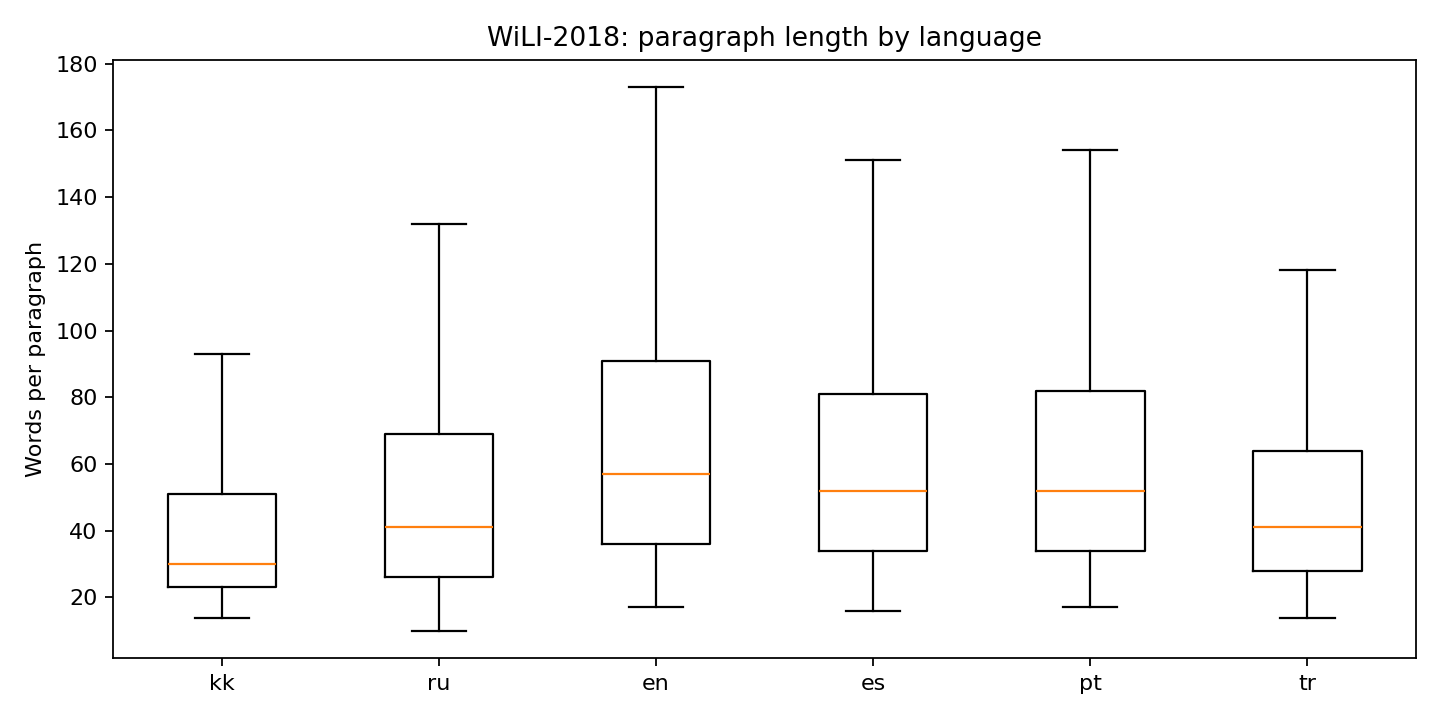

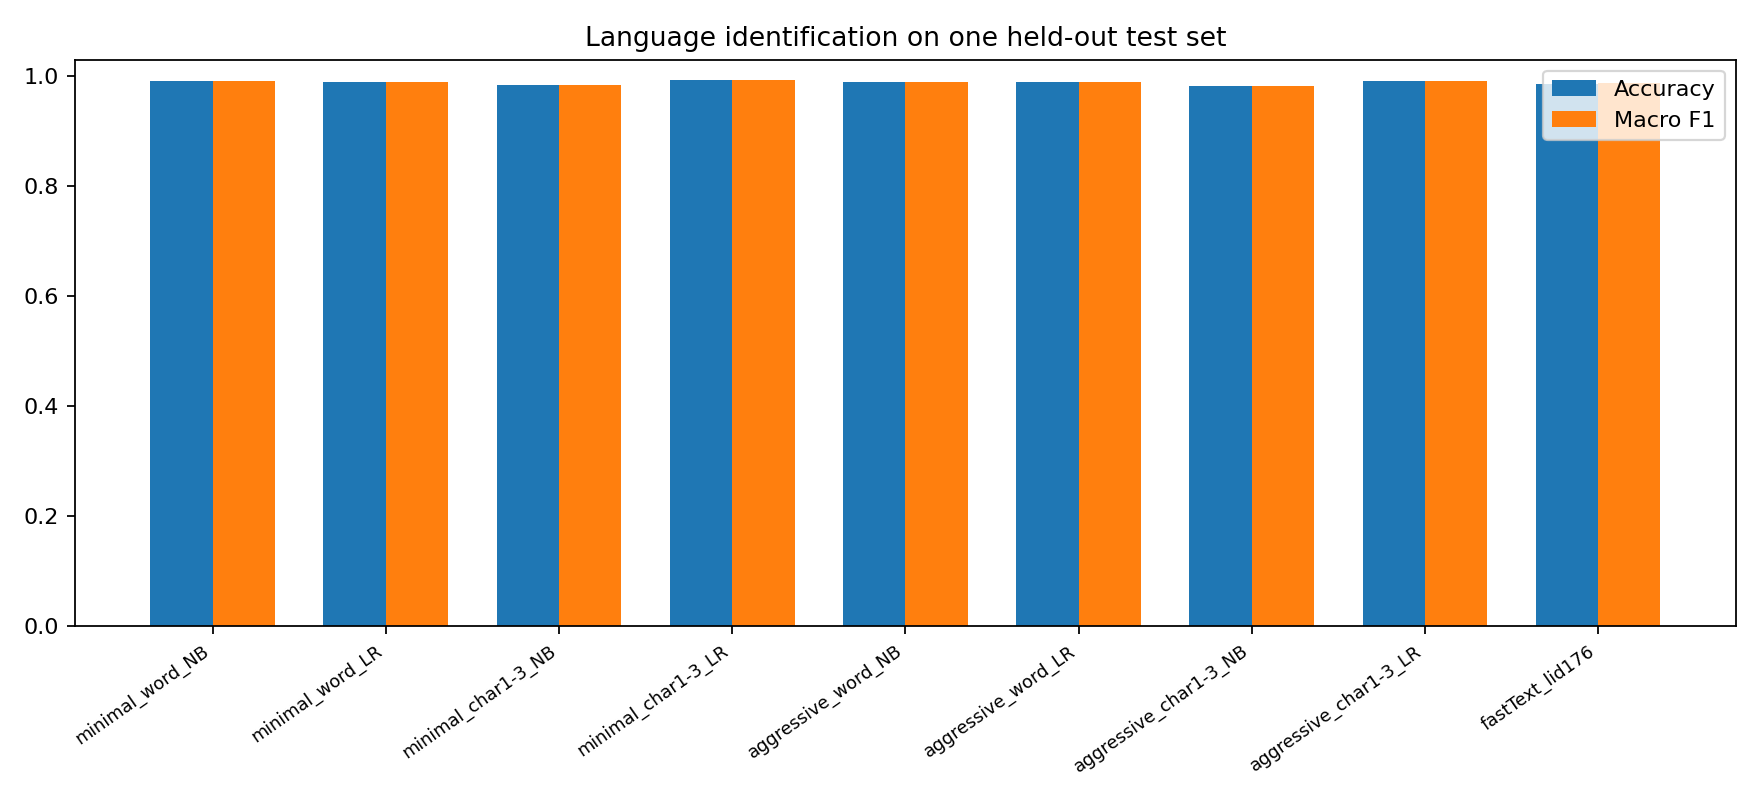

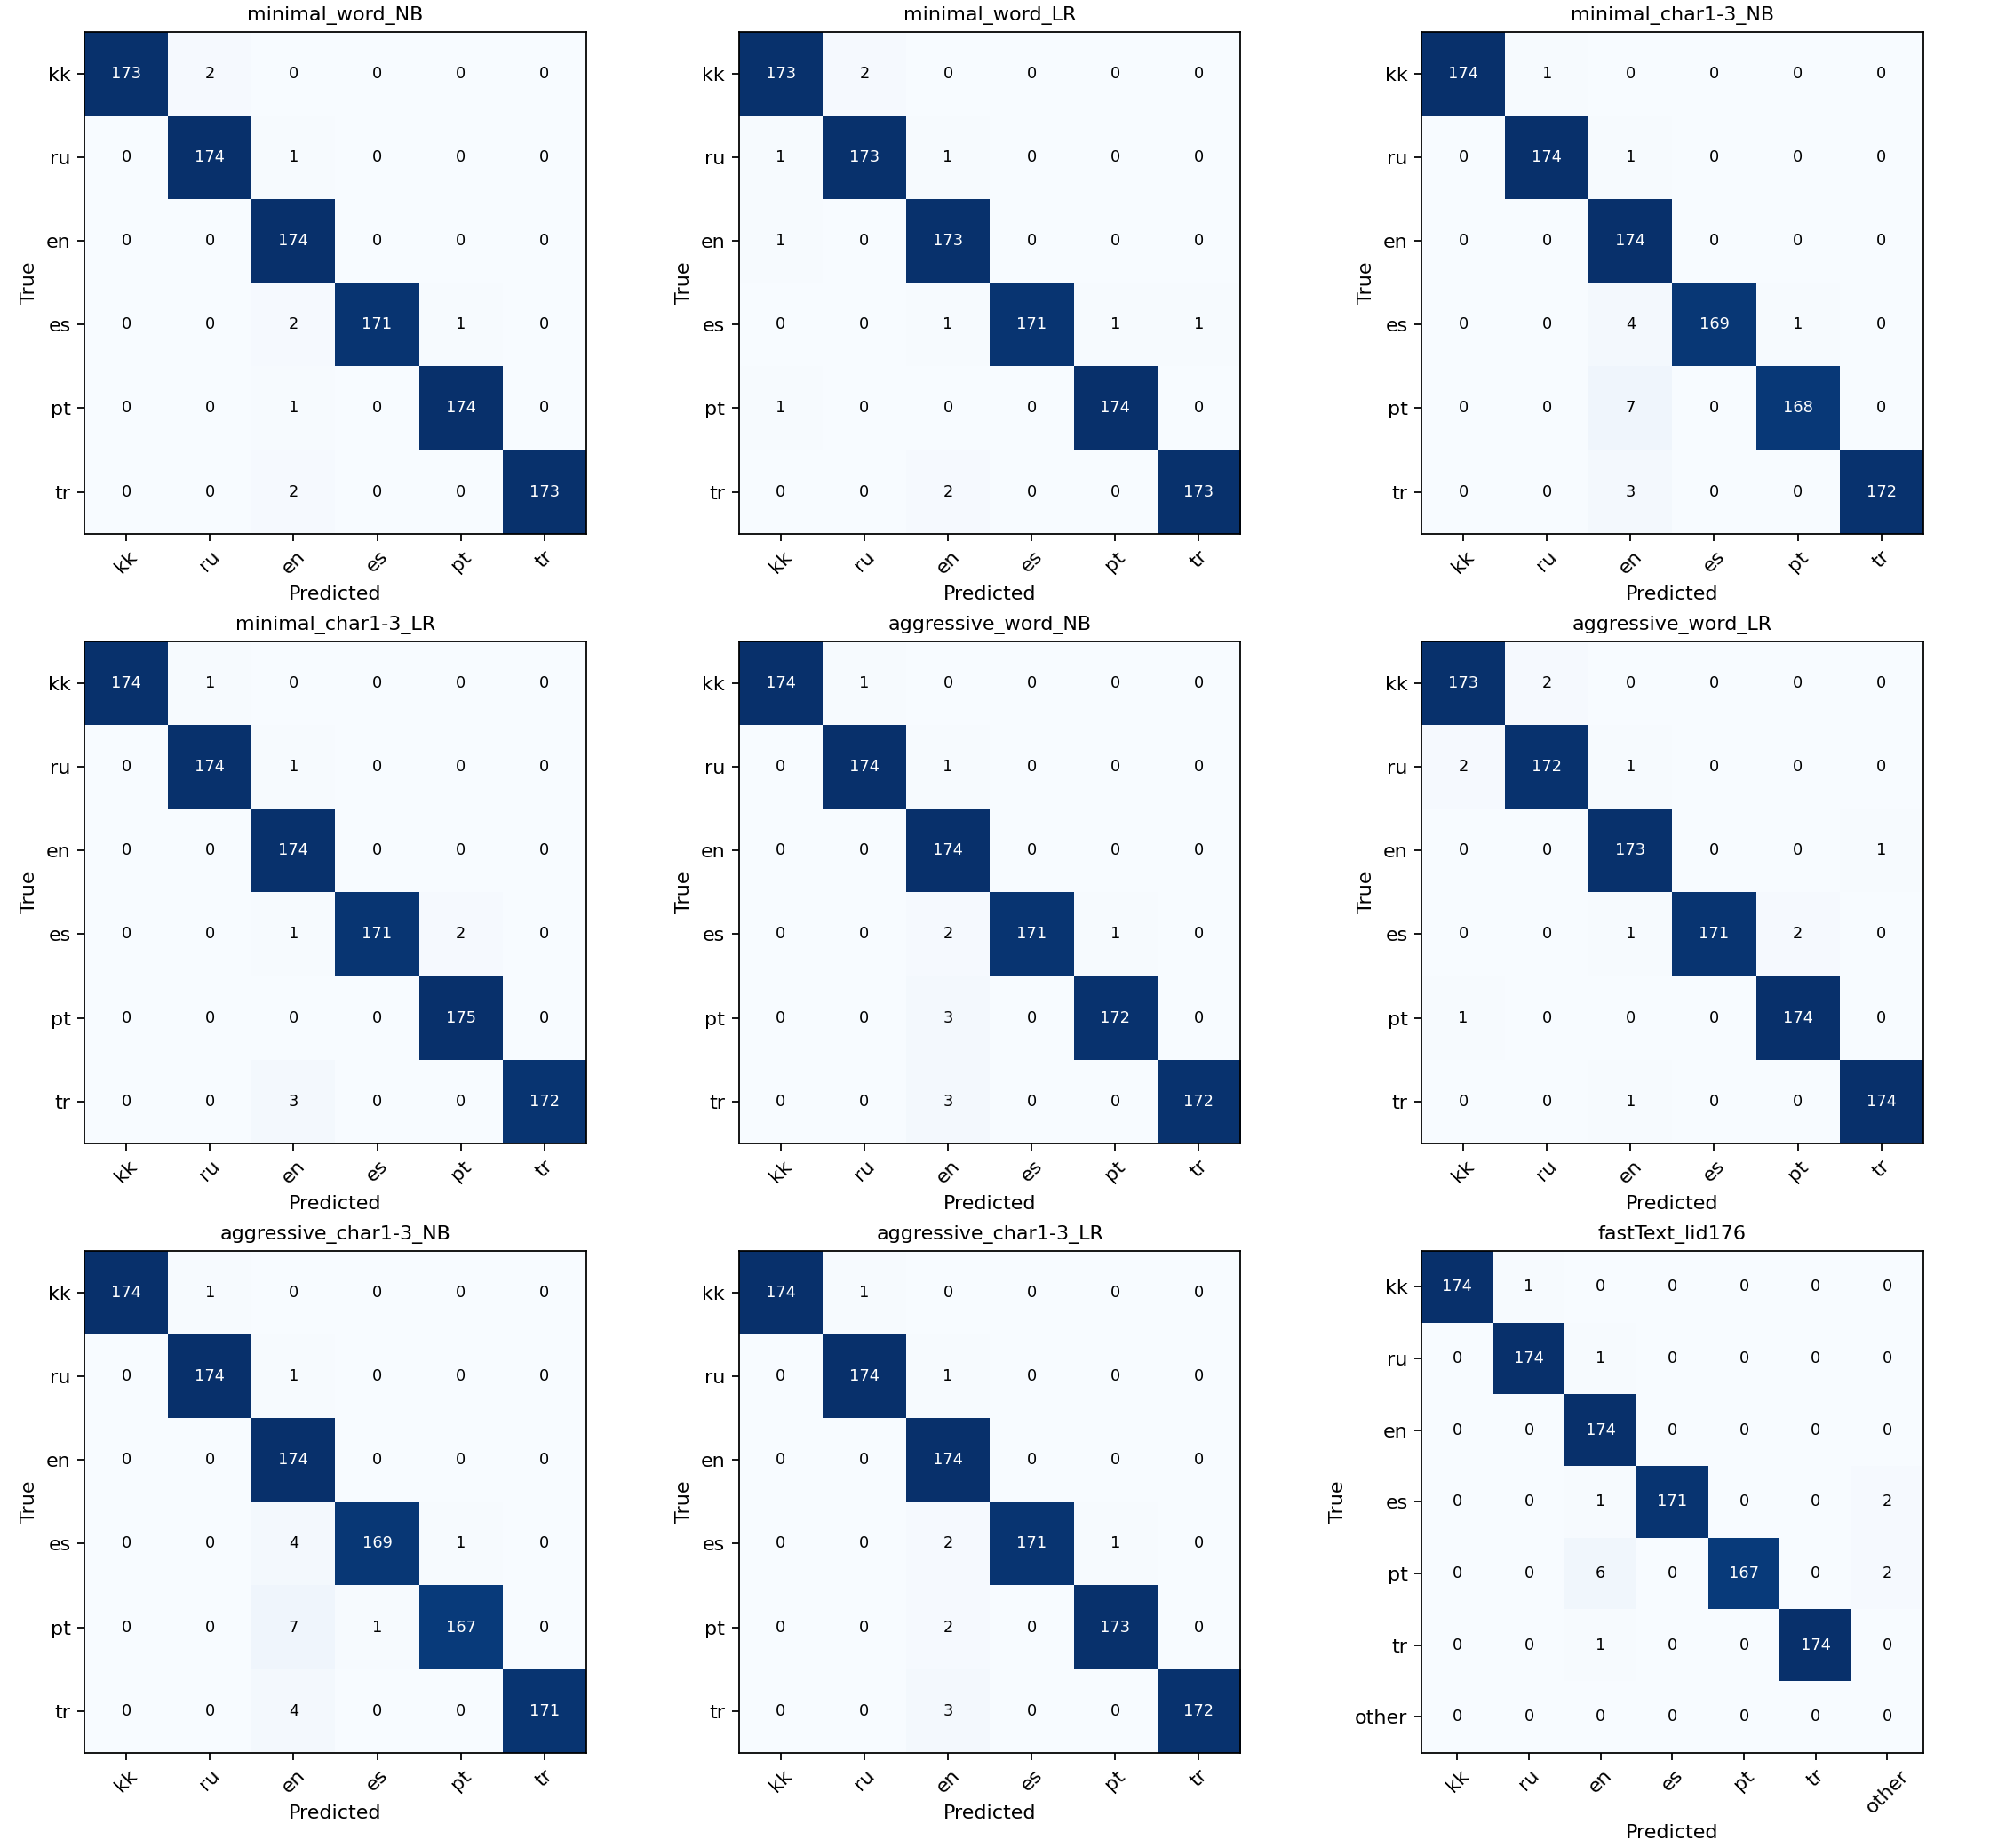

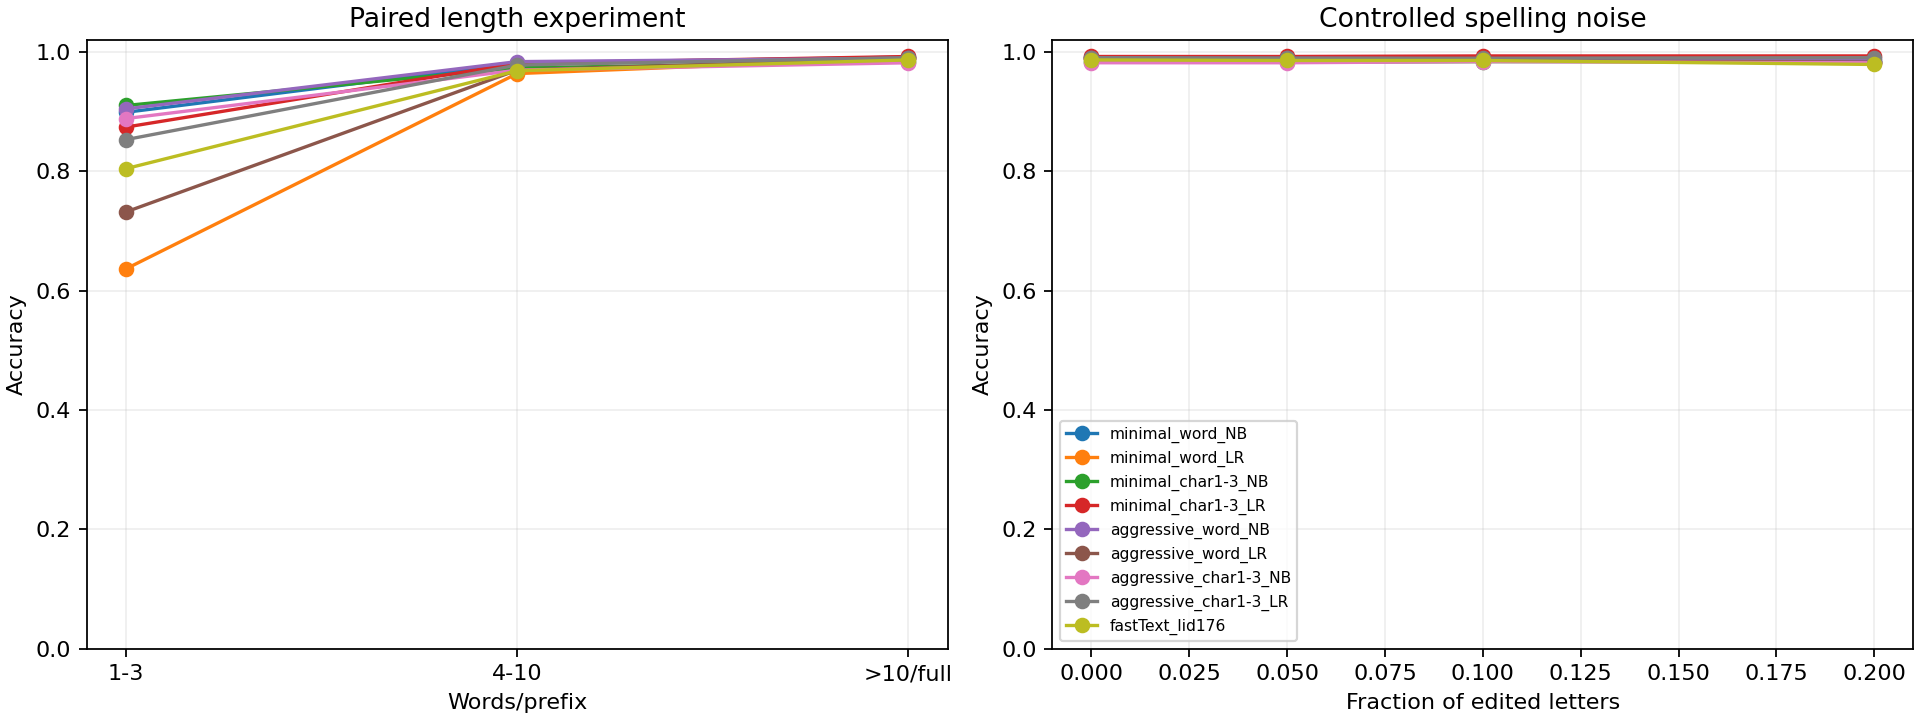

## Подготовка к устной защите

ASSIGNMENT 3. NLP: ПОДГОТОВКА К ЗАЩИТЕ

1. Словарный метод суммирует заранее заданные оценки слов с правилами для
отрицаний и усилителей. TF-IDF + ML учится связывать частоты признаков с метками.
Transformer использует контекстные представления, полученные при предобучении.
Готовая модель может ошибаться при смене предметной области.

2. TF-IDF повышает вес слова, частого в документе, но редкого во всём обучающем
корпусе. В scikit-learn с smooth_idf: idf(t)=log((1+n)/(1+df(t)))+1; затем
применяется нормировка. Векторы разреженные, порядок слов ограниченно отражают
только добавленные n-граммы.

3. Train нужен для обучения параметров и словаря TF-IDF. Validation нужен для
выбора настроек. Test нужен для итоговой оценки. Выбор модели по test завышает
оценку качества. Пересекающиеся дубликаты также создают утечку.

4. Accuracy - доля правильных ответов. Macro F1 - среднее F1 по классам с
одинаковым весом каждого класса. При дисбалансе высокая accuracy может скрывать
слабое распознавание небольшого класса. F1=2PR/(P+R).

5. Матрица ошибок показывает истинные классы по строкам и предсказанные по
столбцам. Диагональ содержит правильные ответы; остальные клетки показывают,
какие классы модель путает.

6. Токенизация определяет единицу признаков: слово, подслово или символ.
Например, разбиение don't с потерей not уничтожает отрицание. У Transformer
нужно использовать его собственный токенизатор.

7. Стоп-слова not, no, never меняют тональность. Пунктуация и регистр также
используются VADER. Поэтому ему передаётся исходный текст; для TF-IDF отдельно
проверяется более сильная нормализация с сохранением отрицаний.

8. Экстрактивное резюме выбирает исходные предложения. Абстрактивное генерирует
новые формулировки и может объединять сведения, но может вводить ошибки.

9. TextRank строит граф предложений с весами сходства. Алгоритм PageRank
оценивает центральность предложений. Высокую оценку получают предложения,
связанные с другими важными предложениями. Это не обучение на метках.

10. ROUGE-1 сравнивает униграммы, ROUGE-2 - биграммы, ROUGE-L - наибольшую
общую подпоследовательность токенов. В работе сравниваются F1-варианты метрик.
Лексическое совпадение не доказывает фактическую правильность резюме.

11. Галлюцинация - информация, которую сгенерировала модель и которую источник
не подтверждает. Беглый, грамматически правильный текст тоже может содержать
неверное имя, число или причинно-следственную связь.

12. Абстрактивная модель создаёт новые предложения. Поэтому нужно сопоставлять
её утверждения с источниками: имена, числа, отношения и оговорки. ROUGE для
такой проверки недостаточно.

13. Частота показывает число употреблений слова. TF-IDF учитывает также, во
скольких документах оно встречается. Редкое слово может быть опечаткой и не
быть полезным признаком жанра.

14. Чем больше и разнообразнее данные, тем устойчивее оценка параметров и тем
лучше покрыты редкие варианты языка. Маленькая тестовая выборка даёт большую
неопределённость. Объём не заменяет качество разметки и отсутствие дубликатов.

15. При дисбалансе модель может предпочитать большой класс. Помогают
стратификация, class_weight, отчёты по каждому классу и Macro F1. Балансировка
до разбиения с копированием примеров может создать утечку.

16. Символьные n-граммы - последовательности из n символов. Например, для
слова язык биграммы: яз, зы, ык. Они отражают окончания, орфографию и алфавит,
а также частично работают для слов, которых не было в train.

17. Казахские ә, ғ, қ, ң, ө, ұ, ү, һ, і - полезные признаки. Регулярное
выражение [a-z] уничтожает их. В идентификации языка используется Unicode
isalpha, поэтому допустимые буквы сохраняются при обеих стратегиях очистки.

18. В коротком тексте мало признаков. Имена, заимствования и общие слова
могут встречаться в нескольких языках. Уверенность модели не является
автоматически калиброванной вероятностью истинности ответа.

19. Code-switching - использование нескольких языков внутри одного текста.
Одна метка не описывает такой текст полностью. Для смешанных казахско-русских
примеров проводится качественный анализ, а не обычная single-label accuracy.

20. Опечатки разрушают знакомые словесные признаки. Символьные n-граммы
могут сохранить часть информации. Шум в работе воспроизводим: фиксируются
seed, частота и тип редактирования; сравниваются те же тестовые примеры.

21. Data leakage - использование информации о test при обучении или выборе
настроек. Примеры: общий словарь TF-IDF до разбиения, дубликаты между частями,
подбор порога на test, песни одного исполнителя в train и test. Поэтому
разбиение выполняется до fit, дополнительно проверяются группы исполнителей.

22. Transformer использует контекст и перенос знаний с больших корпусов.
Ограничения: ресурсы, максимальная длина входа, смена домена, возможное
пересечение с предобучением и галлюцинации при генерации. Большая модель
не гарантирует лучшего результата в конкретном эксперименте.

23. Разные метрики отвечают на разные вопросы. Accuracy отражает общую долю
правильных ответов, Macro F1 учитывает каждый класс одинаково, матрица ошибок
выявляет направления путаницы. У ROUGE другая задача - сравнение резюме.

24. Анализ конкретных ошибок показывает проблемы отрицаний, контекста,
двусмысленной разметки, доменного сдвига и короткого текста. Возможную причину
ошибки следует отличать от доказанной причинной связи.

25. Для воспроизводимости сохраняются источники, лицензии, SHA-256 файлов,
выбранные записи и разбиения, seed=42, версии библиотек и настройки моделей.
Исполняемый код и реальные таблицы результатов позволяют проверить выводы.
Детерминизм на другой версии библиотеки или устройстве может быть неполным.

КАК ДЕМОНСТРИРОВАТЬ РАБОТУ
Откройте Assignment_3_NLP.ipynb, покажите постановку каждой задачи, источники,
разбиения, таблицу метрик, матрицу ошибок и разбор конкретных ошибок.
Перед защитой проверьте, что можете объяснить каждый используемый метод и
воспроизвести запуск по README.txt. Итоговые числа находятся в самом ноутбуке.


## Что проверено

Все кодовые ячейки выполнены в Python. После ручной проверки ошибок соответствующие таблицы выполнены повторно. Числа в таблицах получены вычислениями, графики построены из этих результатов. Источники и возможное пересечение с предобучением обсуждаются в разделах заданий.